# Πρόβλεψη αποχώρησης πελατών
## Εργασία στο μάθημα Neural Nets & Deep Learning — AI105

### 1. Εισαγωγή

Οι εταιρείες τηλεπικοινωνιών θέλουν να γνωρίζουν ποιοι πελάτες είναι πιθανό να διακόψουν τις υπηρεσίες τους. Αυτή η πληροφορία μπορεί να τις βοηθήσει να εντοπίσουν έγκαιρα πελάτες που κινδυνεύουν να χάσουν και να οργανώσουν ενέργειες για να τους διατηρήσουν.

Στην εργασία χρησιμοποιούμε το σύνολο δεδομένων Telco Customer Churn, το οποίο περιλαμβάνει στοιχεία για τους πελάτες, τις υπηρεσίες που χρησιμοποιούν, τα συμβόλαια και τις χρεώσεις τους. Στόχος μας είναι να εξετάσουμε κατά πόσο αυτά τα στοιχεία μπορούν να χρησιμοποιηθούν για την πρόβλεψη της αποχώρησης ενός πελάτη.

Αρχικά θα ελέγξουμε και θα προετοιμάσουμε τα δεδομένα. Στη συνέχεια θα δημιουργήσουμε ένα μοντέλο λογιστικής παλινδρόμησης και ένα νευρωνικό δίκτυο, ενώ θα χρησιμοποιήσουμε και πρόσθετα μοντέλα για σύγκριση. Τέλος, θα αξιολογήσουμε τα αποτελέσματα και θα εξετάσουμε πώς μπορούν να βοηθήσουν την εταιρεία στην πράξη.

**Σχετικά με αυτή την έκδοση:** διατηρούνται οι ρυθμίσεις και τα αποθηκευμένα αποτελέσματα της αρχικής αναζήτησης Optuna (20 δοκιμές). Βελτιώθηκαν τα σχόλια και οι επεξηγήσεις. Οι εμφανιζόμενοι πίνακες και τα γραφήματα προέρχονται από την προηγούμενη εκτέλεση του αρχικού πειράματος, όχι από νέα εκπαίδευση αυτής της έκδοσης. Για επανάληψη χρησιμοποιούμε Restart Kernel και Run All, με το CSV στον φάκελο Dataset. Δεν αποθηκεύονται εξωτερικά αρχεία αποτελεσμάτων ή μοντέλων.


In [1]:
from pathlib import Path

import pandas as pd

# Η διαδρομή του αρχείου με τα δεδομένα
data_path = Path("Dataset") / "WA_Fn-UseC_-Telco-Customer-Churn.csv"

# Ελέγχουμε αν το αρχείο υπάρχει στον σωστό φάκελο
if not data_path.is_file():
    raise FileNotFoundError(
        f"Δεν βρέθηκε το αρχείο: {data_path.resolve()}"
    )

# Διαβάζουμε τα δεδομένα χωρίς να αλλάξουμε το αρχικό CSV
df = pd.read_csv(data_path)

print(f"Αριθμός πελατών: {df.shape[0]}")
print(f"Αριθμός στηλών: {df.shape[1]}")

# Εμφανίζουμε τις πρώτες πέντε εγγραφές
df.head()


Αριθμός πελατών: 7043
Αριθμός στηλών: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 2. Αρχικός έλεγχος των δεδομένων

Αρχικά ελέγχουμε το μέγεθος του συνόλου δεδομένων και τον τύπο κάθε στήλης. Τα δεδομένα περιλαμβάνουν 7.043 πελάτες και 21 στήλες.

Η στήλη Churn δείχνει αν ο πελάτης αποχώρησε και αποτελεί τη μεταβλητή που θέλουμε να προβλέψουμε. Το customerID είναι το μοναδικό αναγνωριστικό κάθε πελάτη.

Η στήλη TotalCharges έχει διαβαστεί ως κείμενο, παρότι περιέχει ποσά χρεώσεων. Θα ελέγξουμε αν υπάρχουν κενές ή μη αριθμητικές τιμές, καθώς και αν υπάρχουν διπλές εγγραφές.


In [2]:
# Ελέγχουμε τις στήλες, τους τύπους δεδομένων και τις μη κενές τιμές
df.info()  # Βλέπουμε τους τύπους των στηλών και πόσες τιμές λείπουν.


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
# Ελέγχουμε για διπλές εγγραφές και επαναλαμβανόμενα αναγνωριστικά
print("Διπλές εγγραφές:", df.duplicated().sum())
print("Διπλά customerID:", df["customerID"].duplicated().sum())

# Εντοπίζουμε τιμές που περιέχουν μόνο κενά διαστήματα
blank_charges = df["TotalCharges"].str.strip().eq("")
print("Κενές συνολικές χρεώσεις:", blank_charges.sum())

# Δοκιμάζουμε τη μετατροπή σε αριθμούς χωρίς να αλλάξουμε τη στήλη
numeric_charges = pd.to_numeric(df["TotalCharges"], errors="coerce")

print(
    "Ελλιπείς ή μη αριθμητικές συνολικές χρεώσεις:",
    numeric_charges.isna().sum()
)

# Βλέπουμε τους πελάτες που χρειάζονται έλεγχο
df.loc[
    numeric_charges.isna(),
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
]


Διπλές εγγραφές: 0
Διπλά customerID: 0
Κενές συνολικές χρεώσεις: 11
Ελλιπείς ή μη αριθμητικές συνολικές χρεώσεις: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


### 3. Προετοιμασία της στήλης TotalCharges

Ο έλεγχος δεν εντόπισε διπλές εγγραφές ή επαναλαμβανόμενα αναγνωριστικά πελατών. Εντοπίστηκαν όμως 11 κενές τιμές στη στήλη TotalCharges, όλες σε πελάτες με διάρκεια συνεργασίας μηδέν μηνών.

Μετατρέπουμε τη στήλη σε αριθμητική και διατηρούμε τις κενές τιμές ως ελλιπείς. Δεν αφαιρούμε τους πελάτες και δεν θεωρούμε ότι οι χρεώσεις τους είναι απαραίτητα μηδενικές.

Μετά τον διαχωρισμό των δεδομένων, θα συμπληρώσουμε τις τιμές αυτές με τη διάμεσο που θα υπολογίσουμε μόνο από το σύνολο εκπαίδευσης. Έτσι, τα δεδομένα αξιολόγησης δεν θα επηρεάσουν την προεπεξεργασία.


In [4]:
# Δημιουργούμε αντίγραφο για την προετοιμασία των δεδομένων
df_clean = df.copy()  # Κρατάμε τα αρχικά δεδομένα ανέπαφα.

# Μετατρέπουμε τις συνολικές χρεώσεις σε αριθμούς
# Οι κενές τιμές μετατρέπονται σε NaN
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"  # Ό,τι δεν μπορεί να γίνει αριθμός γίνεται κενή τιμή (NaN).
)

print("Τύπος στήλης TotalCharges:", df_clean["TotalCharges"].dtype)
print("Ελλιπείς τιμές:", df_clean["TotalCharges"].isna().sum())
print("Αριθμός πελατών:", len(df_clean))


Τύπος στήλης TotalCharges: float64
Ελλιπείς τιμές: 11
Αριθμός πελατών: 7043


### 4. Διαχωρισμός των δεδομένων

Χωρίζουμε τα δεδομένα σε τρία σύνολα: 70% για training, 15% για validation και 15% για τελικό έλεγχο.

Το σύνολο εκπαίδευσης χρησιμοποιείται για να μάθουν τα μοντέλα και για να υπολογιστούν οι μετασχηματισμοί προεπεξεργασίας, όπως η συμπλήρωση ελλιπών τιμών και η τυποποίηση.

Το σύνολο επικύρωσης (validation) χρησιμοποιείται για την επιλογή των ρυθμίσεων των μοντέλων. Το σύνολο τελικού ελέγχου παραμένει στην άκρη μέχρι να ολοκληρωθούν αυτές οι επιλογές.

Διατηρούμε περίπου την ίδια αναλογία πελατών που αποχώρησαν και παρέμειναν σε κάθε σύνολο. Χρησιμοποιούμε επίσης σταθερό random_state, ώστε ο διαχωρισμός να μπορεί να επαναληφθεί.

Αφαιρούμε το customerID από τα χαρακτηριστικά, καθώς είναι αναγνωριστικό πελάτη. Η στήλη αποχώρηση (Churn) αποτελεί τον στόχο: 0 σημαίνει ότι ο πελάτης παρέμεινε και 1 ότι αποχώρησε.


In [5]:
%pip install scikit-learn

from sklearn.model_selection import train_test_split

# Τα χαρακτηριστικά που θα χρησιμοποιούν τα μοντέλα
X = df_clean.drop(columns=["customerID", "Churn"])

# Η μεταβλητή που θέλουμε να προβλέψουμε
y = df_clean["Churn"].map({"No": 0, "Yes": 1})

# Κρατάμε το 70% για εκπαίδευση και το 30% για τον δεύτερο διαχωρισμό
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,  # Το 30% μένει για validation και test.
    random_state=42,  # Σταθερή αρχική τιμή για να επαναλαμβάνεται το πείραμα.
    stratify=y  # Κρατάμε παρόμοια αναλογία αποχώρησης στα δύο σύνολα.
)

# Χωρίζουμε το υπόλοιπο 30% σε δύο περίπου ίσα μέρη
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,  # Μοιράζουμε το υπόλοιπο 30% στη μέση.
    random_state=42,
    stratify=y_temp  # Κρατάμε παρόμοια αναλογία και σε validation και test.
)

# Ελέγχουμε το μέγεθος και την αναλογία αποχώρησης κάθε συνόλου
split_summary = pd.DataFrame({
    "Σύνολο": ["Εκπαίδευσης", "Επικύρωσης", "Τελικού ελέγχου"],
    "Πελάτες": [len(X_train), len(X_val), len(X_test)],
    "Ποσοστό αποχώρησης (%)": [
        y_train.mean() * 100,
        y_val.mean() * 100,
        y_test.mean() * 100
    ]
})

split_summary.round(2)


Note: you may need to restart the kernel to use updated packages.


,Σύνολο,Πελάτες,Ποσοστό αποχώρησης (%)
0,Εκπαίδευσης,4930,26.53
1,Επικύρωσης,1056,26.52
2,Τελικού ελέγχου,1057,26.58


### 5. EDA - Διερευνητική ανάλυση των δεδομένων εκπαίδευσης

Εξετάζουμε τα δεδομένα εκπαίδευσης για να κατανοήσουμε τα χαρακτηριστικά των πελατών και τη σχέση τους με την αποχώρηση.

Αρχικά ελέγχουμε πόσοι πελάτες παρέμειναν και πόσοι αποχώρησαν. Στη συνέχεια εξετάζουμε τη διάρκεια συνεργασίας και τις χρεώσεις. Τα σύνολα επικύρωσης και τελικού ελέγχου δεν χρησιμοποιούνται σε αυτή την ανάλυση.


In [6]:
# Δημιουργούμε έναν πίνακα για την ανάλυση του συνόλου εκπαίδευσης
train_data = X_train.copy()
train_data["Churn"] = y_train

# Μετράμε τους πελάτες κάθε κατηγορίας
churn_counts = train_data["Churn"].value_counts().reindex([0, 1])

churn_summary = pd.DataFrame({
    "Κατηγορία": ["Παρέμειναν", "Αποχώρησαν"],
    "Πελάτες": churn_counts.to_numpy(),
    "Ποσοστό (%)": (
        churn_counts / len(train_data) * 100
    ).to_numpy()
})

churn_summary.round(2)


,Κατηγορία,Πελάτες,Ποσοστό (%)
0,Παρέμειναν,3622,73.47
1,Αποχώρησαν,1308,26.53


In [7]:
# Βασικά στατιστικά για τη διάρκεια συνεργασίας και τις χρεώσεις
numeric_columns = ["tenure", "MonthlyCharges", "TotalCharges"]

train_data[numeric_columns].describe().round(2)


,tenure,MonthlyCharges,TotalCharges
count,4930.00,4930.00,4923.00
mean,32.47,64.95,2305.07
std,24.65,30.24,2292.55
min,0.00,18.40,18.85
25%,9.00,35.50,399.80
50%,29.00,70.57,1389.20
75%,56.00,90.05,3860.30
max,72.00,118.75,8684.80


#### Πρώτες παρατηρήσεις

Στο σύνολο εκπαίδευσης, το 73,47% των πελατών παρέμεινε στην εταιρεία και το 26,53% αποχώρησε. Επομένως, η αξιολόγηση των μοντέλων δεν μπορεί να βασιστεί μόνο στην accuracy, καθώς οι πελάτες που παρέμειναν είναι σαφώς περισσότεροι.

Η διάμεση διάρκεια συνεργασίας είναι 29 μήνες και η μέση μηνιαία χρέωση είναι 64,95. Οι συνολικές χρεώσεις παρουσιάζουν μεγάλες διαφορές μεταξύ των πελατών: η μέση τιμή είναι 2.305,07, ενώ η διάμεσος είναι 1.389,20.

Στη στήλη TotalCharges υπάρχουν 7 ελλιπείς τιμές στο σύνολο εκπαίδευσης. Θα συμπληρωθούν κατά την προεπεξεργασία.


In [8]:
# Ομαδοποιούμε τους πελάτες με βάση τον τύπο συμβολαίου
contract_summary = (
    train_data.groupby("Contract")["Churn"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Πελάτες",
        "sum": "Αποχωρήσεις",
        "mean": "Ποσοστό αποχώρησης (%)"
    })
)

# Επειδή η θητεία(Churn) είναι 0 ή 1, ο μέσος όρος του δίνει
# την αναλογία των πελατών που αποχώρησαν
contract_summary["Ποσοστό αποχώρησης (%)"] *= 100

contract_summary.index = contract_summary.index.map({
    "Month-to-month": "Μηνιαίο",
    "One year": "Ετήσιο",
    "Two year": "Διετές"
})
contract_summary.index.name = "Συμβόλαιο"

contract_summary.round(2)


,Πελάτες,Αποχωρήσεις,Ποσοστό αποχώρησης (%)
Συμβόλαιο,,,
Μηνιαίο,2704,1159,42.86
Ετήσιο,1034,113,10.93
Διετές,1192,36,3.02


#### Αποχώρηση ανά τύπο συμβολαίου

Στα δεδομένα εκπαίδευσης, οι πελάτες με μηνιαίο συμβόλαιο παρουσιάζουν το υψηλότερο ποσοστό αποχώρησης, 42,86%. Το αντίστοιχο ποσοστό είναι 10,93% για τα ετήσια συμβόλαια και 3,02% για τα διετή.

Η διαφορά δείχνει ότι ο τύπος συμβολαίου σχετίζεται με την αποχώρηση και μπορεί να βοηθήσει τα μοντέλα στην πρόβλεψή της. Ωστόσο, η σύγκριση αυτή δεν αποδεικνύει αιτιώδη σχέση, καθώς δεν λαμβάνει υπόψη τα υπόλοιπα χαρακτηριστικά των πελατών.


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


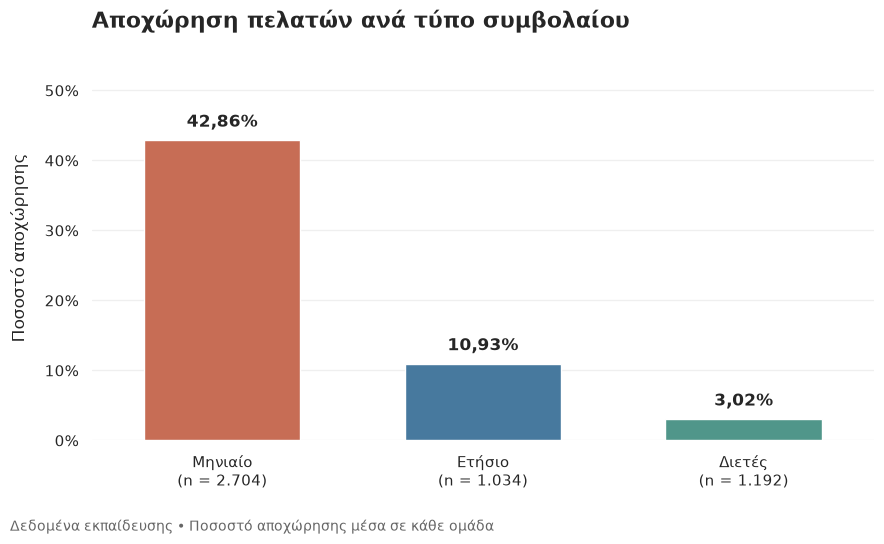

In [9]:
%pip install matplotlib
%pip install seaborn

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from pathlib import Path

# Απλό στυλ, με γραμματοσειρά που υποστηρίζει ελληνικά
sns.set_theme(
    style="whitegrid",
    context="notebook",
    font="DejaVu Sans"
)


# Μετατρέπουμε το όνομα του συμβολαίου σε κανονική στήλη
plot_data = contract_summary.reset_index()
order = ["Μηνιαίο", "Ετήσιο", "Διετές"]

colors = {
    "Μηνιαίο": "#C76D55",
    "Ετήσιο": "#47799E",
    "Διετές": "#50968A"
}

fig, ax = plt.subplots(figsize=(9, 5.5))

sns.barplot(
    data=plot_data,
    x="Συμβόλαιο",
    y="Ποσοστό αποχώρησης (%)",
    hue="Συμβόλαιο",
    order=order,
    hue_order=order,
    palette=colors,
    dodge=False,
    legend=False,
    errorbar=None,
    saturation=1,
    width=0.6,
    ax=ax
)

# Προσθέτουμε τις ακριβείς τιμές πάνω από τις μπάρες
for container in ax.containers:
    labels = [
        f"{bar.get_height():.2f}%".replace(".", ",")
        for bar in container
    ]
    ax.bar_label(
        container,
        labels=labels,
        padding=7,
        fontsize=12,
        fontweight="bold"
    )

ax.set_title(
    "Αποχώρηση πελατών ανά τύπο συμβολαίου",
    fontsize=16,
    fontweight="bold",
    loc="left",
    pad=20
)

ax.set_xlabel("")
ax.set_ylabel("Ποσοστό αποχώρησης", labelpad=12)
ax.set_ylim(0, 55)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))

# Κρατάμε μόνο τις οριζόντιες γραμμές του πλέγματος
ax.grid(axis="x", visible=False)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
sns.despine(ax=ax, left=True, bottom=True)

# Εμφανίζουμε το μέγεθος κάθε ομάδας κάτω από τον τύπο συμβολαίου
customer_counts = plot_data.set_index("Συμβόλαιο")["Πελάτες"]

ax.set_xticks(range(len(order)))
ax.set_xticklabels([
    f"{contract}\n(n = {int(customer_counts[contract]):,})".replace(",", ".")
    for contract in order
])

fig.text(
    0.02, 0.02,
    "Δεδομένα εκπαίδευσης • Ποσοστό αποχώρησης μέσα σε κάθε ομάδα",
    fontsize=10,
    color="#666666"
)

fig.tight_layout(rect=[0, 0.06, 1, 1])

plt.show()  # Εμφανίζουμε το γράφημα μέσα στο notebook.


#### Διάρκεια συνεργασίας και χρεώσεις ανά κατηγορία πελάτη

Συγκρίνουμε τη διάρκεια συνεργασίας, τη μηνιαία χρέωση και τη συνολική χρέωση μεταξύ των πελατών που παρέμειναν και εκείνων που αποχώρησαν.

Χρησιμοποιούμε boxplots για να εξετάσουμε τη διάμεσο και τη διασπορά των τιμών κάθε ομάδας. Η ανάλυση αφορά μόνο τα δεδομένα εκπαίδευσης. Οι ελλιπείς συνολικές χρεώσεις δεν συμμετέχουν στο αντίστοιχο γράφημα.


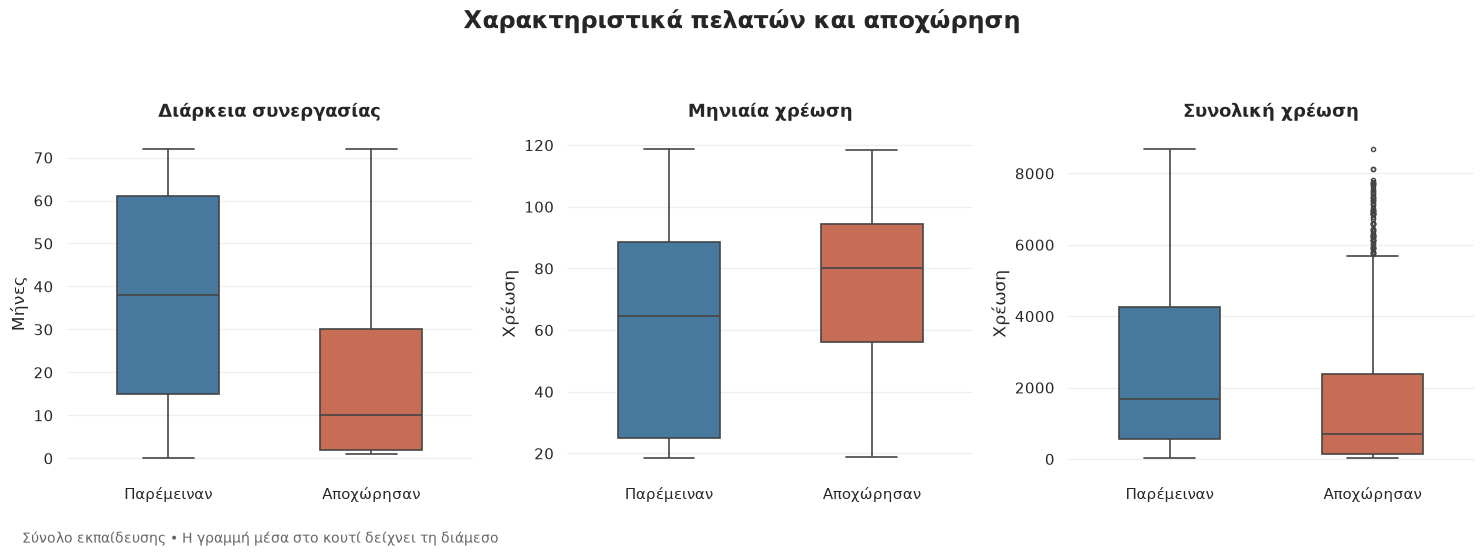

In [10]:
# Δημιουργούμε αντίγραφο με ελληνικές ονομασίες για το γράφημα
plot_data = train_data.copy()
plot_data["Κατηγορία"] = plot_data["Churn"].map({
    0: "Παρέμειναν",
    1: "Αποχώρησαν"
})

category_order = ["Παρέμειναν", "Αποχώρησαν"]
category_colors = {
    "Παρέμειναν": "#47799E",
    "Αποχώρησαν": "#C76D55"
}

# Κάθε μεταβλητή έχει διαφορετική κλίμακα
plots = [
    ("tenure", "Διάρκεια συνεργασίας", "Μήνες"),
    ("MonthlyCharges", "Μηνιαία χρέωση", "Χρέωση"),
    ("TotalCharges", "Συνολική χρέωση", "Χρέωση")
]

fig, axes = plt.subplots(figsize=(15, 5.5), ncols=3)

for ax, (column, title, ylabel) in zip(axes, plots):
    sns.boxplot(
        data=plot_data,
        x="Κατηγορία",
        y=column,
        hue="Κατηγορία",
        order=category_order,
        hue_order=category_order,
        palette=category_colors,
        dodge=False,
        legend=False,
        width=0.5,
        saturation=1,
        fliersize=3,
        linewidth=1.2,
        ax=ax
    )

    ax.set_title(title, fontsize=13, fontweight="bold", pad=12)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.grid(axis="x", visible=False)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    sns.despine(ax=ax, left=True, bottom=True)

fig.suptitle(
    "Χαρακτηριστικά πελατών και αποχώρηση",
    fontsize=17,
    fontweight="bold",
    y=0.99
)

fig.text(
    0.02, 0.02,
    "Σύνολο εκπαίδευσης • Η γραμμή μέσα στο κουτί δείχνει τη διάμεσο",
    fontsize=10,
    color="#666666"
)

fig.tight_layout(rect=[0, 0.06, 1, 0.93])

plt.show()  # Εμφανίζουμε το γράφημα μέσα στο notebook.


In [11]:
median_summary = (
    plot_data.groupby("Κατηγορία")[
        ["tenure", "MonthlyCharges", "TotalCharges"]
    ]
    .median()
    .reindex(category_order)
    .rename(columns={
        "tenure": "Διάμεση διάρκεια (μήνες)",
        "MonthlyCharges": "Διάμεση μηνιαία χρέωση",
        "TotalCharges": "Διάμεση συνολική χρέωση"
    })
)

median_summary.round(2)


,Διάμεση διάρκεια (μήνες),Διάμεση μηνιαία χρέωση,Διάμεση συνολική χρέωση
Κατηγορία,,,
Παρέμειναν,38.0,64.45,1679.40
Αποχώρησαν,10.0,80.00,705.08


#### Παρατηρήσεις για τη διάρκεια συνεργασίας και τις χρεώσεις

Οι πελάτες που αποχώρησαν είχαν διάμεση διάρκεια συνεργασίας 10 μήνες, ενώ όσοι παρέμειναν είχαν 38 μήνες. Παράλληλα, η διάμεση μηνιαία χρέωση ήταν υψηλότερη για όσους αποχώρησαν: 80,00 έναντι 64,45.

Η διάμεση συνολική χρέωση ήταν χαμηλότερη στους πελάτες που αποχώρησαν, 705,08 έναντι 1.679,40. Αυτό ταιριάζει με τη μικρότερη διάρκεια συνεργασίας τους: είχαν λιγότερο χρόνο για να συγκεντρώσουν χρεώσεις.

Οι διαφορές αυτές δείχνουν ότι η διάρκεια συνεργασίας και οι χρεώσεις μπορεί να είναι χρήσιμες για την πρόβλεψη. Δεν αποδεικνύουν όμως τις αιτίες αποχώρησης ούτε σημαίνουν ότι όλοι οι πελάτες με παρόμοια χαρακτηριστικά συμπεριφέρονται με τον ίδιο τρόπο.


#### Κατανομές των αριθμητικών χαρακτηριστικών

Εξετάζουμε τις κατανομές της διάρκειας συνεργασίας, της μηνιαίας χρέωσης και της συνολικής χρέωσης στο σύνολο εκπαίδευσης.

Τα ιστογράμματα δείχνουν σε ποια εύρη συγκεντρώνονται οι τιμές και αν οι κατανομές παρουσιάζουν ασυμμετρία. Για τις συνολικές χρεώσεις χρησιμοποιούμε μόνο τις διαθέσιμες τιμές, χωρίς να συμπληρώσουμε ακόμη τις ελλιπείς.


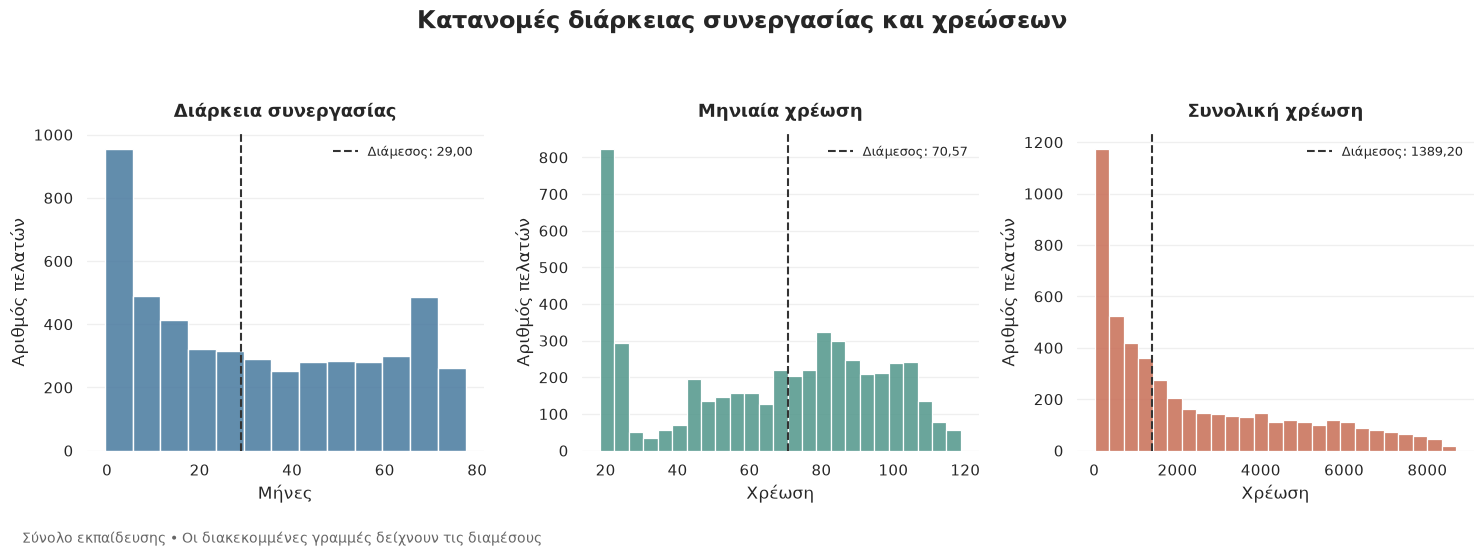

In [12]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

sns.set_theme(
    style="whitegrid",
    context="notebook",
    font="DejaVu Sans"
)


# Για τη διάρκεια χρησιμοποιούμε διαστήματα περίπου έξι μηνών
plot_settings = [
    (
        "tenure",
        "Διάρκεια συνεργασίας",
        "Μήνες",
        np.arange(-0.5, 78, 6),
        "#47799E"
    ),
    (
        "MonthlyCharges",
        "Μηνιαία χρέωση",
        "Χρέωση",
        25,
        "#50968A"
    ),
    (
        "TotalCharges",
        "Συνολική χρέωση",
        "Χρέωση",
        25,
        "#C76D55"
    )
]

fig, axes = plt.subplots(ncols=3, figsize=(15, 5.5))

for ax, (column, title, xlabel, bins, color) in zip(
    axes, plot_settings
):
    # Παραλείπουμε τα κενά μόνο για τη δημιουργία του γραφήματος
    values = train_data[column].dropna()

    sns.histplot(
        x=values,
        bins=bins,
        color=color,
        edgecolor="white",
        alpha=0.85,
        ax=ax
    )

    # Σημειώνουμε τη διάμεσο κάθε χαρακτηριστικού
    median = values.median()
    median_label = f"Διάμεσος: {median:.2f}".replace(".", ",")

    ax.axvline(
        median,
        color="#333333",
        linestyle="--",
        linewidth=1.5,
        label=median_label
    )

    ax.set_title(title, fontsize=13, fontweight="bold", pad=12)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Αριθμός πελατών")
    ax.legend(frameon=False, fontsize=9)

    ax.grid(axis="x", visible=False)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    sns.despine(ax=ax, left=True, bottom=True)

fig.suptitle(
    "Κατανομές διάρκειας συνεργασίας και χρεώσεων",
    fontsize=17,
    fontweight="bold",
    y=0.99
)

fig.text(
    0.02, 0.02,
    "Σύνολο εκπαίδευσης • Οι διακεκομμένες γραμμές δείχνουν τις διαμέσους",
    fontsize=10,
    color="#666666"
)

fig.tight_layout(rect=[0, 0.06, 1, 0.93])

plt.show()  # Εμφανίζουμε το γράφημα μέσα στο notebook.


#### Παρατηρήσεις για τις κατανομές

Η διάρκεια συνεργασίας παρουσιάζει μεγάλη συγκέντρωση στους πρώτους μήνες, αλλά υπάρχουν και αρκετοί πελάτες με πολυετή παραμονή. Η διάμεση διάρκεια είναι 29 μήνες.

Στις μηνιαίες χρεώσεις παρατηρείται έντονη συγκέντρωση γύρω στο 20 και μία ακόμη ευρύτερη συγκέντρωση σε υψηλότερες τιμές. Αυτό μπορεί να σχετίζεται με διαφορετικές υπηρεσίες ή πακέτα, κάτι που δεν μπορεί να επιβεβαιωθεί μόνο από το ιστόγραμμα.

Οι συνολικές χρεώσεις παρουσιάζουν δεξιά ασυμμετρία: οι χαμηλές τιμές είναι συχνότερες, ενώ οι υψηλές εμφανίζονται σε λιγότερους πελάτες. Η εικόνα συμφωνεί με τη διαφορά μεταξύ του μέσου όρου (2.305,07) και της διαμέσου (1.389,20).

Τα συγκεκριμένα ιστογράμματα περιγράφουν συνολικά τους πελάτες του συνόλου εκπαίδευσης και δεν δείχνουν από μόνα τους την πιθανότητα αποχώρησης.


#### Αποχώρηση ανά υπηρεσία και τρόπο πληρωμής

Εξετάζουμε αν το ποσοστό αποχώρησης διαφέρει ανάλογα με την υπηρεσία Internet, την ύπαρξη τεχνικής υποστήριξης και τον τρόπο πληρωμής.

Για κάθε κατηγορία υπολογίζουμε τον αριθμό πελατών, τις αποχωρήσεις και το ποσοστό αποχώρησης. Συγκρίνουμε ποσοστά, επειδή οι ομάδες έχουν διαφορετικό μέγεθος.

Στην τεχνική υποστήριξη διατηρούμε ξεχωριστά τους πελάτες που δεν έχουν υπηρεσία Internet από εκείνους που έχουν Internet αλλά δεν διαθέτουν τεχνική υποστήριξη.

Οι συγκρίσεις δείχνουν σχέσεις μέσα στα δεδομένα και δεν αποδεικνύουν τις αιτίες της αποχώρησης.


In [13]:
from IPython.display import display

# Ονομασίες για την παρουσίαση των αποτελεσμάτων
category_settings = {
    "InternetService": {
        "title": "Υπηρεσία Internet",
        "labels": {
            "DSL": "DSL",
            "Fiber optic": "Οπτική ίνα",
            "No": "Χωρίς Internet"
        }
    },
    "TechSupport": {
        "title": "Τεχνική υποστήριξη",
        "labels": {
            "Yes": "Με τεχνική υποστήριξη",
            "No": "Χωρίς τεχνική υποστήριξη",
            "No internet service": "Χωρίς Internet"
        }
    },
    "PaymentMethod": {
        "title": "Τρόπος πληρωμής",
        "labels": {
            "Electronic check": "Ηλεκτρονική επιταγή",
            "Mailed check": "Ταχυδρομική επιταγή",
            "Bank transfer (automatic)": "Αυτόματη τραπεζική μεταφορά",
            "Credit card (automatic)": "Αυτόματη χρέωση πιστωτικής κάρτας"
        }
    }
}

# Κρατάμε τους πίνακες για να τους χρησιμοποιήσουμε και στα γραφήματα
category_summaries = {}

for column, settings in category_settings.items():
    summary = (
        train_data.groupby(column, dropna=False)["Churn"]
        .agg(["count", "sum", "mean"])
        .rename(columns={
            "count": "Πελάτες",
            "sum": "Αποχωρήσεις",
            "mean": "Ποσοστό αποχώρησης (%)"
        })
    )

    summary["Ποσοστό αποχώρησης (%)"] *= 100

    # Μεταφράζουμε τις γνωστές κατηγορίες, διατηρώντας τυχόν άλλες
    summary = summary.rename(index=settings["labels"])
    summary.index.name = settings["title"]

    category_summaries[column] = summary

    print(settings["title"])
    display(summary.round(2))


Υπηρεσία Internet


,Πελάτες,Αποχωρήσεις,Ποσοστό αποχώρησης (%)
Υπηρεσία Internet,,,
DSL,1685,323,19.17
Οπτική ίνα,2177,911,41.85
Χωρίς Internet,1068,74,6.93


Τεχνική υποστήριξη


,Πελάτες,Αποχωρήσεις,Ποσοστό αποχώρησης (%)
Τεχνική υποστήριξη,,,
Χωρίς τεχνική υποστήριξη,2411,1011,41.93
Χωρίς Internet,1068,74,6.93
Με τεχνική υποστήριξη,1451,223,15.37


Τρόπος πληρωμής


,Πελάτες,Αποχωρήσεις,Ποσοστό αποχώρησης (%)
Τρόπος πληρωμής,,,
Αυτόματη τραπεζική μεταφορά,1086,177,16.30
Αυτόματη χρέωση πιστωτικής κάρτας,1067,157,14.71
Ηλεκτρονική επιταγή,1654,755,45.65
Ταχυδρομική επιταγή,1123,219,19.50


#### Παρατηρήσεις για τις υπηρεσίες και τον τρόπο πληρωμής

Οι πελάτες με οπτική ίνα παρουσιάζουν υψηλότερο ποσοστό αποχώρησης (41,85%) από τους πελάτες με DSL (19,17%) και εκείνους χωρίς υπηρεσία Internet (6,93%).

Μεταξύ των πελατών που διαθέτουν Internet, όσοι δεν έχουν την υπηρεσία τεχνικής υποστήριξης παρουσιάζουν υψηλότερο ποσοστό αποχώρησης (41,93%) από όσους την έχουν (15,37%). Η απουσία της υπηρεσίας δεν σημαίνει απαραίτητα ότι ο πελάτης αντιμετώπισε πρόβλημα εξυπηρέτησης.

Στον τρόπο πληρωμής, η ηλεκτρονική επιταγή συνδέεται με το υψηλότερο ποσοστό αποχώρησης (45,65%). Τα αντίστοιχα ποσοστά είναι 19,50% για την ταχυδρομική επιταγή, 16,30% για την αυτόματη τραπεζική μεταφορά και 14,71% για την αυτόματη χρέωση πιστωτικής κάρτας.

Οι συγκρίσεις εξετάζουν κάθε χαρακτηριστικό ξεχωριστά. Οι ίδιες ομάδες μπορεί να διαφέρουν και ως προς το συμβόλαιο, τις χρεώσεις ή τη διάρκεια συνεργασίας. Επομένως, τα ευρήματα δείχνουν συσχετίσεις και δεν αποδεικνύουν αιτίες αποχώρησης.


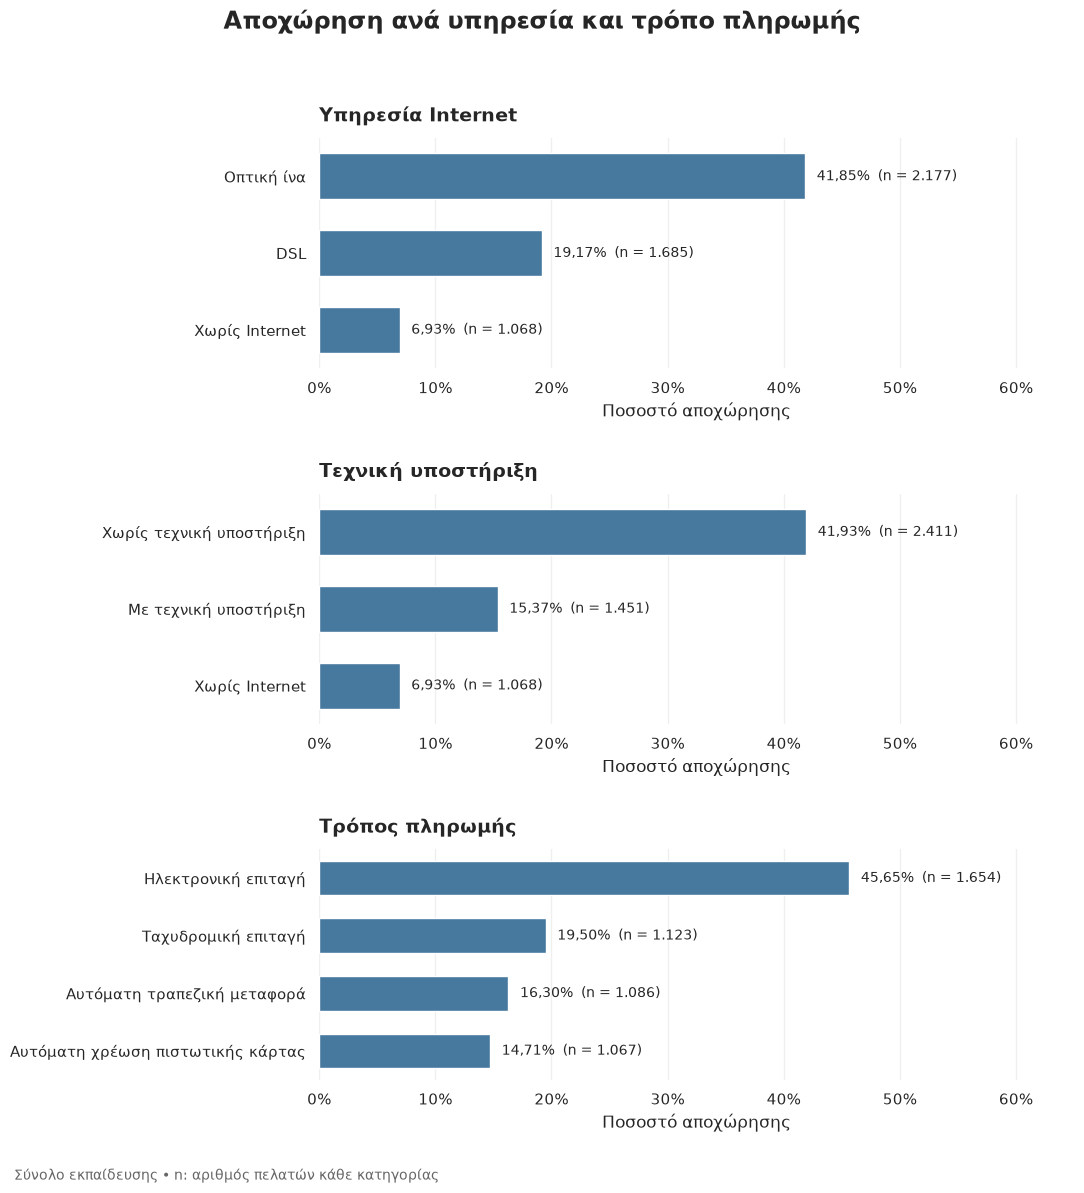

In [14]:
from matplotlib.ticker import PercentFormatter

fig, axes = plt.subplots(nrows=3, figsize=(11, 12))

for ax, (column, settings) in zip(axes, category_settings.items()):
    summary = category_summaries[column].sort_values(
        "Ποσοστό αποχώρησης (%)",
        ascending=False
    )

    chart_data = summary.reset_index()
    category_name = summary.index.name

    sns.barplot(
        data=chart_data,
        x="Ποσοστό αποχώρησης (%)",
        y=category_name,
        order=summary.index.tolist(),
        color="#47799E",
        saturation=1,
        errorbar=None,
        width=0.6,
        ax=ax
    )

    # Εμφανίζουμε ποσοστό και μέγεθος ομάδας δίπλα σε κάθε μπάρα
    for position, (_, row) in enumerate(summary.iterrows()):
        rate = row["Ποσοστό αποχώρησης (%)"]
        count = int(row["Πελάτες"])

        rate_text = f"{rate:.2f}%".replace(".", ",")
        count_text = f"{count:,}".replace(",", ".")

        ax.text(
            rate + 1,
            position,
            f"{rate_text}  (n = {count_text})",
            va="center",
            fontsize=10
        )

    ax.set_title(
        settings["title"],
        fontsize=14,
        fontweight="bold",
        loc="left",
        pad=12
    )

    # Ίδια κλίμακα σε όλα τα γραφήματα για εύκολη σύγκριση
    ax.set_xlim(0, 65)
    ax.set_xlabel("Ποσοστό αποχώρησης")
    ax.set_ylabel("")
    ax.xaxis.set_major_formatter(
        PercentFormatter(xmax=100, decimals=0)
    )

    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)
    sns.despine(ax=ax, left=True, bottom=True)

fig.suptitle(
    "Αποχώρηση ανά υπηρεσία και τρόπο πληρωμής",
    fontsize=17,
    fontweight="bold",
    y=0.99
)

fig.text(
    0.02, 0.015,
    "Σύνολο εκπαίδευσης • n: αριθμός πελατών κάθε κατηγορίας",
    fontsize=10,
    color="#666666"
)

fig.tight_layout(rect=[0, 0.04, 1, 0.96], h_pad=2.5)

plt.show()  # Εμφανίζουμε το γράφημα μέσα στο notebook.


#### Συσχετίσεις αριθμητικών χαρακτηριστικών

Εξετάζουμε τη γραμμική σχέση μεταξύ της διάρκειας συνεργασίας, της μηνιαίας χρέωσης και της συνολικής χρέωσης, χρησιμοποιώντας τον συντελεστή συσχέτισης Pearson.

Ο υπολογισμός γίνεται μόνο στα δεδομένα εκπαίδευσης. Για κάθε ζεύγος χρησιμοποιούνται οι εγγραφές που διαθέτουν τιμές και στα δύο χαρακτηριστικά, χωρίς συμπλήρωση των κενών.


In [15]:
# Υπολογίζουμε τις συσχετίσεις των τριών αριθμητικών χαρακτηριστικών
correlation_columns = ["tenure", "MonthlyCharges", "TotalCharges"]

correlation_matrix = train_data[correlation_columns].corr(
    method="pearson"
)

# Ελληνικές ονομασίες για τον πίνακα και το γράφημα
correlation_labels = {
    "tenure": "Διάρκεια συνεργασίας",
    "MonthlyCharges": "Μηνιαία χρέωση",
    "TotalCharges": "Συνολική χρέωση"
}

correlation_matrix = correlation_matrix.rename(
    index=correlation_labels,
    columns=correlation_labels
)

display(correlation_matrix.round(3))


,Διάρκεια συνεργασίας,Μηνιαία χρέωση,Συνολική χρέωση
Διάρκεια συνεργασίας,1.000,0.258,0.830
Μηνιαία χρέωση,0.258,1.000,0.654
Συνολική χρέωση,0.830,0.654,1.000


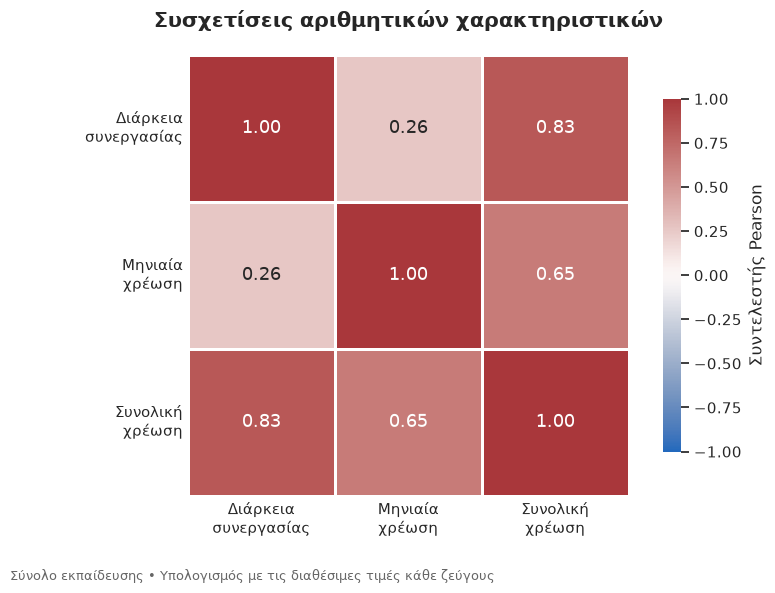

In [16]:
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,  # Γράφουμε την τιμή μέσα σε κάθε τετράγωνο.
    fmt=".2f",  # Εμφανίζουμε δύο δεκαδικά ψηφία.
    cmap="vlag",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=1,
    linecolor="white",
    annot_kws={"size": 13},
    cbar_kws={
        "label": "Συντελεστής Pearson",
        "shrink": 0.8
    },
    ax=ax
)

ax.set_title(
    "Συσχετίσεις αριθμητικών χαρακτηριστικών",
    fontsize=15,
    fontweight="bold",
    pad=20
)

# Σύντομες ετικέτες σε δύο γραμμές για καλύτερη αναγνωσιμότητα
axis_labels = [
    "Διάρκεια\nσυνεργασίας",
    "Μηνιαία\nχρέωση",
    "Συνολική\nχρέωση"
]

ax.set_xticklabels(axis_labels, rotation=0)
ax.set_yticklabels(axis_labels, rotation=0)
ax.tick_params(axis="both", length=0)

fig.text(
    0.02, 0.02,
    "Σύνολο εκπαίδευσης • Υπολογισμός με τις διαθέσιμες τιμές κάθε ζεύγους",
    fontsize=9,
    color="#666666"
)

fig.tight_layout(rect=[0, 0.06, 1, 1])

plt.show()  # Εμφανίζουμε το γράφημα μέσα στο notebook.


#### Παρατηρήσεις για τις συσχετίσεις

Η διάρκεια συνεργασίας παρουσιάζει ισχυρή θετική συσχέτιση με τη συνολική χρέωση (r ≈ 0,83). Το αποτέλεσμα είναι αναμενόμενο, καθώς οι πελάτες που παραμένουν περισσότερο έχουν περισσότερο χρόνο για να συγκεντρώσουν χρεώσεις.

Η μηνιαία χρέωση παρουσιάζει επίσης θετική συσχέτιση με τη συνολική χρέωση (r ≈ 0,65). Αντίθετα, η σχέση μεταξύ διάρκειας συνεργασίας και μηνιαίας χρέωσης είναι ασθενέστερη (r ≈ 0,26).

Τα χαρακτηριστικά περιέχουν επομένως εν μέρει κοινή πληροφορία. Δεν αφαιρούμε κάποιο μόνο λόγω της συσχέτισης, αλλά θα λάβουμε αυτή τη σχέση υπόψη κατά την ερμηνεία των μοντέλων.


#### Σύνοψη της διερευνητικής ανάλυσης

Η διερευνητική ανάλυση έγινε στα δεδομένα εκπαίδευσης. Το 26,53% των πελατών αποχώρησε, ενώ το 73,47% παρέμεινε. Η διαφορά αυτή δείχνει γιατί η αξιολόγηση δεν πρέπει να βασιστεί μόνο στην accuracy.

Υψηλότερα ποσοστά αποχώρησης παρατηρήθηκαν στα μηνιαία συμβόλαια, στην οπτική ίνα, στους πελάτες με Internet χωρίς υπηρεσία τεχνικής υποστήριξης και στην πληρωμή με ηλεκτρονική επιταγή.

Οι πελάτες που αποχώρησαν είχαν μικρότερη διάμεση διάρκεια συνεργασίας και υψηλότερη διάμεση μηνιαία χρέωση. Οι συνολικές χρεώσεις παρουσίασαν δεξιά ασυμμετρία και ισχυρή θετική συσχέτιση με τη διάρκεια συνεργασίας.

Τα ευρήματα δείχνουν σχέσεις μεταξύ χαρακτηριστικών και αποχώρησης, χωρίς να αποδεικνύουν αιτίες. Οι συγκρίσεις έγιναν κυρίως για κάθε χαρακτηριστικό ξεχωριστά, ενώ τα μοντέλα θα αξιοποιήσουν τα χαρακτηριστικά συνδυαστικά.

Στο επόμενο στάδιο θα συμπληρώσουμε τις ελλιπείς τιμές, θα κωδικοποιήσουμε τις κατηγορίες και θα τυποποιήσουμε τα αριθμητικά χαρακτηριστικά. Οι παράμετροι αυτών των μετασχηματισμών θα υπολογιστούν μόνο από το σύνολο εκπαίδευσης.


### 6. Προεπεξεργασία για την εκπαίδευση των μοντέλων

Προετοιμάζουμε τα χαρακτηριστικά ώστε να μπορούν να χρησιμοποιηθούν στη λογιστική παλινδρόμηση και στο νευρωνικό δίκτυο.

Για τα αριθμητικά χαρακτηριστικά tenure, MonthlyCharges και TotalCharges, συμπληρώνουμε τις ελλιπείς τιμές με τη διάμεσο του αντίστοιχου χαρακτηριστικού στο σύνολο εκπαίδευσης. Η διάμεσος επηρεάζεται λιγότερο από ακραίες τιμές, κάτι που είναι χρήσιμο για τις συνολικές χρεώσεις, οι οποίες παρουσιάζουν δεξιά ασυμμετρία.

Στη συνέχεια εφαρμόζουμε τυποποίηση με StandardScaler, ώστε τα αριθμητικά χαρακτηριστικά να έχουν συγκρίσιμες κλίμακες. Ο μετασχηματισμός αφαιρεί τον μέσο όρο και διαιρεί με την τυπική απόκλιση που υπολογίζονται στο σύνολο εκπαίδευσης.

Τα κατηγορικά χαρακτηριστικά κωδικοποιούνται με one-hot encoding. Έτσι, οι κατηγορίες αναπαρίστανται με δυαδικές στήλες, χωρίς να τους αποδίδεται αυθαίρετη αριθμητική σειρά. Το SeniorCitizen αντιμετωπίζεται ως κατηγορικό χαρακτηριστικό, παρότι αποθηκεύεται με τις αριθμητικές τιμές 0 και 1.

Συνδυάζουμε τους μετασχηματισμούς με Pipeline και ColumnTransformer. Η εκμάθησή τους γίνεται μόνο στο training set. Στο validation set εφαρμόζονται οι ίδιοι μετασχηματισμοί χωρίς νέο υπολογισμό παραμέτρων. Το test set διατηρείται για την τελική αξιολόγηση.


In [17]:
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Τα τρία αριθμητικά χαρακτηριστικά
numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

# Τα υπόλοιπα χαρακτηριστικά αντιμετωπίζονται ως κατηγορικά
categorical_features = [
    column
    for column in X_train.columns
    if column not in numeric_features
]

# Συμπλήρωση κενών και τυποποίηση αριθμητικών χαρακτηριστικών
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),  # Συμπληρώνουμε τα κενά με τη διάμεσο του training.
    ("scaler", StandardScaler())  # Φέρνουμε τα αριθμητικά χαρακτηριστικά σε κοινή κλίμακα.
])

# Κωδικοποίηση κατηγοριών σε δυαδικές στήλες
# Τυχόν άγνωστες κατηγορίες στο validation δεν προκαλούν σφάλμα
categorical_encoder = OneHotEncoder(
    handle_unknown="ignore",  # Μια νέα κατηγορία δεν θα σταματήσει την πρόβλεψη.
    sparse_output=False  # Παίρνουμε έναν κανονικό πίνακα αριθμών.
)

# Συνδυάζουμε τους μετασχηματισμούς
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_encoder, categorical_features)
    ],
    remainder="drop"  # Δεν κρατάμε άλλες στήλες πέρα από όσες επιλέξαμε.
)

# Μαθαίνουμε τις παραμέτρους ΜΟΝΟ από το training set
X_train_processed = preprocessor.fit_transform(X_train)

# Εφαρμόζουμε τις ίδιες παραμέτρους στο validation set
X_val_processed = preprocessor.transform(X_val)

# Κρατάμε τα ονόματα των χαρακτηριστικών για μελλοντική ερμηνεία
feature_names = preprocessor.get_feature_names_out()

print("Training — γραμμές, χαρακτηριστικά:", X_train_processed.shape)
print("Validation — γραμμές, χαρακτηριστικά:", X_val_processed.shape)

print(
    "Όλες οι τιμές του training είναι πεπερασμένες:",
    np.isfinite(X_train_processed).all()
)

print(
    "Όλες οι τιμές του validation είναι πεπερασμένες:",
    np.isfinite(X_val_processed).all()
)

# Παρουσιάζουμε τις διαμέσους που έμαθε ο imputer
imputer = preprocessor.named_transformers_["numeric"].named_steps["imputer"]

imputation_summary = pd.DataFrame({
    "Χαρακτηριστικό": numeric_features,
    "Διάμεσος training": imputer.statistics_
})

display(imputation_summary.round(2))


Training — γραμμές, χαρακτηριστικά: (4930, 46)
Validation — γραμμές, χαρακτηριστικά: (1056, 46)
Όλες οι τιμές του training είναι πεπερασμένες: True
Όλες οι τιμές του validation είναι πεπερασμένες: True


,Χαρακτηριστικό,Διάμεσος training
0,tenure,29.00
1,MonthlyCharges,70.57
2,TotalCharges,1389.20


### 7. Μοντέλο αναφοράς: Logistic Regression

Χρησιμοποιούμε τη λογιστική παλινδρόμηση ως μοντέλο αναφοράς για τη δυαδική ταξινόμηση της αποχώρησης πελατών.

Το μοντέλο εκτιμά την πιθανότητα αποχώρησης από τα προεπεξεργασμένα χαρακτηριστικά. Αποτελεί χρήσιμο baseline λόγω της απλότητας, της ταχύτητας εκπαίδευσης και της δυνατότητας ερμηνείας των συντελεστών του. Ωστόσο, χωρίς πρόσθετους μετασχηματισμούς, δεν αποτυπώνει σύνθετες μη γραμμικές σχέσεις και αλληλεπιδράσεις.

Εκπαιδεύουμε το μοντέλο μόνο στο training set και κάνουμε την αρχική αξιολόγηση στο validation set. Χρησιμοποιούμε κατώφλι πιθανότητας 0,50: πελάτες με εκτιμώμενη πιθανότητα αποχώρησης τουλάχιστον 50% ταξινομούνται ως αποχωρούντες.

Υπολογίζουμε accuracy, precision, recall, F1-score και ROC-AUC. Ως θετική κλάση θεωρούμε την αποχώρηση (Churn = 1). Η ROC-AUC υπολογίζεται από τις πιθανότητες και όχι από τις τελικές δυαδικές προβλέψεις.

Το test set παραμένει διαθέσιμο για την τελική αξιολόγηση, μετά την ολοκλήρωση των επιλογών μοντέλων και ρυθμίσεων.


In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Εκπαιδεύουμε το baseline με σταθερές αρχικές ρυθμίσεις
baseline_model = LogisticRegression(
    C=1.0,  # Ρύθμιση της κανονικοποίησης στη λογιστική παλινδρόμηση.
    solver="lbfgs",  # Ο τρόπος με τον οποίο βρίσκονται οι συντελεστές.
    max_iter=2000,  # Δίνουμε αρκετές επαναλήψεις για να ολοκληρωθεί η εκπαίδευση.
    random_state=42
)

baseline_model.fit(X_train_processed, y_train)

# Πιθανότητα αποχώρησης για κάθε πελάτη του validation set
positive_class_index = list(baseline_model.classes_).index(1)

baseline_val_probabilities = baseline_model.predict_proba(
    X_val_processed
)[:, positive_class_index]

# Μετατρέπουμε τις πιθανότητες σε προβλέψεις με κατώφλι 0,50
baseline_val_predictions = (
    baseline_val_probabilities >= 0.50
).astype(int)  # Το False γίνεται 0 και το True γίνεται 1.

# Κρατάμε τα αποτελέσματα για τη μελλοντική σύγκριση μοντέλων
baseline_results = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_val, baseline_val_predictions),
    "Precision": precision_score(
        y_val, baseline_val_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_val, baseline_val_predictions, zero_division=0
    ),
    "F1-score": f1_score(
        y_val, baseline_val_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_val, baseline_val_probabilities)
}

baseline_results_df = pd.DataFrame([baseline_results]).set_index("Model")

print("Αποτελέσματα στο validation set — κατώφλι 0,50")
display(baseline_results_df.round(4))


Αποτελέσματα στο validation set — κατώφλι 0,50


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.8059,0.6459,0.5929,0.6182,0.8453


#### Αρχική αξιολόγηση της Logistic Regression

Στο σύνολο επικύρωσης, η Logistic Regression πέτυχε accuracy 80,59%, precision 64,59%, recall 59,29%, F1-score 61,82% και ROC-AUC 0,8453.

Η accuracy υπερβαίνει το περίπου 73,48% που θα πετύχαινε μια σταθερή πρόβλεψη παραμονής για όλους τους πελάτες. Ωστόσο, λόγω της ανισορροπίας των κλάσεων, η accuracy δεν αρκεί για την αξιολόγηση του μοντέλου.

Με κατώφλι 0,50, το μοντέλο εντοπίζει το 59,29% των πελατών που αποχώρησαν, ενώ το 40,71% δεν αναγνωρίζεται ως πιθανή αποχώρηση. Από επιχειρηματική άποψη, αυτές οι περιπτώσεις αντιπροσωπεύουν πιθανές χαμένες ευκαιρίες παρέμβασης.

Η precision 64,59% δείχνει ότι μέρος των πελατών που θα επιλέγονταν για ενέργειες διατήρησης τελικά δεν αποχώρησε. Επομένως, η επιλογή κατωφλίου πρέπει να συνδέεται με το κόστος των παρεμβάσεων και το κόστος απώλειας πελατών.

Η ROC-AUC 0,8453 δείχνει αξιόλογη ικανότητα διάκρισης, χωρίς να αποδεικνύει ότι οι εκτιμώμενες πιθανότητες είναι καλά βαθμονομημένες. Τα αποτελέσματα αφορούν το validation set και δεν αποτελούν ακόμη τελική αξιολόγηση στο test set.


Σωστή πρόβλεψη παραμονής (TN): 685
Λανθασμένη πρόβλεψη αποχώρησης (FP): 91
Αποχώρηση που δεν εντοπίστηκε (FN): 114
Σωστή πρόβλεψη αποχώρησης (TP): 166


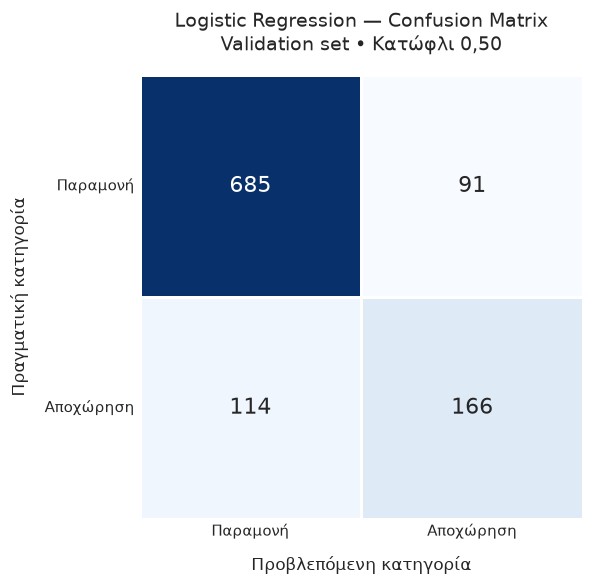

In [19]:
from sklearn.metrics import confusion_matrix

# Υπολογισμός του confusion matrix
baseline_cm = confusion_matrix(
    y_val,
    baseline_val_predictions,
    labels=[0, 1]  # Σειρά κλάσεων: παραμονή πρώτα, αποχώρηση μετά.
)

tn, fp, fn, tp = baseline_cm.ravel()

print(f"Σωστή πρόβλεψη παραμονής (TN): {tn}")
print(f"Λανθασμένη πρόβλεψη αποχώρησης (FP): {fp}")
print(f"Αποχώρηση που δεν εντοπίστηκε (FN): {fn}")
print(f"Σωστή πρόβλεψη αποχώρησης (TP): {tp}")

# Σχεδίαση με Seaborn
fig, ax = plt.subplots(figsize=(7, 6))

sns.heatmap(
    baseline_cm,
    annot=True,  # Γράφουμε την τιμή μέσα σε κάθε τετράγωνο.
    fmt="d",  # Εμφανίζουμε ακέραιους αριθμούς πελατών.
    cmap="Blues",
    cbar=False,
    square=True,
    linewidths=1,
    linecolor="white",
    xticklabels=["Παραμονή", "Αποχώρηση"],
    yticklabels=["Παραμονή", "Αποχώρηση"],
    annot_kws={"size": 16},
    ax=ax
)

ax.set_title(
    "Logistic Regression — Confusion Matrix\n"
    "Validation set • Κατώφλι 0,50",
    fontsize=14,
    pad=18
)

ax.set_xlabel("Προβλεπόμενη κατηγορία", labelpad=12)
ax.set_ylabel("Πραγματική κατηγορία", labelpad=12)
ax.tick_params(axis="both", rotation=0, length=0)
ax.grid(False)

fig.tight_layout()

plt.show()  # Εμφανίζουμε το γράφημα μέσα στο notebook.


#### Ερμηνεία του confusion matrix

Στους 1.056 πελάτες του συνόλου επικύρωσης, το μοντέλο ταξινόμησε σωστά 685 περιπτώσεις παραμονής και 166 περιπτώσεις αποχώρησης.

Από τους 280 πελάτες που αποχώρησαν, εντόπισε τους 166 (59,29%), ενώ οι υπόλοιποι 114 (40,71%) ταξινομήθηκαν λανθασμένα ως πελάτες που θα παρέμεναν. Τα false negatives αντιπροσωπεύουν πιθανές χαμένες ευκαιρίες έγκαιρης παρέμβασης.

Παράλληλα, 91 πελάτες που παρέμειναν ταξινομήθηκαν ως πιθανές αποχωρήσεις. Αυτά τα false positives θα μπορούσαν να οδηγήσουν σε περιττές επικοινωνίες ή προσφορές διατήρησης, αυξάνοντας το κόστος μιας σχετικής καμπάνιας.

Η επιχειρηματική σημασία των δύο τύπων σφάλματος εξαρτάται από το κόστος της παρέμβασης και την αξία του πελάτη. Η μείωση του κατωφλίου ταξινόμησης μπορεί να αυξήσει τον εντοπισμό αποχωρήσεων, αλλά μπορεί να αυξήσει και τους λανθασμένους συναγερμούς. Τυχόν επιλογή διαφορετικού κατωφλίου θα πρέπει να γίνει στο validation set, διατηρώντας το test set για την τελική αξιολόγηση.


### 8. Αρχικό νευρωνικό δίκτυο με TensorFlow/Keras

Κατασκευάζουμε ένα feedforward νευρωνικό δίκτυο (MLP) με δύο κρυφά επίπεδα, αποτελούμενα από 32 και 16 νευρώνες, και συνάρτηση ενεργοποίησης ReLU.

Το επίπεδο εισόδου δέχεται τα προεπεξεργασμένα χαρακτηριστικά. Το επίπεδο εξόδου περιλαμβάνει έναν νευρώνα με sigmoid, ο οποίος παράγει μια εκτίμηση της πιθανότητας αποχώρησης.

Χρησιμοποιούμε binary cross-entropy ως συνάρτηση απώλειας, καθώς το πρόβλημα είναι δυαδική ταξινόμηση, και τον βελτιστοποιητή Adam με αρχικό learning rate 0,001.

Η αρχιτεκτονική αποτελεί σημείο εκκίνησης και δεν θεωρείται εκ των προτέρων βέλτιστη. Στη συνέχεια θα εξεταστούν εναλλακτικές ρυθμίσεις και τεχνικές regularisation.

Η εκπαίδευση γίνεται στο training set, ενώ το validation set χρησιμοποιείται για την παρακολούθηση της γενίκευσης. Εφαρμόζουμε early stopping: αν το validation loss δεν βελτιωθεί για 10 διαδοχικά epochs, η εκπαίδευση σταματά και επαναφέρονται τα βάρη του epoch με το χαμηλότερο validation loss. Το test set δεν χρησιμοποιείται.


In [ ]:
import numpy as np
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

# 1. Προετοιμασία περιβάλλοντος
keras.backend.clear_session()  # Καθαρίζουμε την προηγούμενη κατάσταση του Keras.
keras.utils.set_random_seed(42)  # Ορίζουμε την τυχαιότητα για πιο εύκολη επανάληψη.

# Μετατρέπουμε τα δεδομένα σε float32 για το νευρωνικό δίκτυο
X_train_nn = np.asarray(X_train_processed, dtype=np.float32)
X_val_nn = np.asarray(X_val_processed, dtype=np.float32)

y_train_nn = np.asarray(y_train, dtype=np.float32)
y_val_nn = np.asarray(y_val, dtype=np.float32)

# 2. Κατασκευή αρχικού MLP
# Δύο κρυφά επίπεδα με ReLU και μία έξοδο με sigmoid
mlp_model = keras.Sequential(
    [
        keras.Input(shape=(X_train_nn.shape[1],)),  # Μία θέση εισόδου για κάθε χαρακτηριστικό.
        layers.Dense(32, activation="relu"),  # Πρώτο κρυφό επίπεδο με 32 νευρώνες.
        layers.Dense(16, activation="relu"),  # Δεύτερο κρυφό επίπεδο με 16 νευρώνες.
        layers.Dense(1, activation="sigmoid")  # Μία έξοδος: εκτίμηση πιθανότητας αποχώρησης.
    ],
    name="initial_mlp"
)

# 3. Ρυθμίσεις εκπαίδευσης για δυαδική ταξινόμηση
mlp_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",  # Μετρά το σφάλμα των πιθανοτήτων για τις δύο κλάσεις.
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.AUC(name="auc")
    ]
)

mlp_model.summary()

# 4. Διακοπή όταν το validation loss δεν βελτιώνεται
# Επαναφέρουμε τα βάρη του καλύτερου epoch
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",  # Παρακολουθούμε το σφάλμα στο validation.
    mode="min",  # Μικρότερο σφάλμα σημαίνει καλύτερη επίδοση.
    patience=10,  # Περιμένουμε 10 epochs χωρίς βελτίωση πριν σταματήσουμε.
    restore_best_weights=True  # Κρατάμε τα βάρη του καλύτερου epoch.
)

# 5. Εκπαίδευση μόνο στο training set
# Το validation χρησιμοποιείται για παρακολούθηση και early stopping
mlp_history = mlp_model.fit(
    X_train_nn,
    y_train_nn,
    validation_data=(X_val_nn, y_val_nn),  # Τα δεδομένα αυτά ελέγχουν την επίδοση, δεν μαθαίνουν τα βάρη.
    epochs=100,  # Ανώτατο όριο το early stopping μπορεί να σταματήσει νωρίτερα.
    batch_size=32,  # Ενημερώνουμε τα βάρη ανά ομάδα 32 πελατών.
    callbacks=[early_stopping],
    shuffle=True,  # Αλλάζουμε τη σειρά των πελατών σε κάθε epoch.
    verbose=2  # Εμφανίζουμε μία γραμμή ενημέρωσης ανά epoch.
)

# 6. Σύνοψη εκπαίδευσης
best_epoch = int(np.argmin(mlp_history.history["val_loss"]) + 1)  # Βρίσκουμε το καλύτερο epoch η αρίθμηση ξεκινά από το 1.

print("\nEpochs που εκτελέστηκαν:", len(mlp_history.history["loss"]))
print("Epoch με το χαμηλότερο validation loss:", best_epoch)
print(
    "Καλύτερο validation loss:",
    round(min(mlp_history.history["val_loss"]), 4)
)


Model: "initial_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         1,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,049 (8.00 KB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
155/155 - 1s - 6ms/step - accuracy: 0.7740 - auc: 0.8000 - loss: 0.4636 - val_accuracy: 0.7955 - val_auc: 0.8346 - val_loss: 0.4288
Epoch 2/100
155/155 - 0s - 654us/step - accuracy: 0.7974 - auc: 0.8386 - loss: 0.4242 - val_accuracy: 0.8021 - val_auc: 0.8420 - val_loss: 0.4214
Epoch 3/100
155/155 - 0s - 648us/step - accuracy: 0.8020 - auc: 0.8432 - loss: 0.4188 - val_accuracy: 0.8030 - val_auc: 0.8444 - val_loss: 0.4192
Epoch 4/100
155/155 - 0s - 621us/step - accuracy: 0.8030 - auc: 0.8455 - loss: 0.4160 - val_accuracy: 0.8011 - val_auc: 0.8447 - val_loss: 0.4182
Epoch 5/100
155/155 - 0s - 602us/step - accuracy: 0.8041 - auc: 0.8476 - loss: 0.4136 - val_accuracy: 0.8068 - val_auc: 0.8446 - val_loss: 0.4183
Epoch 6/100
155/155 - 0s - 605us/step - accuracy: 0.8051 - auc: 0.8486 - loss: 0.4122 - val_accuracy: 0.8078 - val_auc: 0.8451 - val_loss: 0.4178
Epoch 7/100
155/155 - 0s - 598us/step - accuracy: 0.8061 - auc: 0.8502 - loss: 0.4104 - val_accuracy: 0.8068 - val_auc: 0.8448

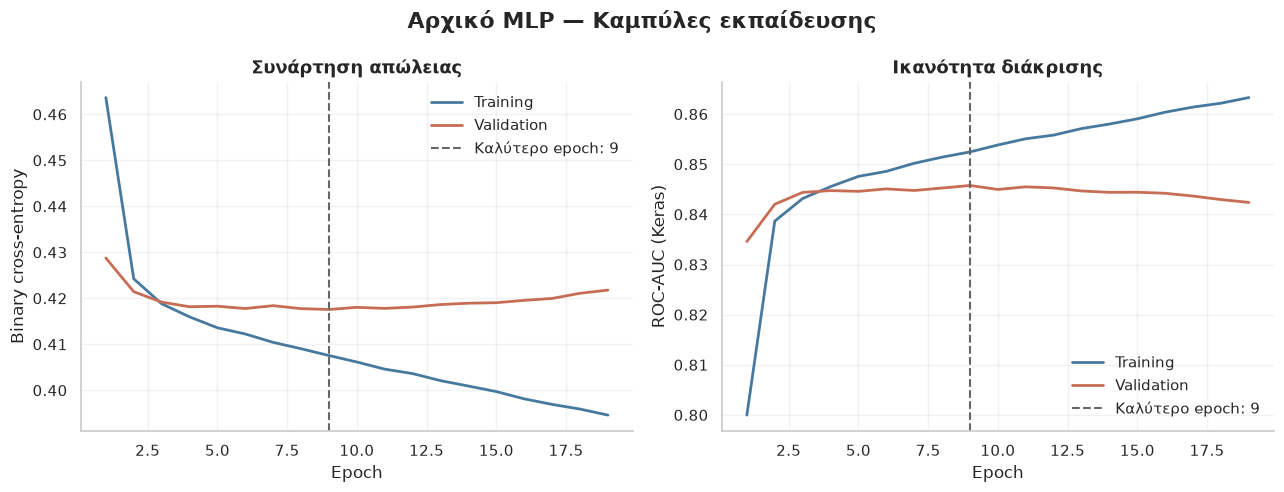

Σύγκριση στο validation set — κατώφλι 0,50


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.8059,0.6459,0.5929,0.6182,0.8453
Initial MLP,0.8040,0.6652,0.5250,0.5868,0.8456


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# 1. Καμπύλες εκπαίδευσης
history_df = pd.DataFrame(mlp_history.history)
history_df["Epoch"] = np.arange(1, len(history_df) + 1)

best_epoch = int(np.argmin(mlp_history.history["val_loss"]) + 1)  # Βρίσκουμε το καλύτερο epoch η αρίθμηση ξεκινά από το 1.

fig, axes = plt.subplots(ncols=2, figsize=(13, 5))

plot_settings = [
    ("loss", "val_loss", "Συνάρτηση απώλειας", "Binary cross-entropy"),
    ("auc", "val_auc", "Ικανότητα διάκρισης", "ROC-AUC (Keras)")
]

for ax, (train_metric, val_metric, title, ylabel) in zip(
    axes, plot_settings
):
    sns.lineplot(
        data=history_df,
        x="Epoch",
        y=train_metric,
        label="Training",
        color="#47799E",
        linewidth=2,
        ax=ax
    )

    sns.lineplot(
        data=history_df,
        x="Epoch",
        y=val_metric,
        label="Validation",
        color="#C76D55",
        linewidth=2,
        ax=ax
    )

    ax.axvline(
        best_epoch,
        color="#666666",
        linestyle="--",
        linewidth=1.5,
        label=f"Καλύτερο epoch: {best_epoch}"
    )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    ax.legend(frameon=False)
    sns.despine(ax=ax)

fig.suptitle(
    "Αρχικό MLP — Καμπύλες εκπαίδευσης",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout()

plt.show()  # Εμφανίζουμε το γράφημα μέσα στο notebook.

# 2. Προβλέψεις με τα επαναφερμένα βάρη του καλύτερου epoch
# Δεν εκπαιδεύουμε ξανά το μοντέλο
mlp_val_probabilities = mlp_model.predict(
    X_val_nn,
    verbose=0
).ravel()  # Μετατρέπουμε την έξοδο σε μία απλή σειρά τιμών.

# Ίδιο κατώφλι με τη Logistic Regression
mlp_val_predictions = (
    mlp_val_probabilities >= 0.50
).astype(int)  # Το False γίνεται 0 και το True γίνεται 1.

# 3. Αξιολόγηση στο validation set
# Θετική κλάση: αποχώρηση (Churn = 1)
mlp_results = {
    "Model": "Initial MLP",
    "Accuracy": accuracy_score(y_val, mlp_val_predictions),
    "Precision": precision_score(
        y_val, mlp_val_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_val, mlp_val_predictions, zero_division=0
    ),
    "F1-score": f1_score(
        y_val, mlp_val_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_val, mlp_val_probabilities)
}

# 4. Συγκριτικός πίνακας των δύο μοντέλων
comparison_df = pd.DataFrame(
    [baseline_results, mlp_results]
).set_index("Model")

print("Σύγκριση στο validation set — κατώφλι 0,50")
display(comparison_df.round(4))


#### Σύγκριση του αρχικού MLP με τη Logistic Regression

Στο σύνολο επικύρωσης, το αρχικό MLP πέτυχε accuracy 80,40%, precision 66,52%, recall 52,50%, F1-score 58,68% και ROC-AUC 0,8456.

Σε σύγκριση με τη Logistic Regression, το MLP παρουσίασε υψηλότερο precision αλλά χαμηλότερο recall. Συγκεκριμένα, εντόπισε 147 από τις 280 πραγματικές αποχωρήσεις, έναντι 166 της Logistic Regression. Με κοινό κατώφλι 0,50, το MLP άφησε επομένως περισσότερες αποχωρήσεις μη εντοπισμένες.

Η Logistic Regression πέτυχε υψηλότερο F1-score και οριακά υψηλότερη accuracy. Οι τιμές ROC-AUC ήταν πρακτικά ίδιες: 0,8453 και 0,8456 αντίστοιχα. Η διαφορά είναι πολύ μικρή και προέρχεται από έναν διαχωρισμό και μία εκπαίδευση του MLP. Δεν αρκεί για να πούμε ότι το νευρωνικό δίκτυο είναι καλύτερο.

Η παρόμοια ROC-AUC σε συνδυασμό με διαφορετικό precision και recall δείχνει ότι τα μοντέλα έχουν παρόμοια συνολική ικανότητα κατάταξης, αλλά διαφορετική συμπεριφορά στο συγκεκριμένο κατώφλι ταξινόμησης.

Αν προτεραιότητα είναι ο εντοπισμός περισσότερων πελατών που κινδυνεύουν να αποχωρήσουν, η Logistic Regression αποτελεί προς το παρόν την καλύτερη επιλογή μεταξύ των δύο στο κατώφλι 0,50. Για την τελική επιλογή πρέπει να λάβουμε υπόψη πόσο κοστίζει κάθε είδος λάθους στην εταιρεία.

Το αρχικό MLP αποτελεί σημείο αναφοράς για τα επόμενα πειράματα με regularisation, Batch Normalization, residual connections και hyperparameter tuning. Το test set δεν έχει χρησιμοποιηθεί.


### 9. Πείραμα με Dropout

Οι καμπύλες του αρχικού MLP έδειξαν ενδείξεις ήπιας υπερπροσαρμογής. Εξετάζουμε επομένως την προσθήκη Dropout, όπως προβλέπεται στις απαιτήσεις της εργασίας.

Διατηρούμε τα δύο κρυφά επίπεδα με 32 και 16 νευρώνες και προσθέτουμε Dropout με ποσοστό 0,20 μετά από κάθε κρυφό επίπεδο. Κατά την εκπαίδευση, μηδενίζεται τυχαία το 20% των ενεργοποιήσεων, ώστε να περιοριστεί η εξάρτηση του δικτύου από συγκεκριμένους συνδυασμούς νευρώνων. Το Dropout δεν εφαρμόζεται κατά την παραγωγή προβλέψεων.

Διατηρούμε τον ίδιο διαχωρισμό δεδομένων, την προεπεξεργασία, τον optimizer, το learning rate, το batch size και τη ρύθμιση early stopping. Έτσι, η βασική αλλαγή σε σχέση με το αρχικό MLP είναι η προσθήκη Dropout.

Το ποσοστό 0,20 αποτελεί αρχική πειραματική επιλογή. Η αποτελεσματικότητά του εξετάζεται στο validation set, με τις ίδιες πέντε μετρικές και κατώφλι ταξινόμησης 0,50. Μία εκπαίδευση ανά μοντέλο παρέχει αρχική ένδειξη και δεν αρκεί για συμπέρασμα σταθερής υπεροχής.


Model: "mlp_dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │         1,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,049 (8.00 KB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
155/155 - 1s - 6ms/step - accuracy: 0.7558 - auc: 0.7705 - loss: 0.4877 - val_accuracy: 0.7812 - val_auc: 0.8304 - val_loss: 0.4354
Epoch 2/100
155/155 - 0s - 731us/step - accuracy: 0.7811 - auc: 0.8162 - loss: 0.4496 - val_accuracy: 0.7945 - val_auc: 0.8364 - val_loss: 0.4295
Epoch 3/100
155/155 - 0s - 672us/step - accuracy: 0.7933 - auc: 0.8274 - loss: 0.4377 - val_accuracy: 0.7945 - val_auc: 0.8394 - val_loss: 0.4254
Epoch 4/100
155/155 - 0s - 627us/step - accuracy: 0.7982 - auc: 0.8329 - loss: 0.4320 - val_accuracy: 0.7936 - val_auc: 0.8401 - val_loss: 0.4249
Epoch 5/100
155/155 - 0s - 643us/step - accuracy: 0.8002 - auc: 0.8356 - loss: 0.4297 - val_accuracy: 0.7983 - val_auc: 0.8388 - val_loss: 0.4265
Epoch 6/100
155/155 - 0s - 644us/step - accuracy: 0.8008 - auc: 0.8393 - loss: 0.4249 - val_accuracy: 0.8002 - val_auc: 0.8398 - val_loss: 0.4251
Epoch 7/100
155/155 - 0s - 631us/step - accuracy: 0.8020 - auc: 0.8368 - loss: 0.4271 - val_accuracy: 0.8011 - val_auc: 0.8409

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.8059,0.6459,0.5929,0.6182,0.8453
Initial MLP,0.8040,0.6652,0.5250,0.5868,0.8456
MLP + Dropout,0.8059,0.6682,0.5321,0.5924,0.8460


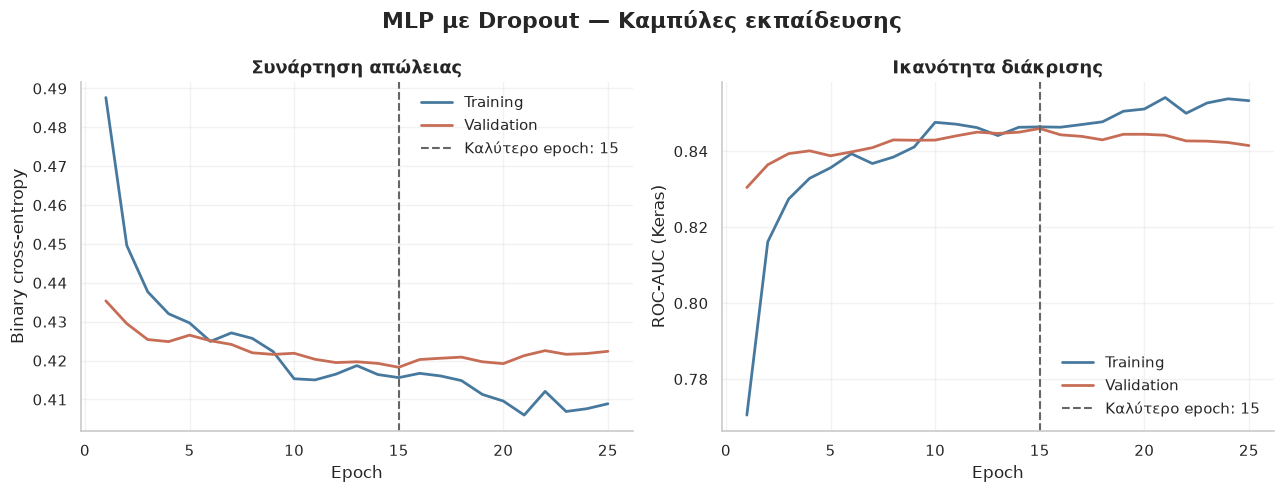

In [ ]:
# 1. Δημιουργία νέου μοντέλου
# Κρατάμε το αρχικό MLP και τα αποτελέσματά του στις μεταβλητές τους
keras.utils.set_random_seed(42)  # Ορίζουμε την τυχαιότητα για πιο εύκολη επανάληψη.

dropout_model = keras.Sequential(
    [
        keras.Input(shape=(X_train_nn.shape[1],)),  # Μία θέση εισόδου για κάθε χαρακτηριστικό.
        layers.Dense(32, activation="relu"),  # Πρώτο κρυφό επίπεδο με 32 νευρώνες.
        layers.Dropout(0.20, seed=42),  # Απενεργοποιούμε τυχαία το 20% των μονάδων στην εκπαίδευση.
        layers.Dense(16, activation="relu"),  # Δεύτερο κρυφό επίπεδο με 16 νευρώνες.
        layers.Dropout(0.20, seed=43),  # Το ίδιο και μετά το δεύτερο κρυφό επίπεδο.
        layers.Dense(1, activation="sigmoid")  # Μία έξοδος: εκτίμηση πιθανότητας αποχώρησης.
    ],
    name="mlp_dropout"
)

dropout_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",  # Μετρά το σφάλμα των πιθανοτήτων για τις δύο κλάσεις.
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.AUC(name="auc")
    ]
)

dropout_model.summary()

# 2. Νέο callback για αυτή την εκπαίδευση
dropout_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",  # Παρακολουθούμε το σφάλμα στο validation.
    mode="min",  # Μικρότερο σφάλμα σημαίνει καλύτερη επίδοση.
    patience=10,  # Περιμένουμε 10 epochs χωρίς βελτίωση πριν σταματήσουμε.
    restore_best_weights=True  # Κρατάμε τα βάρη του καλύτερου epoch.
)

# 3. Εκπαίδευση
dropout_history = dropout_model.fit(
    X_train_nn,
    y_train_nn,
    validation_data=(X_val_nn, y_val_nn),  # Τα δεδομένα αυτά ελέγχουν την επίδοση, δεν μαθαίνουν τα βάρη.
    epochs=100,  # Ανώτατο όριο το early stopping μπορεί να σταματήσει νωρίτερα.
    batch_size=32,  # Ενημερώνουμε τα βάρη ανά ομάδα 32 πελατών.
    callbacks=[dropout_early_stopping],
    shuffle=True,  # Αλλάζουμε τη σειρά των πελατών σε κάθε epoch.
    verbose=2  # Εμφανίζουμε μία γραμμή ενημέρωσης ανά epoch.
)

dropout_best_epoch = int(
    np.argmin(dropout_history.history["val_loss"]) + 1  # Βρίσκουμε το καλύτερο epoch η αρίθμηση ξεκινά από το 1.
)

print(
    "\nEpochs που εκτελέστηκαν:",
    len(dropout_history.history["loss"])
)
print("Καλύτερο epoch:", dropout_best_epoch)
print(
    "Καλύτερο validation loss:",
    round(min(dropout_history.history["val_loss"]), 4)
)

# 4. Αξιολόγηση με τα βάρη του καλύτερου epoch
dropout_val_probabilities = dropout_model.predict(
    X_val_nn,
    verbose=0
).ravel()  # Μετατρέπουμε την έξοδο σε μία απλή σειρά τιμών.

dropout_val_predictions = (
    dropout_val_probabilities >= 0.50
).astype(int)  # Το False γίνεται 0 και το True γίνεται 1.

dropout_results = {
    "Model": "MLP + Dropout",
    "Accuracy": accuracy_score(y_val, dropout_val_predictions),
    "Precision": precision_score(
        y_val, dropout_val_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_val, dropout_val_predictions, zero_division=0
    ),
    "F1-score": f1_score(
        y_val, dropout_val_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_val, dropout_val_probabilities)
}

comparison_df = pd.DataFrame(
    [baseline_results, mlp_results, dropout_results]
).set_index("Model")

print("\nΣύγκριση στο validation set — κατώφλι 0,50")
display(comparison_df.round(4))

# 5. Καμπύλες εκπαίδευσης
dropout_history_df = pd.DataFrame(dropout_history.history)
dropout_history_df["Epoch"] = np.arange(
    1, len(dropout_history_df) + 1
)

fig, axes = plt.subplots(ncols=2, figsize=(13, 5))

plot_settings = [
    ("loss", "val_loss", "Συνάρτηση απώλειας", "Binary cross-entropy"),
    ("auc", "val_auc", "Ικανότητα διάκρισης", "ROC-AUC (Keras)")
]

for ax, (train_metric, val_metric, title, ylabel) in zip(
    axes, plot_settings
):
    sns.lineplot(
        data=dropout_history_df,
        x="Epoch",
        y=train_metric,
        label="Training",
        color="#47799E",
        linewidth=2,
        ax=ax
    )

    sns.lineplot(
        data=dropout_history_df,
        x="Epoch",
        y=val_metric,
        label="Validation",
        color="#C76D55",
        linewidth=2,
        ax=ax
    )

    ax.axvline(
        dropout_best_epoch,
        color="#666666",
        linestyle="--",
        linewidth=1.5,
        label=f"Καλύτερο epoch: {dropout_best_epoch}"
    )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    ax.legend(frameon=False)
    sns.despine(ax=ax)

fig.suptitle(
    "MLP με Dropout — Καμπύλες εκπαίδευσης",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout()

plt.show()  # Εμφανίζουμε το γράφημα μέσα στο notebook.


#### Αξιολόγηση του MLP με Dropout

Το μοντέλο με Dropout πέτυχε στο validation set accuracy 80,59%, precision 66,82%, recall 53,21%, F1-score 59,24% και ROC-AUC 0,8460.

Σε σχέση με το αρχικό MLP, παρατηρούνται μικρές βελτιώσεις στις πέντε μετρικές. Ωστόσο, η Logistic Regression εξακολουθεί να έχει υψηλότερο recall και F1-score στο κοινό κατώφλι 0,50.

Η εκπαίδευση σταμάτησε μετά από 25 epochs και επαναφέρθηκαν τα βάρη του epoch 15. Το χαμηλότερο validation loss ήταν 0,4183, έναντι 0,4176 του αρχικού MLP. Επομένως, το Dropout δεν βελτίωσε τη συγκεκριμένη μέτρηση.

Οι διαφορές είναι μικρές και βασίζονται σε μία εκπαίδευση ανά μοντέλο. Δεν αρκούν για να πούμε ότι το Dropout βελτιώνει σταθερά την απόδοση ή ότι έλυσε το πρόβλημα της υπερπροσαρμογής. Το πείραμα μας βοηθά να συγκρίνουμε τις τεχνικές regularisation.


### 10. Πείραμα με L2 regularisation

Εξετάζουμε την εφαρμογή L2 regularisation στα βάρη των δύο κρυφών επιπέδων του αρχικού MLP.

Η L2 προσθέτει στη συνάρτηση απώλειας μια ποινή ανάλογη με το άθροισμα των τετραγώνων των βαρών. Έτσι, αποθαρρύνει πολύ μεγάλες τιμές βαρών και μπορεί να περιορίσει την υπερπροσαρμογή.

Χρησιμοποιούμε αρχικό συντελεστή L2 ίσο με 0,001. Η τιμή αποτελεί πειραματική επιλογή και δεν θεωρείται βέλτιστη εκ των προτέρων.

Διατηρούμε τα κρυφά επίπεδα με 32 και 16 νευρώνες, τον optimizer Adam, το learning rate 0,001, το batch size 32 και το early stopping. Δεν προσθέτουμε Dropout σε αυτό το πείραμα, ώστε να εξετάσουμε τη L2 ξεχωριστά σε σχέση με το αρχικό MLP.

Η αξιολόγηση γίνεται στο validation set με τις ίδιες πέντε μετρικές και κατώφλι ταξινόμησης 0,50.

Σημειώνεται ότι το loss αυτού του μοντέλου περιλαμβάνει και την ποινή L2. Επομένως, η αριθμητική τιμή του δεν συγκρίνεται απευθείας με το loss των προηγούμενων μοντέλων ως καθαρό σφάλμα πρόβλεψης.


Model: "mlp_l2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 32)             │         1,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,049 (8.00 KB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
155/155 - 1s - 6ms/step - accuracy: 0.7738 - auc: 0.8003 - loss: 0.5161 - val_accuracy: 0.7964 - val_auc: 0.8359 - val_loss: 0.4763
Epoch 2/100
155/155 - 0s - 629us/step - accuracy: 0.7970 - auc: 0.8389 - loss: 0.4694 - val_accuracy: 0.8030 - val_auc: 0.8432 - val_loss: 0.4628
Epoch 3/100
155/155 - 0s - 615us/step - accuracy: 0.8012 - auc: 0.8431 - loss: 0.4597 - val_accuracy: 0.8049 - val_auc: 0.8451 - val_loss: 0.4568
Epoch 4/100
155/155 - 0s - 634us/step - accuracy: 0.8020 - auc: 0.8449 - loss: 0.4540 - val_accuracy: 0.8040 - val_auc: 0.8457 - val_loss: 0.4528
Epoch 5/100
155/155 - 0s - 654us/step - accuracy: 0.8053 - auc: 0.8458 - loss: 0.4500 - val_accuracy: 0.8059 - val_auc: 0.8465 - val_loss: 0.4496
Epoch 6/100
155/155 - 0s - 645us/step - accuracy: 0.8061 - auc: 0.8471 - loss: 0.4462 - val_accuracy: 0.8030 - val_auc: 0.8469 - val_loss: 0.4471
Epoch 7/100
155/155 - 0s - 629us/step - accuracy: 0.8079 - auc: 0.8477 - loss: 0.4432 - val_accuracy: 0.8059 - val_auc: 0.8471

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.8059,0.6459,0.5929,0.6182,0.8453
Initial MLP,0.8040,0.6652,0.5250,0.5868,0.8456
MLP + Dropout,0.8059,0.6682,0.5321,0.5924,0.8460
MLP + L2,0.8097,0.6946,0.5036,0.5839,0.8450


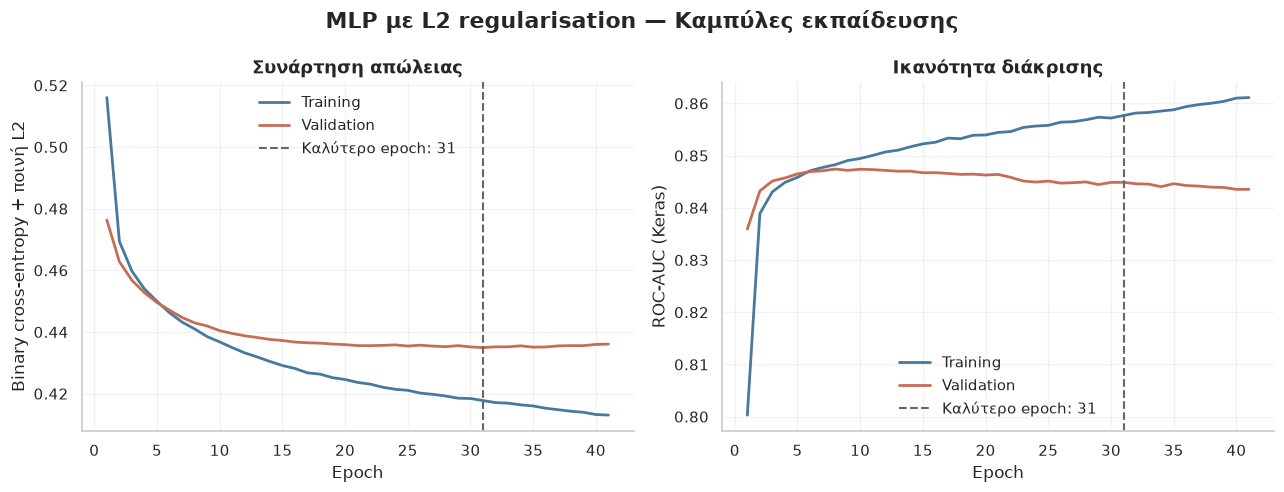

In [ ]:
# 1. Νέο μοντέλο με L2 στα δύο κρυφά επίπεδα
keras.utils.set_random_seed(42)  # Ορίζουμε την τυχαιότητα για πιο εύκολη επανάληψη.

l2_strength = 0.001  # Πόσο έντονα περιορίζουμε τα μεγάλα βάρη με L2.

l2_model = keras.Sequential(
    [
        keras.Input(shape=(X_train_nn.shape[1],)),  # Μία θέση εισόδου για κάθε χαρακτηριστικό.
        layers.Dense(
            32,
            activation="relu",
            kernel_regularizer=keras.regularizers.l2(l2_strength)
        ),
        layers.Dense(
            16,
            activation="relu",
            kernel_regularizer=keras.regularizers.l2(l2_strength)
        ),
        layers.Dense(1, activation="sigmoid")  # Μία έξοδος: εκτίμηση πιθανότητας αποχώρησης.
    ],
    name="mlp_l2"
)

l2_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",  # Μετρά το σφάλμα των πιθανοτήτων για τις δύο κλάσεις.
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.AUC(name="auc")
    ]
)

l2_model.summary()

# 2. Ξεχωριστό callback για το νέο πείραμα
l2_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",  # Παρακολουθούμε το σφάλμα στο validation.
    mode="min",  # Μικρότερο σφάλμα σημαίνει καλύτερη επίδοση.
    patience=10,  # Περιμένουμε 10 epochs χωρίς βελτίωση πριν σταματήσουμε.
    restore_best_weights=True  # Κρατάμε τα βάρη του καλύτερου epoch.
)

# 3. Εκπαίδευση — το test set παραμένει εκτός διαδικασίας
l2_history = l2_model.fit(
    X_train_nn,
    y_train_nn,
    validation_data=(X_val_nn, y_val_nn),  # Τα δεδομένα αυτά ελέγχουν την επίδοση, δεν μαθαίνουν τα βάρη.
    epochs=100,  # Ανώτατο όριο το early stopping μπορεί να σταματήσει νωρίτερα.
    batch_size=32,  # Ενημερώνουμε τα βάρη ανά ομάδα 32 πελατών.
    callbacks=[l2_early_stopping],
    shuffle=True,  # Αλλάζουμε τη σειρά των πελατών σε κάθε epoch.
    verbose=2  # Εμφανίζουμε μία γραμμή ενημέρωσης ανά epoch.
)

l2_best_epoch = int(
    np.argmin(l2_history.history["val_loss"]) + 1  # Βρίσκουμε το καλύτερο epoch η αρίθμηση ξεκινά από το 1.
)

print("\nEpochs που εκτελέστηκαν:", len(l2_history.history["loss"]))
print("Καλύτερο epoch:", l2_best_epoch)
print(
    "Καλύτερο validation loss (περιλαμβάνει την ποινή L2):",
    round(min(l2_history.history["val_loss"]), 4)
)

# 4. Προβλέψεις με τα επαναφερμένα βάρη του καλύτερου epoch
l2_val_probabilities = l2_model.predict(
    X_val_nn,
    verbose=0
).ravel()  # Μετατρέπουμε την έξοδο σε μία απλή σειρά τιμών.

l2_val_predictions = (
    l2_val_probabilities >= 0.50
).astype(int)  # Το False γίνεται 0 και το True γίνεται 1.

# Θετική κλάση: αποχώρηση πελάτη
l2_results = {
    "Model": "MLP + L2",
    "Accuracy": accuracy_score(y_val, l2_val_predictions),
    "Precision": precision_score(
        y_val, l2_val_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_val, l2_val_predictions, zero_division=0
    ),
    "F1-score": f1_score(
        y_val, l2_val_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_val, l2_val_probabilities)
}

comparison_df = pd.DataFrame(
    [
        baseline_results,
        mlp_results,
        dropout_results,
        l2_results
    ]
).set_index("Model")

print("\nΣύγκριση στο validation set — κατώφλι 0,50")
display(comparison_df.round(4))

# 5. Καμπύλες εκπαίδευσης
l2_history_df = pd.DataFrame(l2_history.history)
l2_history_df["Epoch"] = np.arange(
    1, len(l2_history_df) + 1
)

fig, axes = plt.subplots(ncols=2, figsize=(13, 5))

plot_settings = [
    (
        "loss", "val_loss",
        "Συνάρτηση απώλειας",
        "Binary cross-entropy + ποινή L2"
    ),
    (
        "auc", "val_auc",
        "Ικανότητα διάκρισης",
        "ROC-AUC (Keras)"
    )
]

for ax, (train_metric, val_metric, title, ylabel) in zip(
    axes, plot_settings
):
    sns.lineplot(
        data=l2_history_df,
        x="Epoch",
        y=train_metric,
        label="Training",
        color="#47799E",
        linewidth=2,
        ax=ax
    )

    sns.lineplot(
        data=l2_history_df,
        x="Epoch",
        y=val_metric,
        label="Validation",
        color="#C76D55",
        linewidth=2,
        ax=ax
    )

    ax.axvline(
        l2_best_epoch,
        color="#666666",
        linestyle="--",
        linewidth=1.5,
        label=f"Καλύτερο epoch: {l2_best_epoch}"
    )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    ax.legend(frameon=False)
    sns.despine(ax=ax)

fig.suptitle(
    "MLP με L2 regularisation — Καμπύλες εκπαίδευσης",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout()

plt.show()  # Εμφανίζουμε το γράφημα μέσα στο notebook.


#### Αξιολόγηση του MLP με L2 regularisation

Το MLP με L2 regularisation πέτυχε στο validation set accuracy 80,97%, precision 69,46%, recall 50,36%, F1-score 58,39% και ROC-AUC 0,8450, με κατώφλι ταξινόμησης 0,50.

Το μοντέλο παρουσίασε την υψηλότερη accuracy και precision μεταξύ των τεσσάρων μοντέλων που εξετάστηκαν μέχρι αυτό το στάδιο. Ωστόσο, είχε το χαμηλότερο recall και F1-score.

Συγκεκριμένα, εντόπισε 141 από τις 280 πραγματικές αποχωρήσεις, ενώ 139 δεν αναγνωρίστηκαν. Η Logistic Regression εντόπισε 166 αποχωρήσεις στο ίδιο σύνολο δεδομένων και κατώφλι. Επομένως, η υψηλότερη accuracy της L2 δεν σημαίνει αποτελεσματικότερο εντοπισμό πελατών που κινδυνεύουν να αποχωρήσουν.

Οι καμπύλες δείχνουν ότι η training AUC συνεχίζει να αυξάνεται, ενώ η validation AUC φτάνει νωρίς σε ένα μέγιστο και στη συνέχεια υποχωρεί σταδιακά. Παράλληλα, το training loss μειώνεται, ενώ το validation loss παρουσιάζει μικρές μεταβολές στα μεταγενέστερα epochs. Η εικόνα υποδηλώνει ότι η συγκεκριμένη ρύθμιση L2 δεν εξαλείφει την υπερπροσαρμογή.

Το early stopping επανέφερε τα βάρη του epoch 31, στο οποίο καταγράφηκε το χαμηλότερο validation loss, περίπου 0,4349. Η επιλογή έγινε με βάση το validation loss και όχι τη validation AUC. Το loss περιλαμβάνει την ποινή L2 και, συνεπώς, δεν συγκρίνεται απευθείας με το loss των μοντέλων χωρίς αυτή την ποινή ως καθαρό σφάλμα πρόβλεψης.

Από επιχειρηματική άποψη, η υψηλότερη precision θα μπορούσε να είναι χρήσιμη όταν οι παρεμβάσεις διατήρησης έχουν υψηλό κόστος. Το χαμηλότερο recall, όμως, αφήνει περισσότερες πραγματικές αποχωρήσεις χωρίς έγκαιρη αναγνώριση.

Με τα μέχρι τώρα αποτελέσματα, η Logistic Regression παραμένει η καλύτερη επιλογή ως προς το recall και το F1-score στο κατώφλι 0,50. Η L2 με συντελεστή 0,001 δεν προσφέρει συνολική βελτίωση. Το συμπέρασμα αφορά τη συγκεκριμένη ρύθμιση και μία εκπαίδευση, όχι τη χρησιμότητα της L2 γενικά.


### 11. Πείραμα με L1 regularisation

Εξετάζουμε την εφαρμογή L1 regularisation στα βάρη των δύο κρυφών επιπέδων του αρχικού MLP.

Η L1 προσθέτει στη συνάρτηση απώλειας μια ποινή ανάλογη με το άθροισμα των απόλυτων τιμών των βαρών. Ενθαρρύνει μικρά βάρη και μπορεί να οδηγήσει αρκετά από αυτά κοντά στο μηδέν. Αυτό δεν σημαίνει απαραίτητα ότι αφαιρούνται ολόκληρα χαρακτηριστικά εισόδου από το νευρωνικό δίκτυο.

Χρησιμοποιούμε αρχικό συντελεστή L1 ίσο με 0,0001. Η τιμή αποτελεί πειραματική επιλογή και θα αξιολογηθεί στο validation set. Οι συντελεστές L1 και L2 δεν είναι απευθείας συγκρίσιμοι, επειδή οι δύο ποινές υπολογίζονται διαφορετικά.

Διατηρούμε τα δύο κρυφά επίπεδα με 32 και 16 νευρώνες, τον optimizer Adam, το learning rate 0,001, το batch size 32 και τις ίδιες ρυθμίσεις early stopping. Στο συγκεκριμένο πείραμα δεν συνδυάζουμε τη L1 με Dropout ή L2.

Η σύγκριση γίνεται στο validation set με accuracy, precision, recall, F1-score και ROC-AUC, χρησιμοποιώντας κατώφλι 0,50.

Το training και validation loss περιλαμβάνουν την ποινή L1. Επομένως, δεν συγκρίνονται απευθείας με τα losses των άλλων πειραμάτων ως καθαρά σφάλματα πρόβλεψης.


Model: "mlp_l1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 32)             │         1,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,049 (8.00 KB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
155/155 - 1s - 6ms/step - accuracy: 0.7732 - auc: 0.8004 - loss: 0.4916 - val_accuracy: 0.7973 - val_auc: 0.8350 - val_loss: 0.4562
Epoch 2/100
155/155 - 0s - 992us/step - accuracy: 0.7978 - auc: 0.8387 - loss: 0.4514 - val_accuracy: 0.7992 - val_auc: 0.8421 - val_loss: 0.4480
Epoch 3/100
155/155 - 0s - 662us/step - accuracy: 0.8012 - auc: 0.8434 - loss: 0.4451 - val_accuracy: 0.7992 - val_auc: 0.8441 - val_loss: 0.4452
Epoch 4/100
155/155 - 0s - 629us/step - accuracy: 0.8026 - auc: 0.8452 - loss: 0.4423 - val_accuracy: 0.8049 - val_auc: 0.8452 - val_loss: 0.4433
Epoch 5/100
155/155 - 0s - 624us/step - accuracy: 0.8039 - auc: 0.8473 - loss: 0.4395 - val_accuracy: 0.8049 - val_auc: 0.8449 - val_loss: 0.4433
Epoch 6/100
155/155 - 0s - 617us/step - accuracy: 0.8059 - auc: 0.8483 - loss: 0.4375 - val_accuracy: 0.8078 - val_auc: 0.8454 - val_loss: 0.4422
Epoch 7/100
155/155 - 0s - 621us/step - accuracy: 0.8071 - auc: 0.8493 - loss: 0.4358 - val_accuracy: 0.8078 - val_auc: 0.8458

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.8059,0.6459,0.5929,0.6182,0.8453
Initial MLP,0.8040,0.6652,0.5250,0.5868,0.8456
MLP + Dropout,0.8059,0.6682,0.5321,0.5924,0.8460
MLP + L2,0.8097,0.6946,0.5036,0.5839,0.8450
MLP + L1,0.7992,0.6619,0.4964,0.5673,0.8473


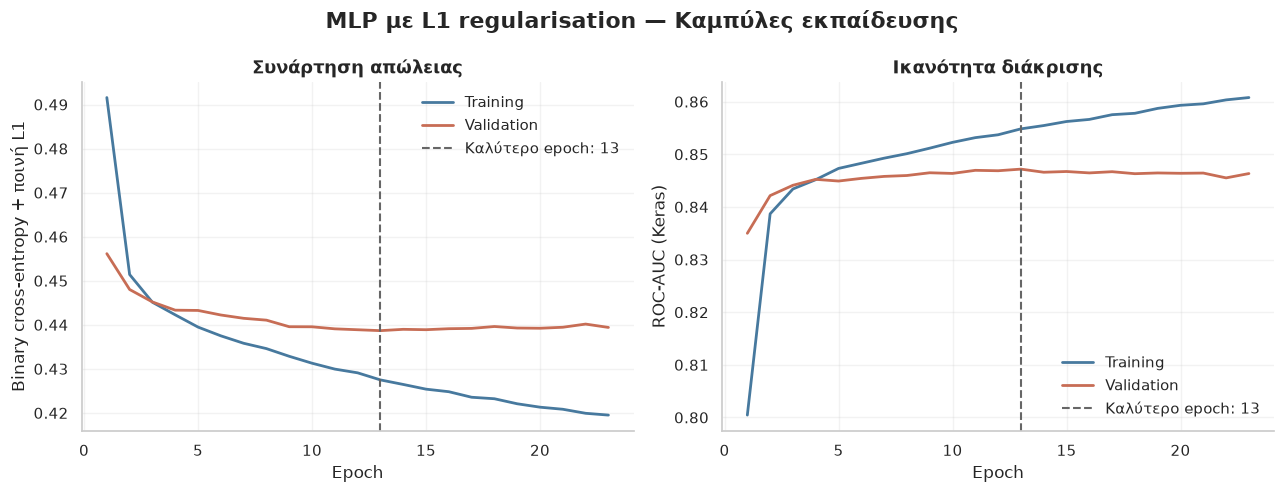

In [ ]:
# 1. Δημιουργία μοντέλου με L1 στα δύο κρυφά επίπεδα
keras.utils.set_random_seed(42)  # Ορίζουμε την τυχαιότητα για πιο εύκολη επανάληψη.

l1_strength = 0.0001  # Πόσο έντονα σπρώχνουμε τα βάρη προς το μηδέν με L1.

l1_model = keras.Sequential(
    [
        keras.Input(shape=(X_train_nn.shape[1],)),  # Μία θέση εισόδου για κάθε χαρακτηριστικό.
        layers.Dense(
            32,
            activation="relu",
            kernel_regularizer=keras.regularizers.l1(l1_strength)
        ),
        layers.Dense(
            16,
            activation="relu",
            kernel_regularizer=keras.regularizers.l1(l1_strength)
        ),
        layers.Dense(1, activation="sigmoid")  # Μία έξοδος: εκτίμηση πιθανότητας αποχώρησης.
    ],
    name="mlp_l1"
)

l1_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",  # Μετρά το σφάλμα των πιθανοτήτων για τις δύο κλάσεις.
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.AUC(name="auc")
    ]
)

l1_model.summary()

# 2. Ξεχωριστό callback για το νέο πείραμα
l1_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",  # Παρακολουθούμε το σφάλμα στο validation.
    mode="min",  # Μικρότερο σφάλμα σημαίνει καλύτερη επίδοση.
    patience=10,  # Περιμένουμε 10 epochs χωρίς βελτίωση πριν σταματήσουμε.
    restore_best_weights=True  # Κρατάμε τα βάρη του καλύτερου epoch.
)

# 3. Εκπαίδευση — εμφανίζουμε τα αποτελέσματα κάθε epoch
l1_history = l1_model.fit(
    X_train_nn,
    y_train_nn,
    validation_data=(X_val_nn, y_val_nn),  # Τα δεδομένα αυτά ελέγχουν την επίδοση, δεν μαθαίνουν τα βάρη.
    epochs=100,  # Ανώτατο όριο το early stopping μπορεί να σταματήσει νωρίτερα.
    batch_size=32,  # Ενημερώνουμε τα βάρη ανά ομάδα 32 πελατών.
    callbacks=[l1_early_stopping],
    shuffle=True,  # Αλλάζουμε τη σειρά των πελατών σε κάθε epoch.
    verbose=2  # Εμφανίζουμε μία γραμμή ενημέρωσης ανά epoch.
)

l1_best_epoch = int(
    np.argmin(l1_history.history["val_loss"]) + 1  # Βρίσκουμε το καλύτερο epoch η αρίθμηση ξεκινά από το 1.
)

print(
    "\nEpochs που εκτελέστηκαν:",
    len(l1_history.history["loss"])
)
print("Καλύτερο epoch:", l1_best_epoch)
print(
    "Καλύτερο validation loss (περιλαμβάνει την ποινή L1):",
    round(min(l1_history.history["val_loss"]), 4)
)

# 4. Αξιολόγηση με τα επαναφερμένα βάρη του καλύτερου epoch
l1_val_probabilities = l1_model.predict(
    X_val_nn,
    verbose=0
).ravel()  # Μετατρέπουμε την έξοδο σε μία απλή σειρά τιμών.

# Ίδιο κατώφλι με τα προηγούμενα μοντέλα
l1_val_predictions = (
    l1_val_probabilities >= 0.50
).astype(int)  # Το False γίνεται 0 και το True γίνεται 1.

# Θετική κλάση: αποχώρηση πελάτη (Churn = 1)
l1_results = {
    "Model": "MLP + L1",
    "Accuracy": accuracy_score(y_val, l1_val_predictions),
    "Precision": precision_score(
        y_val, l1_val_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_val, l1_val_predictions, zero_division=0
    ),
    "F1-score": f1_score(
        y_val, l1_val_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_val, l1_val_probabilities)
}

# 5. Σύγκριση όλων των μοντέλων μέχρι αυτό το στάδιο
comparison_df = pd.DataFrame(
    [
        baseline_results,
        mlp_results,
        dropout_results,
        l2_results,
        l1_results
    ]
).set_index("Model")

print("\nΣύγκριση στο validation set — κατώφλι 0,50")
display(comparison_df.round(4))

# 6. Καμπύλες εκπαίδευσης
l1_history_df = pd.DataFrame(l1_history.history)
l1_history_df["Epoch"] = np.arange(
    1, len(l1_history_df) + 1
)

fig, axes = plt.subplots(ncols=2, figsize=(13, 5))

plot_settings = [
    (
        "loss", "val_loss",
        "Συνάρτηση απώλειας",
        "Binary cross-entropy + ποινή L1"
    ),
    (
        "auc", "val_auc",
        "Ικανότητα διάκρισης",
        "ROC-AUC (Keras)"
    )
]

for ax, (train_metric, val_metric, title, ylabel) in zip(
    axes, plot_settings
):
    sns.lineplot(
        data=l1_history_df,
        x="Epoch",
        y=train_metric,
        label="Training",
        color="#47799E",
        linewidth=2,
        ax=ax
    )

    sns.lineplot(
        data=l1_history_df,
        x="Epoch",
        y=val_metric,
        label="Validation",
        color="#C76D55",
        linewidth=2,
        ax=ax
    )

    ax.axvline(
        l1_best_epoch,
        color="#666666",
        linestyle="--",
        linewidth=1.5,
        label=f"Καλύτερο epoch: {l1_best_epoch}"
    )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    ax.legend(frameon=False)
    sns.despine(ax=ax)

fig.suptitle(
    "MLP με L1 regularisation — Καμπύλες εκπαίδευσης",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout()

plt.show()  # Εμφανίζουμε το γράφημα μέσα στο notebook.


#### Αξιολόγηση του MLP με L1 regularisation

Το MLP με L1 regularisation και συντελεστή 0,0001 πέτυχε στο validation set accuracy 79,92%, precision 66,19%, recall 49,64%, F1-score 56,73% και ROC-AUC 0,8473, με κατώφλι ταξινόμησης 0,50.

Η ROC-AUC ήταν η υψηλότερη μεταξύ των μοντέλων που εξετάστηκαν, αλλά η διαφορά από το αρχικό MLP (0,8456) και το MLP με Dropout (0,8460) ήταν μικρή. Μία μεμονωμένη εκπαίδευση δεν αρκεί για να τεκμηριωθεί σταθερή υπεροχή της L1.

Παρά την ελαφρώς υψηλότερη ROC-AUC, το μοντέλο παρουσίασε τη χαμηλότερη accuracy, recall και F1-score στο κατώφλι 0,50. Συγκεκριμένα, αναγνώρισε περίπου το 49,64% των πραγματικών αποχωρήσεων, έναντι 59,29% της Logistic Regression.

Η διαφορά αυτή εξηγείται από το ότι η ROC-AUC αξιολογεί την ικανότητα κατάταξης των πελατών ως προς τον κίνδυνο αποχώρησης σε διαφορετικά κατώφλια. Αντίθετα, η precision, το recall και το F1-score εξαρτώνται από το επιλεγμένο κατώφλι ταξινόμησης. Επομένως, υψηλότερη ROC-AUC δεν σημαίνει απαραίτητα καλύτερο F1-score στο κατώφλι 0,50.

Οι καμπύλες εκπαίδευσης δείχνουν συνεχή μείωση του training loss και αύξηση της training AUC. Αντίθετα, το validation loss σταματά να βελτιώνεται ουσιαστικά περίπου στο epoch 13, ενώ η validation AUC παραμένει σχετικά σταθερή, κοντά στο 0,847. Η αυξανόμενη απόσταση μεταξύ training και validation επιδόσεων αποτελεί ένδειξη υπερπροσαρμογής, την οποία η συγκεκριμένη ρύθμιση L1 δεν εξαλείφει.

Το early stopping επανέφερε τα βάρη του epoch 13, στο οποίο καταγράφηκε το χαμηλότερο validation loss, περίπου 0,4387. Το loss περιλαμβάνει την ποινή L1 και δεν συγκρίνεται απευθείας με τα losses των άλλων πειραμάτων ως καθαρό σφάλμα πρόβλεψης.

Συνολικά, η συγκεκριμένη εφαρμογή L1 δεν βελτίωσε τον εντοπισμό αποχωρήσεων στο κατώφλι 0,50. Η Logistic Regression παραμένει η καλύτερη από τις εξεταζόμενες επιλογές ως προς το recall και το F1-score, ενώ η μικρή υπεροχή της L1 στη ROC-AUC χρειάζεται επιβεβαίωση με περισσότερες δοκιμές.


### 12. Πείραμα με Batch Normalization

Εξετάζουμε την επίδραση του Batch Normalization στο MLP, διατηρώντας δύο κρυφά επίπεδα με 32 και 16 νευρώνες.

Το Batch Normalization τοποθετείται μετά από κάθε κρυφό Dense επίπεδο και πριν από τη συνάρτηση ενεργοποίησης ReLU. Κατά την εκπαίδευση, κανονικοποιεί τις εξόδους του Dense χρησιμοποιώντας στατιστικά του εκάστοτε mini-batch και εφαρμόζει εκπαιδεύσιμη κλιμάκωση και μετατόπιση. Κατά την αξιολόγηση και την πρόβλεψη χρησιμοποιεί τους κινητούς μέσους όρους των στατιστικών που υπολογίστηκαν στην εκπαίδευση.

Στα δύο κρυφά Dense επίπεδα χρησιμοποιούμε use_bias=False, καθώς το Batch Normalization περιλαμβάνει δική του εκπαιδεύσιμη παράμετρο μετατόπισης.

Η τεχνική μπορεί να διευκολύνει τη βελτιστοποίηση και να επηρεάσει τη γενίκευση, χωρίς να εγγυάται καλύτερη απόδοση ή εξάλειψη της υπερπροσαρμογής. Δεν αντικαθιστά την προεπεξεργασία των χαρακτηριστικών εισόδου.

Διατηρούμε τον optimizer Adam, learning rate 0,001, batch size 32, μέγιστο αριθμό 100 epochs και early stopping με patience 10 με βάση το validation loss. Δεν προσθέτουμε Dropout, L1 ή L2 στο συγκεκριμένο πείραμα.

Η αξιολόγηση γίνεται στο ίδιο validation set με accuracy, precision, recall, F1-score και ROC-AUC. Για τις μετρικές ταξινόμησης χρησιμοποιούμε κατώφλι 0,50.


Model: "mlp_batch_normalization"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 32)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 16)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,193 (8.57 KB)

 Trainable params: 2,097 (8.19 KB)

 Non-trainable params: 96 (384.00 B)

Epoch 1/100
155/155 - 1s - 8ms/step - accuracy: 0.7675 - auc: 0.7948 - loss: 0.4783 - val_accuracy: 0.7784 - val_auc: 0.8295 - val_loss: 0.4622
Epoch 2/100
155/155 - 0s - 750us/step - accuracy: 0.7986 - auc: 0.8344 - loss: 0.4297 - val_accuracy: 0.7831 - val_auc: 0.8359 - val_loss: 0.4358
Epoch 3/100
155/155 - 0s - 744us/step - accuracy: 0.8034 - auc: 0.8436 - loss: 0.4191 - val_accuracy: 0.7860 - val_auc: 0.8366 - val_loss: 0.4313
Epoch 4/100
155/155 - 0s - 695us/step - accuracy: 0.8081 - auc: 0.8497 - loss: 0.4119 - val_accuracy: 0.7850 - val_auc: 0.8361 - val_loss: 0.4306
Epoch 5/100
155/155 - 0s - 673us/step - accuracy: 0.8103 - auc: 0.8541 - loss: 0.4066 - val_accuracy: 0.7841 - val_auc: 0.8357 - val_loss: 0.4307
Epoch 6/100
155/155 - 0s - 664us/step - accuracy: 0.8112 - auc: 0.8579 - loss: 0.4021 - val_accuracy: 0.7850 - val_auc: 0.8352 - val_loss: 0.4312
Epoch 7/100
155/155 - 0s - 659us/step - accuracy: 0.8150 - auc: 0.8612 - loss: 0.3981 - val_accuracy: 0.7850 - val_auc: 0.8348

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.8059,0.6459,0.5929,0.6182,0.8453
Initial MLP,0.8040,0.6652,0.5250,0.5868,0.8456
MLP + Dropout,0.8059,0.6682,0.5321,0.5924,0.8460
MLP + L2,0.8097,0.6946,0.5036,0.5839,0.8450
MLP + L1,0.7992,0.6619,0.4964,0.5673,0.8473
MLP + Batch Normalization,0.7850,0.5985,0.5750,0.5865,0.8360


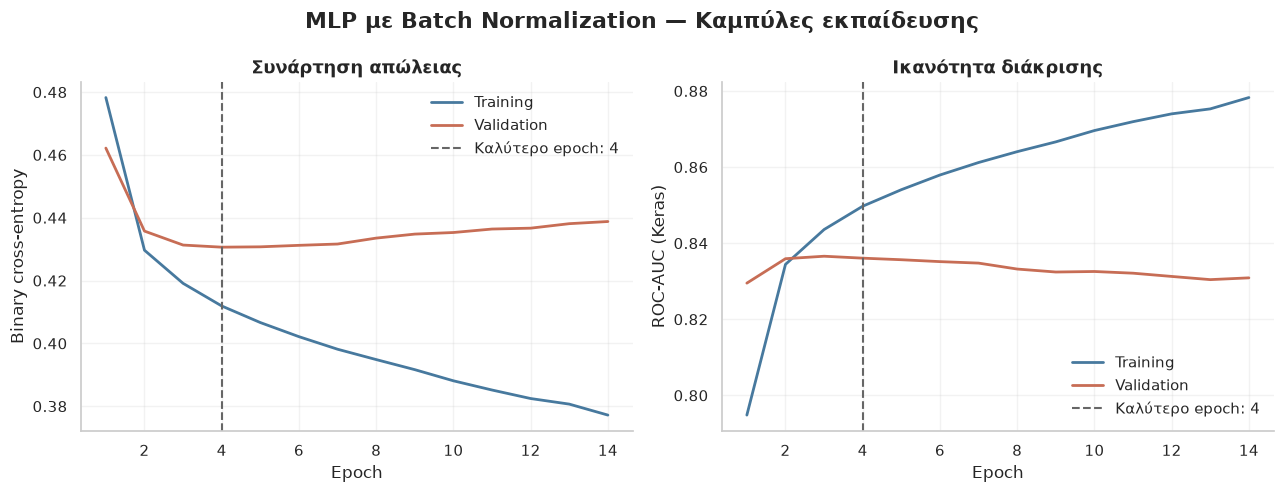

In [ ]:
# 1. Δημιουργία μοντέλου με Batch Normalization
keras.utils.set_random_seed(42)  # Ορίζουμε την τυχαιότητα για πιο εύκολη επανάληψη.

bn_model = keras.Sequential(
    [
        keras.Input(shape=(X_train_nn.shape[1],)),  # Μία θέση εισόδου για κάθε χαρακτηριστικό.

        layers.Dense(32, use_bias=False),  # Το επόμενο Batch Normalization καλύπτει τη μετατόπιση.
        layers.BatchNormalization(),  # Στην εκπαίδευση προσαρμόζει τις τιμές με βάση το batch.
        layers.Activation("relu"),

        layers.Dense(16, use_bias=False),  # Δεν χρειάζεται ξεχωριστός όρος bias εδώ.
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.Dense(1, activation="sigmoid")  # Μία έξοδος: εκτίμηση πιθανότητας αποχώρησης.
    ],
    name="mlp_batch_normalization"
)

bn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",  # Μετρά το σφάλμα των πιθανοτήτων για τις δύο κλάσεις.
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.AUC(name="auc")
    ]
)

bn_model.summary()

# 2. Ξεχωριστό callback για το νέο πείραμα
bn_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",  # Παρακολουθούμε το σφάλμα στο validation.
    mode="min",  # Μικρότερο σφάλμα σημαίνει καλύτερη επίδοση.
    patience=10,  # Περιμένουμε 10 epochs χωρίς βελτίωση πριν σταματήσουμε.
    restore_best_weights=True  # Κρατάμε τα βάρη του καλύτερου epoch.
)

# 3. Εκπαίδευση — μία γραμμή αποτελεσμάτων ανά epoch
bn_history = bn_model.fit(
    X_train_nn,
    y_train_nn,
    validation_data=(X_val_nn, y_val_nn),  # Τα δεδομένα αυτά ελέγχουν την επίδοση, δεν μαθαίνουν τα βάρη.
    epochs=100,  # Ανώτατο όριο το early stopping μπορεί να σταματήσει νωρίτερα.
    batch_size=32,  # Ενημερώνουμε τα βάρη ανά ομάδα 32 πελατών.
    callbacks=[bn_early_stopping],
    shuffle=True,  # Αλλάζουμε τη σειρά των πελατών σε κάθε epoch.
    verbose=2  # Εμφανίζουμε μία γραμμή ενημέρωσης ανά epoch.
)

bn_best_epoch = int(
    np.argmin(bn_history.history["val_loss"]) + 1  # Βρίσκουμε το καλύτερο epoch· η αρίθμηση ξεκινά από το 1.
)

print(
    "\nEpochs που εκτελέστηκαν:",
    len(bn_history.history["loss"])
)
print("Καλύτερο epoch:", bn_best_epoch)
print(
    "Καλύτερο validation loss:",
    round(min(bn_history.history["val_loss"]), 4)
)

# 4. Αξιολόγηση με τα επαναφερμένα βάρη του καλύτερου epoch
# Το predict() χρησιμοποιεί το Batch Normalization σε inference mode.
bn_val_probabilities = bn_model.predict(
    X_val_nn,
    verbose=0
).ravel()  # Μετατρέπουμε την έξοδο σε μία απλή σειρά τιμών.

bn_val_predictions = (
    bn_val_probabilities >= 0.50
).astype(int)  # Το False γίνεται 0 και το True γίνεται 1.

# Θετική κλάση: αποχώρηση πελάτη (Churn = 1)
bn_results = {
    "Model": "MLP + Batch Normalization",
    "Accuracy": accuracy_score(y_val, bn_val_predictions),
    "Precision": precision_score(
        y_val, bn_val_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_val, bn_val_predictions, zero_division=0
    ),
    "F1-score": f1_score(
        y_val, bn_val_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_val, bn_val_probabilities)
}

# 5. Σύγκριση όλων των μοντέλων μέχρι αυτό το στάδιο
comparison_df = pd.DataFrame(
    [
        baseline_results,
        mlp_results,
        dropout_results,
        l2_results,
        l1_results,
        bn_results
    ]
).set_index("Model")

print("\nΣύγκριση στο validation set — κατώφλι 0,50")
display(comparison_df.round(4))

# 6. Καμπύλες εκπαίδευσης
bn_history_df = pd.DataFrame(bn_history.history)
bn_history_df["Epoch"] = np.arange(
    1, len(bn_history_df) + 1
)

fig, axes = plt.subplots(ncols=2, figsize=(13, 5))

plot_settings = [
    (
        "loss", "val_loss",
        "Συνάρτηση απώλειας",
        "Binary cross-entropy"
    ),
    (
        "auc", "val_auc",
        "Ικανότητα διάκρισης",
        "ROC-AUC (Keras)"
    )
]

for ax, (train_metric, val_metric, title, ylabel) in zip(
    axes, plot_settings
):
    sns.lineplot(
        data=bn_history_df,
        x="Epoch",
        y=train_metric,
        label="Training",
        color="#47799E",
        linewidth=2,
        ax=ax
    )

    sns.lineplot(
        data=bn_history_df,
        x="Epoch",
        y=val_metric,
        label="Validation",
        color="#C76D55",
        linewidth=2,
        ax=ax
    )

    ax.axvline(
        bn_best_epoch,
        color="#666666",
        linestyle="--",
        linewidth=1.5,
        label=f"Καλύτερο epoch: {bn_best_epoch}"
    )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    ax.legend(frameon=False)
    sns.despine(ax=ax)

fig.suptitle(
    "MLP με Batch Normalization — Καμπύλες εκπαίδευσης",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout()

plt.show()  # Εμφανίζουμε το γράφημα μέσα στο notebook.


#### Αξιολόγηση του MLP με Batch Normalization

Το MLP με Batch Normalization πέτυχε στο validation set accuracy 78,50%, precision 59,85%, recall 57,50%, F1-score 58,65% και ROC-AUC 0,8360, με κατώφλι ταξινόμησης 0,50.

Σε σύγκριση με το αρχικό MLP, το recall αυξήθηκε από 52,50% σε 57,50%, ενώ η precision μειώθηκε από 66,52% σε 59,85%. Επομένως, το μοντέλο αναγνώρισε μεγαλύτερο ποσοστό των πραγματικών αποχωρήσεων, αλλά μεγαλύτερο ποσοστό των προβλεπόμενων αποχωρήσεων ήταν λανθασμένο. Το F1-score παρέμεινε σχεδόν ίδιο: 58,65% έναντι 58,68%.

Το Batch Normalization παρουσίασε το υψηλότερο recall μεταξύ των νευρωνικών δικτύων που εξετάστηκαν. Ωστόσο, η Logistic Regression διατήρησε υψηλότερο recall (59,29%) και F1-score (61,82%), καθώς και καλύτερες τιμές στις υπόλοιπες μετρικές του συγκριτικού πίνακα.

Οι καμπύλες δείχνουν ότι το training loss μειώνεται συνεχώς, ενώ το validation loss φτάνει στην ελάχιστη τιμή του στο epoch 4 και στη συνέχεια αυξάνεται. Παράλληλα, η training AUC συνεχίζει να βελτιώνεται, ενώ η validation AUC κορυφώνεται περίπου στο epoch 3 και κατόπιν υποχωρεί. Η απόκλιση αυτή αποτελεί σαφή ένδειξη υπερπροσαρμογής.

Η εκπαίδευση ολοκληρώθηκε στο epoch 14, μετά από 10 διαδοχικά epochs χωρίς βελτίωση του validation loss. Το early stopping επανέφερε τα βάρη του epoch 4, στο οποίο το validation loss ήταν περίπου 0,4306. Οι μετρικές του συγκριτικού πίνακα αφορούν το επαναφερμένο μοντέλο και όχι το τελευταίο epoch.

Κατά την ερμηνεία των καμπυλών πρέπει να λαμβάνεται υπόψη ότι το Batch Normalization χρησιμοποιεί στατιστικά των mini-batches στην εκπαίδευση και κινητούς μέσους όρους των στατιστικών στην αξιολόγηση. Ωστόσο, η σταδιακή επιδείνωση των validation μετρικών, ενώ οι training μετρικές βελτιώνονται, υποστηρίζει την παραπάνω ένδειξη υπερπροσαρμογής.

Συνολικά, η συγκεκριμένη εφαρμογή Batch Normalization δεν προσέφερε συνολική βελτίωση έναντι του αρχικού MLP. Το συμπέρασμα αφορά τη συγκεκριμένη αρχιτεκτονική, τις επιλεγμένες ρυθμίσεις και μία εκπαίδευση, όχι την αποτελεσματικότητα της τεχνικής γενικά.


### 13. Επιλογή κατωφλίου ταξινόμησης για το MLP με Dropout

Το MLP με Dropout παρουσίασε το υψηλότερο F1-score μεταξύ των νευρωνικών δικτύων στο κατώφλι 0,50. Στο επόμενο βήμα εξετάζουμε την επίδραση του κατωφλίου στις προβλέψεις του.

Το μοντέλο παράγει μια εκτιμώμενη πιθανότητα αποχώρησης για κάθε πελάτη. Το κατώφλι καθορίζει από ποια τιμή και πάνω ο πελάτης ταξινομείται ως πιθανή αποχώρηση.

Η μείωση του κατωφλίου αυξάνει τον αριθμό των πελατών που χαρακτηρίζονται ως πιθανές αποχωρήσεις. Αυτό συνήθως αυξάνει το recall, αλλά μπορεί να μειώσει την precision.

Εξετάζουμε κατώφλια από 0,10 έως 0,90, με βήμα 0,01, και επιλέγουμε εκείνο που μεγιστοποιεί το F1-score στο validation set. Το F1-score χρησιμοποιείται ως κριτήριο ισορροπίας μεταξύ precision και recall, καθώς δεν έχουμε ορίσει συγκεκριμένο επιχειρηματικό κόστος για τα διαφορετικά είδη σφάλματος.

Τα βάρη του μοντέλου παραμένουν σταθερά. Αλλάζει μόνο ο κανόνας μετατροπής των πιθανοτήτων σε κλάσεις. Επομένως, η ROC-AUC παραμένει ίδια.

Η επίδοση στο επιλεγμένο κατώφλι αποτελεί αποτέλεσμα ρύθμισης πάνω στο validation set και όχι ανεξάρτητη τελική αξιολόγηση. Η τελική απόδοση θα εξεταστεί στο test set, αφού οριστικοποιηθούν οι επιλογές.


Επιλεγμένο κατώφλι βάσει validation F1-score: 0.37

Πέντε καλύτερα κατώφλια:


,Threshold,Accuracy,Precision,Recall,F1-score
27,0.37,0.7765,0.5604,0.7286,0.6335
25,0.35,0.7699,0.5483,0.7500,0.6335
26,0.36,0.7737,0.5553,0.7357,0.6329
23,0.33,0.7633,0.5375,0.7679,0.6324
24,0.34,0.7661,0.5422,0.7571,0.6319



MLP με Dropout — Σύγκριση στο validation set


,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC
Ρύθμιση,,,,,,
Αρχικό κατώφλι,0.50,0.8059,0.6682,0.5321,0.5924,0.846
Επιλεγμένο κατώφλι,0.37,0.7765,0.5604,0.7286,0.6335,0.846


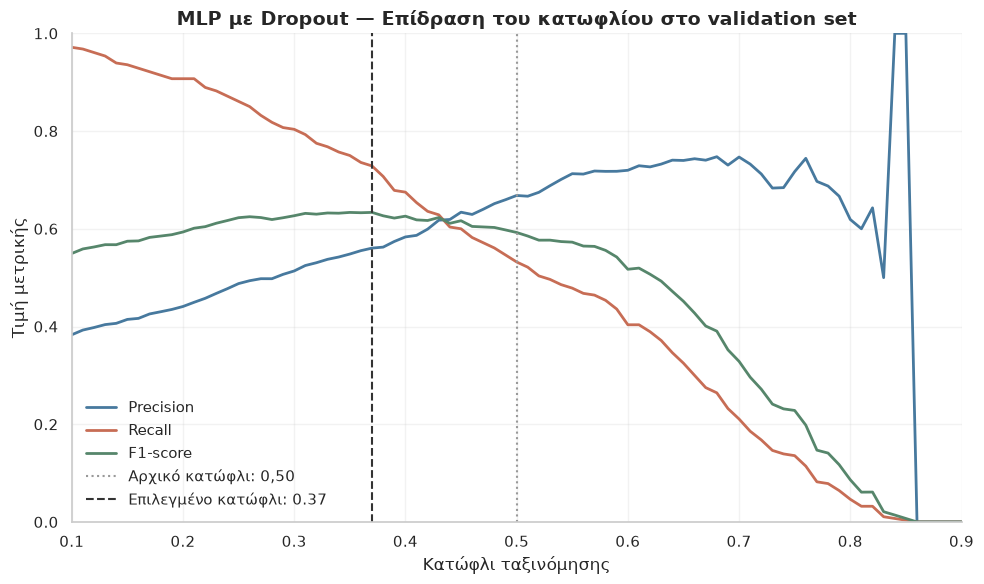

In [26]:
# 1. Πιθανότητες από το ήδη εκπαιδευμένο MLP με Dropout
# Δεν πραγματοποιείται νέα εκπαίδευση.
dropout_val_probabilities = dropout_model.predict(
    X_val_nn,
    verbose=0
).ravel()  # Μετατρέπουμε την έξοδο σε μία απλή σειρά τιμών.

# 2. Αξιολόγηση διαφορετικών κατωφλίων στο validation set
thresholds = np.round(np.linspace(0.10, 0.90, 81), 2)

threshold_results = []

for threshold in thresholds:
    predictions = (
        dropout_val_probabilities >= threshold
    ).astype(int)  # Το False γίνεται 0 και το True γίνεται 1.

    threshold_results.append(
        {
            "Threshold": threshold,
            "Accuracy": accuracy_score(y_val, predictions),
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "F1-score": f1_score(
                y_val, predictions, zero_division=0
            )
        }
    )

dropout_threshold_df = pd.DataFrame(threshold_results)

# 3. Επιλογή κατωφλίου με το υψηλότερο validation F1-score
# Σε ακριβή ισοβαθμία επιλέγεται το πλησιέστερο στο 0,50.
ranked_thresholds = (
    dropout_threshold_df
    .assign(
        Distance_from_050=lambda df: abs(df["Threshold"] - 0.50)
    )
    .sort_values(
        by=["F1-score", "Distance_from_050", "Threshold"],
        ascending=[False, True, True]
    )
)

dropout_best_threshold = float(
    ranked_thresholds.iloc[0]["Threshold"]
)

print(
    "Επιλεγμένο κατώφλι βάσει validation F1-score:",
    f"{dropout_best_threshold:.2f}"
)

print("\nΠέντε καλύτερα κατώφλια:")
display(
    ranked_thresholds
    .drop(columns="Distance_from_050")
    .head(5)  # Κρατάμε τις πέντε πρώτες γραμμές.
    .round(4)
)

# 4. Σύγκριση αρχικού και επιλεγμένου κατωφλίου
threshold_comparison_rows = []

dropout_validation_auc = roc_auc_score(
    y_val, dropout_val_probabilities
)

for setting, threshold in [
    ("Αρχικό κατώφλι", 0.50),
    ("Επιλεγμένο κατώφλι", dropout_best_threshold)
]:
    predictions = (
        dropout_val_probabilities >= threshold
    ).astype(int)

    threshold_comparison_rows.append(
        {
            "Ρύθμιση": setting,
            "Threshold": threshold,
            "Accuracy": accuracy_score(y_val, predictions),
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "F1-score": f1_score(
                y_val, predictions, zero_division=0
            ),
            "ROC-AUC": dropout_validation_auc
        }
    )

dropout_threshold_comparison_df = pd.DataFrame(
    threshold_comparison_rows
).set_index("Ρύθμιση")

print("\nMLP με Dropout — Σύγκριση στο validation set")
display(dropout_threshold_comparison_df.round(4))

# 5. Γράφημα επίδρασης του κατωφλίου
fig, ax = plt.subplots(figsize=(10, 6))

metric_colors = {
    "Precision": "#47799E",
    "Recall": "#C76D55",
    "F1-score": "#56866B"
}

for metric, color in metric_colors.items():
    sns.lineplot(
        data=dropout_threshold_df,
        x="Threshold",
        y=metric,
        label=metric,
        color=color,
        linewidth=2,
        ax=ax
    )

ax.axvline(
    0.50,
    color="#999999",
    linestyle=":",
    linewidth=1.5,
    label="Αρχικό κατώφλι: 0,50"
)

ax.axvline(
    dropout_best_threshold,
    color="#333333",
    linestyle="--",
    linewidth=1.5,
    label=f"Επιλεγμένο κατώφλι: {dropout_best_threshold:.2f}"
)

ax.set_title(
    "MLP με Dropout — Επίδραση του κατωφλίου στο validation set",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Κατώφλι ταξινόμησης")
ax.set_ylabel("Τιμή μετρικής")
ax.set_xlim(0.10, 0.90)
ax.set_ylim(0, 1)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
sns.despine(ax=ax)

fig.tight_layout()

plt.show()  # Εμφανίζουμε το γράφημα μέσα στο notebook.


#### Αξιολόγηση της επιλογής κατωφλίου

Εξετάστηκαν κατώφλια ταξινόμησης από 0,10 έως 0,90, με βήμα 0,01, χρησιμοποιώντας τις πιθανότητες του ήδη εκπαιδευμένου MLP με Dropout στο validation set. Η διαδικασία επέλεξε το κατώφλι 0,37 με βάση το υψηλότερο F1-score.

Με τη μείωση του κατωφλίου από 0,50 σε 0,37:

- Το recall αυξήθηκε από 53,21% σε 72,86%, δηλαδή κατά 19,65 ποσοστιαίες μονάδες.
- Η precision μειώθηκε από 66,82% σε 56,04%.
- Το F1-score αυξήθηκε από 59,24% σε 63,35%.
- Η accuracy μειώθηκε από 80,59% σε 77,65%.
- Η ROC-AUC παρέμεινε σταθερή στο 0,8460.

Η αύξηση του recall σημαίνει ότι αναγνωρίζεται μεγαλύτερο ποσοστό των πελατών που πραγματικά αποχωρούν. Ωστόσο, η μείωση της precision δείχνει ότι μεγαλύτερο ποσοστό των πελατών που χαρακτηρίζονται ως πιθανές αποχωρήσεις δεν αποχωρεί πραγματικά. Επομένως, η βελτίωση στον εντοπισμό αποχωρήσεων συνοδεύεται από περισσότερους λανθασμένους συναγερμούς.

Το υψηλότερο F1-score υποδηλώνει καλύτερη ισορροπία precision και recall σύμφωνα με το συγκεκριμένο κριτήριο. Η χαμηλότερη accuracy δείχνει ότι δεν βελτιώθηκαν όλες οι πλευρές της απόδοσης ταυτόχρονα.

Τα κατώφλια 0,35 και 0,37 εμφανίζουν το ίδιο F1-score (0,6335) μετά τη στρογγυλοποίηση στα τέσσερα δεκαδικά. Ο κώδικας χρησιμοποιεί τις πλήρεις τιμές και, σε ακριβή ισοβαθμία, επιλέγει το κατώφλι που βρίσκεται πιο κοντά στο 0,50. Από τον στρογγυλοποιημένο πίνακα δεν μπορούμε να διακρίνουμε αν υπήρξε ακριβής ισοβαθμία ή μικρή διαφορά στα επόμενα δεκαδικά ψηφία.

Στο 0,35 το recall είναι υψηλότερο από ό,τι στο 0,37 (75,00% έναντι 72,86%), αλλά η precision χαμηλότερη (54,83% έναντι 56,04%). Οι κοντινές τιμές F1-score στην περιοχή 0,33–0,37 δείχνουν ότι το 0,37 δεν πρέπει να θεωρηθεί ένα μοναδικό, καθολικά βέλτιστο όριο.

Στο γράφημα, το recall μειώνεται καθώς αυξάνεται το κατώφλι, ενώ η precision γενικά αυξάνεται, χωρίς να ακολουθεί αυστηρά μονότονη πορεία. Το F1-score φτάνει στις υψηλότερες τιμές του σε ενδιάμεσα κατώφλια και στη συνέχεια υποχωρεί, καθώς χάνονται περισσότερες πραγματικές αποχωρήσεις.

Οι έντονες διακυμάνσεις της precision στα πολύ υψηλά κατώφλια συνδέονται με τον μικρό αριθμό θετικών προβλέψεων. Μια υψηλή precision σε εκείνη την περιοχή δεν σημαίνει αποτελεσματικό εντοπισμό αποχωρήσεων, καθώς το recall είναι σχεδόν μηδενικό. Όταν δεν υπάρχουν θετικές προβλέψεις, ο κώδικας αποδίδει precision ίση με μηδέν μέσω της ρύθμισης zero_division=0.

Η ROC-AUC παραμένει ίδια επειδή υπολογίζεται από τις αρχικές πιθανότητες, οι οποίες δεν μεταβλήθηκαν. Δεν έγινε νέα εκπαίδευση ούτε άλλαξαν τα βάρη του μοντέλου.

Από επιχειρηματική άποψη, το χαμηλότερο κατώφλι μπορεί να είναι χρήσιμο όταν προτεραιότητα είναι η έγκαιρη αναγνώριση περισσότερων πελατών που κινδυνεύουν να αποχωρήσουν. Ωστόσο, αυξάνει τον αριθμό των πελατών που μπορεί να λάβουν περιττές παρεμβάσεις διατήρησης. Χωρίς στοιχεία για το κόστος των παρεμβάσεων και των χαμένων πελατών, δεν μπορούμε να χαρακτηρίσουμε το 0,37 ως οικονομικά βέλτιστο κατώφλι.

Συνολικά, το 0,37 προσφέρει υψηλότερο validation F1-score από το αρχικό 0,50. Επειδή επιλέχθηκε στο ίδιο validation set, η βελτίωση αυτή χρειάζεται επιβεβαίωση κατά την τελική αξιολόγηση στο test set.


### 14. Πείραμα με residual/skip connections

Σύμφωνα με την εκφώνηση, εξετάζουμε ένα MLP με residual connection, χρησιμοποιώντας το Functional API του Keras, το οποίο επιτρέπει τη δημιουργία διακλαδώσεων.

Αρχικά, ένα Dense επίπεδο μετατρέπει τα χαρακτηριστικά εισόδου σε αναπαράσταση 32 διαστάσεων. Στη συνέχεια, η αναπαράσταση ακολουθεί δύο διαδρομές:

- Μια κύρια διαδρομή με δύο Dense επίπεδα των 32 νευρώνων.
- Μια διαδρομή παράκαμψης που τη μεταφέρει χωρίς αλλαγή.

Οι δύο έξοδοι προστίθενται στοιχείο προς στοιχείο και εφαρμόζεται ReLU. Η πρόσθεση είναι εφικτή επειδή και οι δύο διαδρομές έχουν έξοδο 32 διαστάσεων. Ακολουθούν ένα Dense επίπεδο 16 νευρώνων με ReLU και ένας νευρώνας εξόδου με sigmoid.

Η residual σύνδεση επιτρέπει στο block να μάθει μια τροποποίηση της εισερχόμενης αναπαράστασης και παρέχει μια επιπλέον διαδρομή για τη διάδοση των gradients. Δεν εγγυάται καλύτερη απόδοση ή αποφυγή υπερπροσαρμογής.

Διατηρούμε Adam με learning rate 0,001, batch size 32, μέγιστο αριθμό 100 epochs και early stopping με patience 10 με βάση το validation loss. Δεν προσθέτουμε Dropout, L1/L2 ή Batch Normalization.

Το μοντέλο έχει περισσότερα επίπεδα και παραμέτρους από το αρχικό MLP. Επομένως, η σύγκριση αξιολογεί τη συνολική νέα αρχιτεκτονική και δεν απομονώνει αποκλειστικά την επίδραση της residual σύνδεσης. Για τέτοια απομόνωση θα χρειαζόταν επιπλέον σύγκριση με την ίδια αρχιτεκτονική χωρίς τη σύνδεση παράκαμψης.

Η αξιολόγηση γίνεται στο ίδιο validation set με τις ίδιες μετρικές και κατώφλι 0,50. Το κατώφλι 0,37 της προηγούμενης ενότητας αφορούσε το MLP με Dropout και δεν μεταφέρεται αυτόματα στο νέο μοντέλο.


Model: "mlp_residual"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_features      │ (None, 46)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_representati… │ (None, 32)        │      1,504 │ input_features[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_dense_1    │ (None, 32)        │      1,056 │ input_representa… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_dense_2    │ (None, 32)        │      1,056 │ residual_dense_1… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_add (Add)  │ (None, 32)        │          0 │ input_representa… │
│                     │                   │            │ residual_dense_2… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_activation │ (None, 32)        │          0 │ residual_add[0][… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ final_hidden        │ (None, 16)        │        528 │ residual_activat… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ churn_probability   │ (None, 1)         │         17 │ final_hidden[0][… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,161 (16.25 KB)

 Trainable params: 4,161 (16.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
155/155 - 1s - 8ms/step - accuracy: 0.7799 - auc: 0.8006 - loss: 0.4603 - val_accuracy: 0.7964 - val_auc: 0.8361 - val_loss: 0.4296
Epoch 2/100
155/155 - 0s - 733us/step - accuracy: 0.7988 - auc: 0.8378 - loss: 0.4245 - val_accuracy: 0.7955 - val_auc: 0.8415 - val_loss: 0.4234
Epoch 3/100
155/155 - 0s - 747us/step - accuracy: 0.7998 - auc: 0.8424 - loss: 0.4193 - val_accuracy: 0.8011 - val_auc: 0.8433 - val_loss: 0.4208
Epoch 4/100
155/155 - 0s - 795us/step - accuracy: 0.8030 - auc: 0.8455 - loss: 0.4158 - val_accuracy: 0.8068 - val_auc: 0.8435 - val_loss: 0.4202
Epoch 5/100
155/155 - 0s - 741us/step - accuracy: 0.8055 - auc: 0.8481 - loss: 0.4130 - val_accuracy: 0.8030 - val_auc: 0.8440 - val_loss: 0.4196
Epoch 6/100
155/155 - 0s - 773us/step - accuracy: 0.8099 - auc: 0.8503 - loss: 0.4102 - val_accuracy: 0.7936 - val_auc: 0.8444 - val_loss: 0.4197
Epoch 7/100
155/155 - 0s - 747us/step - accuracy: 0.8112 - auc: 0.8524 - loss: 0.4077 - val_accuracy: 0.7983 - val_auc: 0.8435

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.8059,0.6459,0.5929,0.6182,0.8453
Initial MLP,0.8040,0.6652,0.5250,0.5868,0.8456
MLP + Dropout,0.8059,0.6682,0.5321,0.5924,0.8460
MLP + L2,0.8097,0.6946,0.5036,0.5839,0.8450
MLP + L1,0.7992,0.6619,0.4964,0.5673,0.8473
MLP + Batch Normalization,0.7850,0.5985,0.5750,0.5865,0.8360
MLP + Residual Connection,0.8030,0.6651,0.5179,0.5823,0.8440


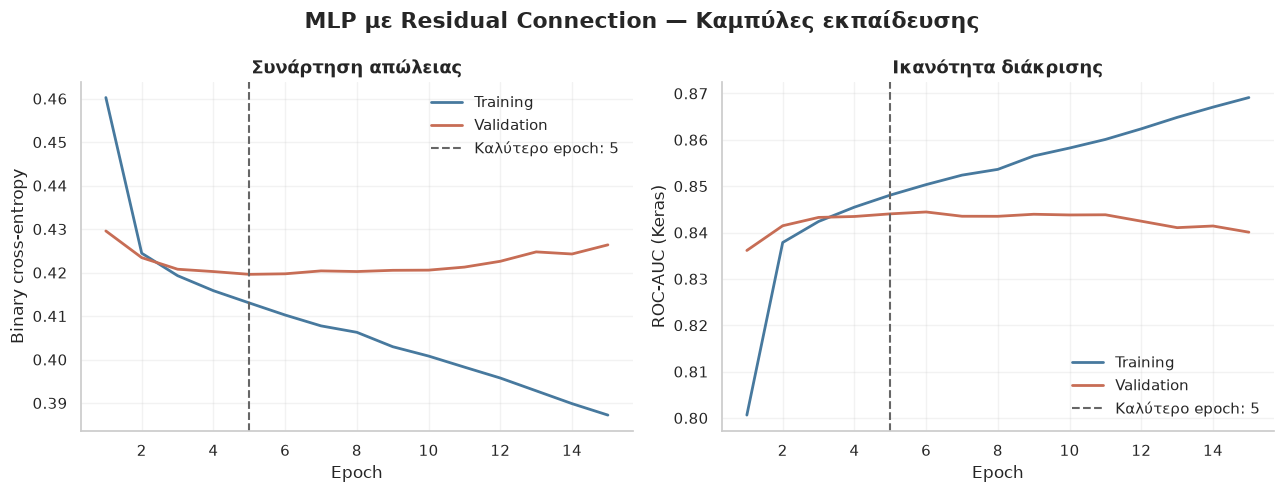

In [ ]:
# 1. Δημιουργία residual MLP με το Functional API
keras.utils.set_random_seed(42)  # Ορίζουμε την τυχαιότητα για πιο εύκολη επανάληψη.

residual_inputs = keras.Input(
    shape=(X_train_nn.shape[1],),
    name="input_features"
)

# Αρχική αναπαράσταση 32 διαστάσεων
residual_x = layers.Dense(
    32,
    activation="relu",
    name="input_representation"
)(residual_inputs)

# Διαδρομή παράκαμψης — χωρίς μετασχηματισμό
residual_shortcut = residual_x  # Κρατάμε την είσοδο για να την προσθέσουμε πιο κάτω.

# Κύρια διαδρομή του residual block
residual_branch = layers.Dense(
    32,
    activation="relu",
    name="residual_dense_1"
)(residual_x)

residual_branch = layers.Dense(
    32,
    activation=None,  # Εδώ αφήνουμε την έξοδο χωρίς συνάρτηση ενεργοποίησης.
    name="residual_dense_2"
)(residual_branch)

# Πρόσθεση δύο αναπαραστάσεων ίδιων διαστάσεων
residual_x = layers.Add(name="residual_add")(
    [residual_shortcut, residual_branch]  # Προσθέτουμε την αρχική πληροφορία στη νέα αναπαράσταση.
)

residual_x = layers.Activation(
    "relu",
    name="residual_activation"
)(residual_x)

# Τελικό κρυφό επίπεδο και έξοδος
residual_x = layers.Dense(
    16,
    activation="relu",
    name="final_hidden"
)(residual_x)

residual_outputs = layers.Dense(
    1,
    activation="sigmoid",
    name="churn_probability"
)(residual_x)

residual_model = keras.Model(
    inputs=residual_inputs,
    outputs=residual_outputs,
    name="mlp_residual"
)

residual_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",  # Μετρά το σφάλμα των πιθανοτήτων για τις δύο κλάσεις.
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.AUC(name="auc")
    ]
)

residual_model.summary()

# 2. Ξεχωριστό callback για το νέο πείραμα
residual_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",  # Παρακολουθούμε το σφάλμα στο validation.
    mode="min",  # Μικρότερο σφάλμα σημαίνει καλύτερη επίδοση.
    patience=10,  # Περιμένουμε 10 epochs χωρίς βελτίωση πριν σταματήσουμε.
    restore_best_weights=True  # Κρατάμε τα βάρη του καλύτερου epoch.
)

# 3. Εκπαίδευση — μία γραμμή αποτελεσμάτων ανά epoch
residual_history = residual_model.fit(
    X_train_nn,
    y_train_nn,
    validation_data=(X_val_nn, y_val_nn),  # Τα δεδομένα αυτά ελέγχουν την επίδοση, δεν μαθαίνουν τα βάρη.
    epochs=100,  # Ανώτατο όριο το early stopping μπορεί να σταματήσει νωρίτερα.
    batch_size=32,  # Ενημερώνουμε τα βάρη ανά ομάδα 32 πελατών.
    callbacks=[residual_early_stopping],
    shuffle=True,  # Αλλάζουμε τη σειρά των πελατών σε κάθε epoch.
    verbose=2  # Εμφανίζουμε μία γραμμή ενημέρωσης ανά epoch.
)

residual_best_epoch = int(
    np.argmin(residual_history.history["val_loss"]) + 1  # Βρίσκουμε το καλύτερο epoch η αρίθμηση ξεκινά από το 1.
)

print(
    "\nEpochs που εκτελέστηκαν:",
    len(residual_history.history["loss"])
)
print("Καλύτερο epoch:", residual_best_epoch)
print(
    "Καλύτερο validation loss:",
    round(min(residual_history.history["val_loss"]), 4)
)

# 4. Αξιολόγηση με τα επαναφερμένα βάρη του καλύτερου epoch
residual_val_probabilities = residual_model.predict(
    X_val_nn,
    verbose=0
).ravel()  # Μετατρέπουμε την έξοδο σε μία απλή σειρά τιμών.

# Ίδιο κατώφλι με τον βασικό συγκριτικό πίνακα
residual_val_predictions = (
    residual_val_probabilities >= 0.50
).astype(int)  # Το False γίνεται 0 και το True γίνεται 1.

residual_results = {
    "Model": "MLP + Residual Connection",
    "Accuracy": accuracy_score(
        y_val, residual_val_predictions
    ),
    "Precision": precision_score(
        y_val, residual_val_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_val, residual_val_predictions, zero_division=0
    ),
    "F1-score": f1_score(
        y_val, residual_val_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_val, residual_val_probabilities
    )
}

# 5. Σύγκριση όλων των μοντέλων στο κατώφλι 0,50
comparison_df = pd.DataFrame(
    [
        baseline_results,
        mlp_results,
        dropout_results,
        l2_results,
        l1_results,
        bn_results,
        residual_results
    ]
).set_index("Model")

print("\nΣύγκριση στο validation set — κατώφλι 0,50")
display(comparison_df.round(4))

# 6. Καμπύλες εκπαίδευσης
residual_history_df = pd.DataFrame(residual_history.history)
residual_history_df["Epoch"] = np.arange(
    1, len(residual_history_df) + 1
)

fig, axes = plt.subplots(ncols=2, figsize=(13, 5))

plot_settings = [
    (
        "loss", "val_loss",
        "Συνάρτηση απώλειας",
        "Binary cross-entropy"
    ),
    (
        "auc", "val_auc",
        "Ικανότητα διάκρισης",
        "ROC-AUC (Keras)"
    )
]

for ax, (train_metric, val_metric, title, ylabel) in zip(
    axes, plot_settings
):
    sns.lineplot(
        data=residual_history_df,
        x="Epoch",
        y=train_metric,
        label="Training",
        color="#47799E",
        linewidth=2,
        ax=ax
    )

    sns.lineplot(
        data=residual_history_df,
        x="Epoch",
        y=val_metric,
        label="Validation",
        color="#C76D55",
        linewidth=2,
        ax=ax
    )

    ax.axvline(
        residual_best_epoch,
        color="#666666",
        linestyle="--",
        linewidth=1.5,
        label=f"Καλύτερο epoch: {residual_best_epoch}"
    )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    ax.legend(frameon=False)
    sns.despine(ax=ax)

fig.suptitle(
    "MLP με Residual Connection — Καμπύλες εκπαίδευσης",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout()

plt.show()  # Εμφανίζουμε το γράφημα μέσα στο notebook.


#### Αξιολόγηση του MLP με Residual Connection

Το MLP με residual connection πέτυχε στο validation set accuracy 80,30%, precision 66,51%, recall 51,79%, F1-score 58,23% και ROC-AUC 0,8440, με κατώφλι ταξινόμησης 0,50.

Σε σύγκριση με το αρχικό MLP, η accuracy μειώθηκε ελαφρώς από 80,40% σε 80,30%, ενώ η precision παρέμεινε σχεδόν ίδια: 66,52% έναντι 66,51%. Το recall μειώθηκε από 52,50% σε 51,79%, το F1-score από 58,68% σε 58,23% και η ROC-AUC από 0,8456 σε 0,8440.

Επομένως, η νέα αρχιτεκτονική δεν παρουσίασε βελτίωση έναντι του αρχικού MLP στη συγκεκριμένη εκπαίδευση. Οι διαφορές είναι μικρές και δεν επαρκούν για συμπέρασμα σταθερής υπεροχής του ενός μοντέλου χωρίς επαναλαμβανόμενες εκπαιδεύσεις.

Οι καμπύλες δείχνουν ότι το training loss μειώνεται συνεχώς και η training AUC αυξάνεται. Αντίθετα, το validation loss φτάνει στην ελάχιστη τιμή του περίπου στο 0,420 στο epoch 5 και στη συνέχεια παραμένει σχεδόν σταθερό πριν αρχίσει να αυξάνεται. Η validation AUC παρουσιάζει μικρές διακυμάνσεις και υποχωρεί προς το τέλος της εκπαίδευσης.

Η αυξανόμενη απόσταση μεταξύ training και validation επιδόσεων αποτελεί ένδειξη υπερπροσαρμογής. Η residual σύνδεση δεν απέτρεψε αυτή τη συμπεριφορά: ο ρόλος της είναι να διευκολύνει τη ροή πληροφορίας και gradients, όχι να εγγυάται καλύτερη γενίκευση.

Το early stopping επέλεξε το epoch 5 με βάση το χαμηλότερο validation loss και επανέφερε τα βάρη του. Οι μετρικές του συγκριτικού πίνακα αφορούν αυτό το μοντέλο και όχι τα βάρη του τελευταίου epoch.

Η αρχιτεκτονική διαθέτει περισσότερα επίπεδα και παραμέτρους από το αρχικό MLP. Επομένως, τα αποτελέσματα αξιολογούν τη συνολική αρχιτεκτονική και δεν απομονώνουν την επίδραση της residual σύνδεσης. Για να εξεταστεί αποκλειστικά αυτή η επίδραση, θα απαιτούνταν σύγκριση με το ίδιο δίκτυο χωρίς τη σύνδεση παράκαμψης.

Συνολικά, η πρόσθετη πολυπλοκότητα δεν συνοδεύτηκε από βελτίωση των validation μετρικών στο συγκεκριμένο πείραμα. Στο κοινό κατώφλι 0,50, η Logistic Regression εξακολουθεί να εμφανίζει το υψηλότερο recall και F1-score, ενώ το MLP με Dropout διατηρεί το υψηλότερο F1-score μεταξύ των νευρωνικών δικτύων που εξετάστηκαν.


### 15. Hyperparameter tuning με Optuna

Πραγματοποιούμε αναζήτηση υπερπαραμέτρων με Optuna, σύμφωνα με τις απαιτήσεις της εκφώνησης.

Εστιάζουμε σε MLP με δύο κρυφά επίπεδα και προαιρετικό Dropout. Η οικογένεια αυτή επιλέγεται επειδή το MLP με Dropout παρουσίασε το υψηλότερο F1-score μεταξύ των νευρωνικών δικτύων στο κοινό κατώφλι 0,50.

Εξετάζουμε τις ακόλουθες υπερπαραμέτρους:

| Υπερπαράμετρος | Υποψήφιες τιμές |
|---|---|
| Νευρώνες πρώτου κρυφού επιπέδου | 16, 32, 64 |
| Νευρώνες δεύτερου κρυφού επιπέδου | 8, 16, 32 |
| Dropout rate μετά από κάθε κρυφό επίπεδο | 0,00, 0,10, 0,20, 0,30 |
| Learning rate του Adam | 0,0003, 0,001, 0,003 |

Διατηρούμε ReLU στα κρυφά επίπεδα, sigmoid στην έξοδο και batch size 32. Δεν προσθέτουμε L1/L2, Batch Normalization ή residual connections.

Εκτελούμε 20 trials με τον sampler TPE και seed 42. Ο αριθμός αυτός αποτελεί προκαθορισμένο υπολογιστικό όριο και όχι εξαντλητικό έλεγχο όλων των συνδυασμών.

Κάθε trial δημιουργεί και εκπαιδεύει νέο μοντέλο για έως 100 epochs, με early stopping με βάση το validation loss, patience 10 και επαναφορά των βαρών του καλύτερου epoch.

Ως κριτήριο αναζήτησης ορίζουμε το ελάχιστο validation binary cross-entropy. Έτσι αξιολογούμε τις προβλεπόμενες πιθανότητες χωρίς να εξαρτάται η αναζήτηση από ένα συγκεκριμένο κατώφλι ταξινόμησης. Η ελαχιστοποίηση του loss δεν εγγυάται μέγιστο F1-score ή ROC-AUC.

Κρατάμε στη μνήμη το καλύτερο μοντέλο της αναζήτησης και το αξιολογούμε με accuracy, precision, recall, F1-score και ROC-AUC. Για τη σύγκριση με τα προηγούμενα πειράματα χρησιμοποιούμε κατώφλι 0,50.

Η αναζήτηση χρησιμοποιεί αποκλειστικά τα training και validation δεδομένα. Επειδή το validation set καθοδηγεί την επιλογή, οι επιδόσεις του δεν αποτελούν ανεξάρτητη τελική αξιολόγηση. Το test set διατηρείται για την αξιολόγηση μετά την οριστικοποίηση των επιλογών.

Το επιλεγμένο μοντέλο είναι το καλύτερο μεταξύ των δοκιμών που εκτελέστηκαν σύμφωνα με το συγκεκριμένο κριτήριο, όχι απαραίτητα το καλύτερο δυνατό μοντέλο.



Trial 1/20
Νευρώνες: 32 → 8 | Dropout: 0.10 | Learning rate: 0.001
Εκπαίδευση...


/Users/loukito/Projects/Neural Nets Assignment/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Ολοκληρώθηκαν 30 epochs. Καλύτερο epoch: 20
Πέντε καλύτερα epochs βάσει validation loss:


,Epoch,Train loss,Validation loss,Train accuracy,Validation accuracy,Train AUC,Validation AUC
0,20,0.41232,0.41785,0.80548,0.80303,0.84962,0.84540
1,18,0.41642,0.41826,0.80710,0.80208,0.84660,0.84643
2,19,0.41437,0.41833,0.80953,0.80398,0.84865,0.84496
3,27,0.40600,0.41842,0.81136,0.79830,0.85481,0.84528
4,29,0.40265,0.41866,0.81684,0.79545,0.85806,0.84490



Trial 2/20
Νευρώνες: 16 → 16 | Dropout: 0.10 | Learning rate: 0.003
Εκπαίδευση...
Ολοκληρώθηκαν 20 epochs. Καλύτερο epoch: 10
Πέντε καλύτερα epochs βάσει validation loss:


,Epoch,Train loss,Validation loss,Train accuracy,Validation accuracy,Train AUC,Validation AUC
0,10,0.40987,0.41862,0.80872,0.80208,0.85101,0.84650
1,5,0.42084,0.41955,0.80020,0.80114,0.84172,0.84423
2,9,0.41461,0.41969,0.80467,0.80019,0.84836,0.84410
3,6,0.41912,0.42031,0.80385,0.80398,0.84368,0.84368
4,7,0.41557,0.42039,0.80588,0.80492,0.84648,0.84400


... (43 outputs left out)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 3,556 (13.89 KB)


Σύγκριση στο validation set — κατώφλι 0,50


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.8059,0.6459,0.5929,0.6182,0.8453
Initial MLP,0.8040,0.6652,0.5250,0.5868,0.8456
MLP + Dropout,0.8059,0.6682,0.5321,0.5924,0.8460
MLP + L2,0.8097,0.6946,0.5036,0.5839,0.8450
MLP + L1,0.7992,0.6619,0.4964,0.5673,0.8473
MLP + Batch Normalization,0.7850,0.5985,0.5750,0.5865,0.8360
MLP + Residual Connection,0.8030,0.6651,0.5179,0.5823,0.8440
MLP + Optuna,0.8078,0.6453,0.6107,0.6275,0.8482


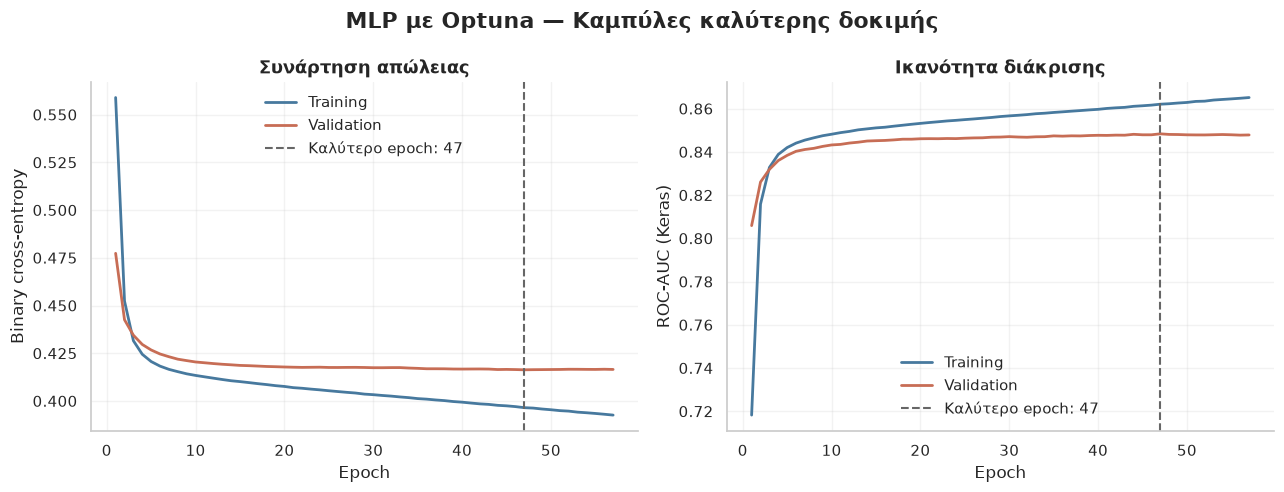

In [ ]:
import optuna

# Απόκρυψη των ενημερωτικών logs του Optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# 1. Ρυθμίσεις αναζήτησης


tuning_best = {
    "val_loss": float("inf"),
    "model": None,  # Εδώ θα κρατηθεί το καλύτερο εκπαιδευμένο μοντέλο.
    "trial_number": None,
    "history": None
}

# Διατηρούμε το ιστορικό κάθε trial για μελλοντική προβολή.
tuning_histories = {}

N_TRIALS = 20  # Δοκιμάζουμε 20 συνδυασμούς ρυθμίσεων.

# 2. Συνάρτηση που εκτελείται για κάθε trial
def objective(trial):
    keras.utils.set_random_seed(42)  # Ορίζουμε την τυχαιότητα για πιο εύκολη επανάληψη.

    units_1 = trial.suggest_categorical(
        "units_1", [16, 32, 64]
    )
    units_2 = trial.suggest_categorical(
        "units_2", [8, 16, 32]
    )
    dropout_rate = trial.suggest_categorical(
        "dropout_rate", [0.0, 0.1, 0.2, 0.3]
    )
    learning_rate = trial.suggest_categorical(
        "learning_rate", [0.0003, 0.001, 0.003]
    )

    print(f"\nTrial {trial.number + 1}/{N_TRIALS}")
    print(
        f"Νευρώνες: {units_1} → {units_2} | "
        f"Dropout: {dropout_rate:.2f} | "
        f"Learning rate: {learning_rate:g}"
    )
    print("Εκπαίδευση...", flush=True)

    # Νέο μοντέλο για κάθε trial
    trial_model = keras.Sequential(
        [
            keras.Input(shape=(X_train_nn.shape[1],)),  # Μία θέση εισόδου για κάθε χαρακτηριστικό.
            layers.Dense(units_1, activation="relu"),
            layers.Dropout(dropout_rate),
            layers.Dense(units_2, activation="relu"),
            layers.Dropout(dropout_rate),
            layers.Dense(1, activation="sigmoid")  # Μία έξοδος: εκτίμηση πιθανότητας αποχώρησης.
        ],
        name=f"mlp_trial_{trial.number}"
    )

    trial_model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",  # Μετρά το σφάλμα των πιθανοτήτων για τις δύο κλάσεις.
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.AUC(name="auc")
        ]
    )

    trial_early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",  # Παρακολουθούμε το σφάλμα στο validation.
        mode="min",  # Μικρότερο σφάλμα σημαίνει καλύτερη επίδοση.
        patience=10,  # Περιμένουμε 10 epochs χωρίς βελτίωση πριν σταματήσουμε.
        restore_best_weights=True  # Κρατάμε τα βάρη του καλύτερου epoch.
    )

    # Δεν εμφανίζονται τα αναλυτικά logs των epochs.
    trial_history = trial_model.fit(
        X_train_nn,
        y_train_nn,
        validation_data=(X_val_nn, y_val_nn),  # Τα δεδομένα αυτά ελέγχουν την επίδοση, δεν μαθαίνουν τα βάρη.
        epochs=100,  # Ανώτατο όριο το early stopping μπορεί να σταματήσει νωρίτερα.
        batch_size=32,  # Ενημερώνουμε τα βάρη ανά ομάδα 32 πελατών.
        callbacks=[trial_early_stopping],
        shuffle=True,  # Αλλάζουμε τη σειρά των πελατών σε κάθε epoch.
        verbose=0
    )

    best_epoch = int(
        np.argmin(trial_history.history["val_loss"]) + 1  # Βρίσκουμε το καλύτερο epoch η αρίθμηση ξεκινά από το 1.
    )
    best_val_loss = float(
        min(trial_history.history["val_loss"])
    )
    epochs_run = len(trial_history.history["loss"])

    trial.set_user_attr("best_epoch", best_epoch)
    trial.set_user_attr("epochs_run", epochs_run)

    # 3. Ιστορικό και πέντε καλύτερα epochs του trial
    trial_history_df = pd.DataFrame(trial_history.history)
    trial_history_df.insert(
        0,
        "Epoch",
        np.arange(1, len(trial_history_df) + 1)
    )

    tuning_histories[trial.number + 1] = trial_history_df.copy()

    top_epochs_df = (
        trial_history_df
        .sort_values(
            by=["val_loss", "Epoch"],
            ascending=[True, True]
        )
        .head(5)  # Κρατάμε τις πέντε πρώτες γραμμές.
        .loc[
            :,
            [
                "Epoch",
                "loss",
                "val_loss",
                "accuracy",
                "val_accuracy",
                "auc",
                "val_auc"
            ]
        ]
        .rename(
            columns={
                "loss": "Train loss",
                "val_loss": "Validation loss",
                "accuracy": "Train accuracy",
                "val_accuracy": "Validation accuracy",
                "auc": "Train AUC",
                "val_auc": "Validation AUC"
            }
        )
        .reset_index(drop=True)  # Βάζουμε νέα αρίθμηση γραμμών, χωρίς την παλιά.
    )

    print(
        f"Ολοκληρώθηκαν {epochs_run} epochs. "
        f"Καλύτερο epoch: {best_epoch}"
    )
    print("Πέντε καλύτερα epochs βάσει validation loss:")
    display(top_epochs_df.round(5))

    # Αποθήκευση του καλύτερου μοντέλου της αναζήτησης.
    # Τα βάρη του καλύτερου epoch έχουν ήδη επαναφερθεί.
    if best_val_loss < tuning_best["val_loss"]:
        tuning_best["model"] = trial_model  # Κρατάμε το καλύτερο δίκτυο στη μνήμη.

        tuning_best["val_loss"] = best_val_loss
        tuning_best["trial_number"] = trial.number
        tuning_best["history"] = {
            metric: list(values)
            for metric, values in trial_history.history.items()
        }

    return best_val_loss

# 4. Δημιουργία και εκτέλεση αναζήτησης
study = optuna.create_study(
    direction="minimize",  # Το Optuna αναζητά το μικρότερο validation loss.
    sampler=optuna.samplers.TPESampler(seed=42),
    study_name="mlp_hyperparameter_search"
)

study.optimize(
    objective,
    n_trials=N_TRIALS,
    n_jobs=1,  # Οι δοκιμές εκτελούνται μία κάθε φορά.
    gc_after_trial=True
)

# 5. Συνολικός πίνακας δοκιμών
trial_rows = []

for trial in study.trials:
    if trial.state == optuna.trial.TrialState.COMPLETE:
        trial_rows.append(
            {
                "Trial": trial.number + 1,
                **trial.params,
                "Best epoch": trial.user_attrs["best_epoch"],
                "Epochs run": trial.user_attrs["epochs_run"],
                "Validation loss": trial.value
            }
        )

tuning_trials_df = pd.DataFrame(trial_rows).sort_values(
    by=["Validation loss", "Trial"]
)

print("\nΠέντε καλύτερες δοκιμές συνολικά:")
display(
    tuning_trials_df.head(5).reset_index(drop=True).round(5)
)

print("\nΚαλύτερο trial:", study.best_trial.number + 1)
print("Καλύτερες υπερπαράμετροι:", study.best_params)
print(
    "Καλύτερο validation loss:",
    round(study.best_value, 5)
)

# 6. Φόρτωση του καλύτερου μοντέλου — χωρίς νέα εκπαίδευση
tuned_model = tuning_best["model"]  # Συνεχίζουμε με τα καλύτερα βάρη, χωρίς νέο αρχείο.

tuned_best_epoch = study.best_trial.user_attrs["best_epoch"]
tuned_model.summary()

tuned_val_probabilities = tuned_model.predict(
    X_val_nn,
    verbose=0
).ravel()  # Μετατρέπουμε την έξοδο σε μία απλή σειρά τιμών.

tuned_val_predictions = (
    tuned_val_probabilities >= 0.50
).astype(int)  # Το False γίνεται 0 και το True γίνεται 1.

tuned_results = {
    "Model": "MLP + Optuna",
    "Accuracy": accuracy_score(y_val, tuned_val_predictions),
    "Precision": precision_score(
        y_val, tuned_val_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_val, tuned_val_predictions, zero_division=0
    ),
    "F1-score": f1_score(
        y_val, tuned_val_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_val, tuned_val_probabilities)
}

# 7. Σύγκριση με τα προηγούμενα μοντέλα στο κατώφλι 0,50
comparison_df = pd.DataFrame(
    [
        baseline_results,
        mlp_results,
        dropout_results,
        l2_results,
        l1_results,
        bn_results,
        residual_results,
        tuned_results
    ]
).set_index("Model")

print("\nΣύγκριση στο validation set — κατώφλι 0,50")
display(comparison_df.round(4))

# 8. Καμπύλες της καλύτερης δοκιμής
tuned_history_df = pd.DataFrame(tuning_best["history"])
tuned_history_df["Epoch"] = np.arange(
    1, len(tuned_history_df) + 1
)

fig, axes = plt.subplots(ncols=2, figsize=(13, 5))

plot_settings = [
    (
        "loss", "val_loss",
        "Συνάρτηση απώλειας",
        "Binary cross-entropy"
    ),
    (
        "auc", "val_auc",
        "Ικανότητα διάκρισης",
        "ROC-AUC (Keras)"
    )
]

for ax, (train_metric, val_metric, title, ylabel) in zip(
    axes, plot_settings
):
    sns.lineplot(
        data=tuned_history_df,
        x="Epoch",
        y=train_metric,
        label="Training",
        color="#47799E",
        linewidth=2,
        ax=ax
    )

    sns.lineplot(
        data=tuned_history_df,
        x="Epoch",
        y=val_metric,
        label="Validation",
        color="#C76D55",
        linewidth=2,
        ax=ax
    )

    ax.axvline(
        tuned_best_epoch,
        color="#666666",
        linestyle="--",
        linewidth=1.5,
        label=f"Καλύτερο epoch: {tuned_best_epoch}"
    )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    ax.legend(frameon=False)
    sns.despine(ax=ax)

fig.suptitle(
    "MLP με Optuna — Καμπύλες καλύτερης δοκιμής",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout()

plt.show()  # Εμφανίζουμε το γράφημα μέσα στο notebook.


#### Επιλεγμένες υπερπαράμετροι και σύγκριση δοκιμών

Η καλύτερη δοκιμή ήταν το trial 8, με τις ακόλουθες υπερπαραμέτρους:

| Παράμετρος | Επιλεγμένη τιμή |
|---|---|
| Νευρώνες πρώτου κρυφού επιπέδου | 32 |
| Νευρώνες δεύτερου κρυφού επιπέδου | 8 |
| Dropout rate | 0,00 |
| Learning rate | 0,0003 |
| Batch size | 32 |
| Καλύτερο epoch | 47 |
| Συνολικά epochs εκπαίδευσης | 57 |
| Ελάχιστο validation loss | 0,41632 |

Σε σχέση με το αρχικό MLP των 32 → 16 νευρώνων, το επιλεγμένο μοντέλο διαθέτει μικρότερο δεύτερο κρυφό επίπεδο και χαμηλότερο learning rate (0,0003 αντί 0,001). Το dropout rate είναι μηδενικό, επομένως τα επίπεδα Dropout δεν απενεργοποιούν νευρώνες κατά την εκπαίδευση.

Το αποτέλεσμα δείχνει ότι, μεταξύ των συνδυασμών που εξετάστηκαν, η καλύτερη τιμή validation loss επιτεύχθηκε χωρίς Dropout. Αυτό δεν αναιρεί το προηγούμενο πείραμα, επειδή εδώ άλλαξαν ταυτόχρονα το μέγεθος του δεύτερου κρυφού επιπέδου και το learning rate. Επομένως, δεν μπορούμε να αποδώσουμε τη βελτίωση αποκλειστικά σε μία υπερπαράμετρο.

Τα trials 8, 11 και 12 χρησιμοποίησαν τον ίδιο συνδυασμό και παρουσίασαν ίδια αποτελέσματα στην εμφανιζόμενη ακρίβεια. Η αναζήτηση Optuna επιτρέπει την επανάληψη συνδυασμών, επομένως οι 20 δοκιμές δεν αντιστοιχούν απαραίτητα σε 20 μοναδικές ρυθμίσεις. Επειδή χρησιμοποιήσαμε το ίδιο seed σε κάθε trial, αυτές οι επαναλήψεις δεν μας δείχνουν πόσο θα άλλαζε το αποτέλεσμα με διαφορετικές αρχικές τιμές των βαρών.

Η επόμενη διαφορετική ρύθμιση στον πίνακα ήταν το trial 1: 32 → 8 νευρώνες, Dropout 0,10 και learning rate 0,001, με validation loss 0,41785. Ακολούθησε το trial 9: 16 → 8 νευρώνες, Dropout 0,20 και learning rate 0,001, με validation loss 0,41809. Οι διαφορές από την καλύτερη δοκιμή ήταν μικρές.

Η εκπαίδευση της επιλεγμένης δοκιμής ολοκληρώθηκε στο epoch 57, μετά από 10 epochs χωρίς βελτίωση του validation loss. Το early stopping επανέφερε τα βάρη του epoch 47 για την αξιολόγηση.


### 16. Σύγκριση με Random Forest

Σύμφωνα με την εκφώνηση, προσθέτουμε ένα Random Forest ως επιπλέον μοντέλο αναφοράς για τη σύγκριση με τη Logistic Regression και τα νευρωνικά δίκτυα.

Το Random Forest συνδυάζει πολλά δέντρα αποφάσεων. Κάθε δέντρο εκπαιδεύεται σε δείγμα του training set που προκύπτει με δειγματοληψία με επανάθεση. Κατά τη δημιουργία των διαχωρισμών εξετάζονται τυχαία υποσύνολα χαρακτηριστικών.

Χρησιμοποιούμε τις ακόλουθες προκαθορισμένες ρυθμίσεις:

| Παράμετρος | Τιμή | Σκοπός |
|---|---|---|
| n_estimators | 300 | Αριθμός δέντρων |
| max_depth | 8 | Περιορισμός βάθους κάθε δέντρου |
| min_samples_leaf | 5 | Ελάχιστος αριθμός δειγμάτων ανά φύλλο |
| max_features | sqrt | Τυχαίο υποσύνολο χαρακτηριστικών ανά διαχωρισμό |
| random_state | 42 | Αναπαραγωγιμότητα |

Οι τιμές αποτελούν αρχική πειραματική επιλογή και δεν παρουσιάζονται ως βέλτιστες. Στο συγκεκριμένο πείραμα δεν πραγματοποιείται hyperparameter tuning για το Random Forest.

Χρησιμοποιούμε τα ίδια ήδη προεπεξεργασμένα δεδομένα και τον ίδιο διαχωρισμό training/validation. Παρότι το Random Forest δεν απαιτεί standardization, μπορεί να χρησιμοποιήσει τις αριθμητικές εισόδους που έχουν ήδη προετοιμαστεί για τα MLP.

Η αξιολόγηση γίνεται με accuracy, precision, recall, F1-score και ROC-AUC. Χρησιμοποιούμε κατώφλι 0,50 για τις προβλέψεις κλάσης, όπως στον συγκριτικό πίνακα.

Εξετάζουμε επίσης τις training επιδόσεις για να εντοπίσουμε πιθανή απόκλιση από τις validation επιδόσεις. Οι training μετρικές αποτελούν διαγνωστικό στοιχείο και όχι εκτίμηση απόδοσης σε νέα δεδομένα.

Το Random Forest δεν εκπαιδεύεται σε epochs όπως τα νευρωνικά δίκτυα. Επομένως, παρουσιάζουμε confusion matrix και ROC curve αντί για καμπύλες ανά epoch.

Η σύγκριση αφορά τις συγκεκριμένες υλοποιήσεις. Το MLP με Optuna έχει υποστεί αναζήτηση υπερπαραμέτρων, ενώ το Random Forest χρησιμοποιεί προκαθορισμένες ρυθμίσεις. Αυτή η διαφορά λαμβάνεται υπόψη κατά την ερμηνεία των αποτελεσμάτων.


Εκπαίδευση Random Forest...
Η εκπαίδευση ολοκληρώθηκε.

Random Forest — Training και validation, κατώφλι 0,50


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Dataset,,,,,
Training,0.832,0.7376,0.5696,0.6428,0.8971
Validation,0.803,0.6636,0.5214,0.5840,0.8453



Σύγκριση στο validation set — κατώφλι 0,50


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.8059,0.6459,0.5929,0.6182,0.8453
Initial MLP,0.8040,0.6652,0.5250,0.5868,0.8456
MLP + Dropout,0.8059,0.6682,0.5321,0.5924,0.8460
MLP + L2,0.8097,0.6946,0.5036,0.5839,0.8450
MLP + L1,0.7992,0.6619,0.4964,0.5673,0.8473
MLP + Batch Normalization,0.7850,0.5985,0.5750,0.5865,0.8360
MLP + Residual Connection,0.8030,0.6651,0.5179,0.5823,0.8440
MLP + Optuna,0.8078,0.6453,0.6107,0.6275,0.8482
Random Forest,0.8030,0.6636,0.5214,0.5840,0.8453



Ανάλυση confusion matrix:
TN — Σωστή πρόβλεψη μη αποχώρησης: 702
FP — Λανθασμένος συναγερμός αποχώρησης: 74
FN — Αποχώρηση που δεν αναγνωρίστηκε: 134
TP — Σωστή πρόβλεψη αποχώρησης: 146


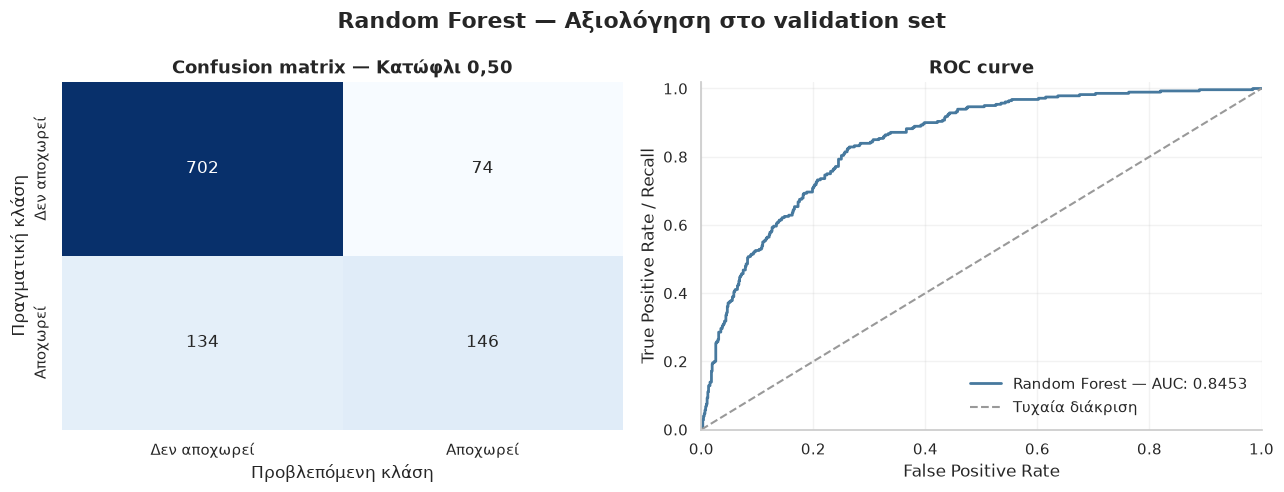

In [29]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve

# 1. Δημιουργία μοντέλου
rf_model = RandomForestClassifier(
    n_estimators=300,  # Το Random Forest συνδυάζει 300 δέντρα.
    max_depth=8,  # Περιορίζουμε το βάθος των δέντρων.
    min_samples_leaf=5,  # Κάθε τελικό φύλλο πρέπει να περιέχει τουλάχιστον 5 πελάτες.
    max_features="sqrt",  # Κάθε διαχωρισμός εξετάζει μόνο ένα μέρος των χαρακτηριστικών.
    bootstrap=True,  # Κάθε δέντρο εκπαιδεύεται σε τυχαίο δείγμα με επαναλήψεις.
    class_weight=None,  # Δεν δίνουμε επιπλέον βάρος σε κάποια κλάση.
    random_state=42,  # Σταθερή αρχική τιμή για να επαναλαμβάνεται το πείραμα.
    n_jobs=-1  # Χρησιμοποιούμε όλους τους διαθέσιμους πυρήνες.
)

# 2. Εκπαίδευση μόνο στο training set
print("Εκπαίδευση Random Forest...", flush=True)

rf_model.fit(
    X_train_nn,
    np.asarray(y_train_nn).ravel()
)

print("Η εκπαίδευση ολοκληρώθηκε.")

# Εντοπισμός της στήλης που αντιστοιχεί στην κλάση Churn = 1
rf_positive_class_index = int(
    np.flatnonzero(rf_model.classes_ == 1)[0]
)

# 3. Πιθανότητες και προβλέψεις
rf_train_probabilities = rf_model.predict_proba(
    X_train_nn
)[:, rf_positive_class_index]

rf_val_probabilities = rf_model.predict_proba(
    X_val_nn
)[:, rf_positive_class_index]

rf_train_predictions = (
    rf_train_probabilities >= 0.50
).astype(int)  # Το False γίνεται 0 και το True γίνεται 1.

rf_val_predictions = (
    rf_val_probabilities >= 0.50
).astype(int)

# 4. Σύγκριση training και validation επιδόσεων
rf_split_rows = []

for split_name, targets, probabilities, predictions in [
    (
        "Training",
        np.asarray(y_train_nn).ravel(),
        rf_train_probabilities,
        rf_train_predictions
    ),
    (
        "Validation",
        np.asarray(y_val).ravel(),
        rf_val_probabilities,
        rf_val_predictions
    )
]:
    rf_split_rows.append(
        {
            "Dataset": split_name,
            "Accuracy": accuracy_score(targets, predictions),
            "Precision": precision_score(
                targets, predictions, zero_division=0
            ),
            "Recall": recall_score(
                targets, predictions, zero_division=0
            ),
            "F1-score": f1_score(
                targets, predictions, zero_division=0
            ),
            "ROC-AUC": roc_auc_score(targets, probabilities)
        }
    )

rf_split_comparison_df = pd.DataFrame(
    rf_split_rows
).set_index("Dataset")

print("\nRandom Forest — Training και validation, κατώφλι 0,50")
display(rf_split_comparison_df.round(4))

# 5. Προσθήκη στον συνολικό συγκριτικό πίνακα
rf_results = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_val, rf_val_predictions),
    "Precision": precision_score(
        y_val, rf_val_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_val, rf_val_predictions, zero_division=0
    ),
    "F1-score": f1_score(
        y_val, rf_val_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_val, rf_val_probabilities)
}

comparison_df = pd.DataFrame(
    [
        baseline_results,
        mlp_results,
        dropout_results,
        l2_results,
        l1_results,
        bn_results,
        residual_results,
        tuned_results,
        rf_results
    ]
).set_index("Model")

print("\nΣύγκριση στο validation set — κατώφλι 0,50")
display(comparison_df.round(4))

# 6. Confusion matrix
rf_cm = confusion_matrix(
    y_val,
    rf_val_predictions,
    labels=[0, 1]  # Σειρά κλάσεων: παραμονή πρώτα, αποχώρηση μετά.
)

rf_tn, rf_fp, rf_fn, rf_tp = rf_cm.ravel()

print("\nΑνάλυση confusion matrix:")
print(f"TN — Σωστή πρόβλεψη μη αποχώρησης: {rf_tn}")
print(f"FP — Λανθασμένος συναγερμός αποχώρησης: {rf_fp}")
print(f"FN — Αποχώρηση που δεν αναγνωρίστηκε: {rf_fn}")
print(f"TP — Σωστή πρόβλεψη αποχώρησης: {rf_tp}")

# 7. Confusion matrix και ROC curve
rf_fpr, rf_tpr, _ = roc_curve(
    y_val,
    rf_val_probabilities
)

fig, axes = plt.subplots(ncols=2, figsize=(13, 5))

sns.heatmap(
    rf_cm,
    annot=True,  # Γράφουμε την τιμή μέσα σε κάθε τετράγωνο.
    fmt="d",  # Εμφανίζουμε ακέραιους αριθμούς πελατών.
    cmap="Blues",
    cbar=False,
    xticklabels=["Δεν αποχωρεί", "Αποχωρεί"],
    yticklabels=["Δεν αποχωρεί", "Αποχωρεί"],
    ax=axes[0]
)

axes[0].set_title(
    "Confusion matrix — Κατώφλι 0,50",
    fontsize=13,
    fontweight="bold"
)
axes[0].set_xlabel("Προβλεπόμενη κλάση")
axes[0].set_ylabel("Πραγματική κλάση")

axes[1].plot(
    rf_fpr,
    rf_tpr,
    color="#47799E",
    linewidth=2,
    label=f"Random Forest — AUC: {rf_results['ROC-AUC']:.4f}"
)

axes[1].plot(
    [0, 1],
    [0, 1],
    color="#999999",
    linestyle="--",
    linewidth=1.5,
    label="Τυχαία διάκριση"
)

axes[1].set_title(
    "ROC curve",
    fontsize=13,
    fontweight="bold"
)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate / Recall")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1.02)
axes[1].grid(alpha=0.25)
axes[1].legend(frameon=False, loc="lower right")
sns.despine(ax=axes[1])

fig.suptitle(
    "Random Forest — Αξιολόγηση στο validation set",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout()

plt.show()  # Εμφανίζουμε το γράφημα μέσα στο notebook.


#### Αξιολόγηση του Random Forest

Το Random Forest πέτυχε στο validation set accuracy 80,30%, precision 66,36%, recall 52,14%, F1-score 58,40% και ROC-AUC 0,8453, με κατώφλι ταξινόμησης 0,50.

Σε σύγκριση με τη Logistic Regression, παρουσίασε υψηλότερη precision (66,36% έναντι 64,59%), αλλά χαμηλότερο recall (52,14% έναντι 59,29%) και F1-score (58,40% έναντι 61,82%). Επομένως, οι προβλέψεις αποχώρησης ήταν αναλογικά πιο αξιόπιστες, αλλά αναγνωρίστηκε μικρότερο ποσοστό πραγματικών αποχωρήσεων.

Η ROC-AUC ήταν ίδια με εκείνη της Logistic Regression στα τέσσερα εμφανιζόμενα δεκαδικά ψηφία (0,8453). Αυτό δείχνει παρόμοια συνολική ικανότητα διάκρισης, χωρίς να συνεπάγεται ίδιες αποφάσεις στο κατώφλι 0,50.

Σε σύγκριση με το MLP με Optuna, το Random Forest είχε υψηλότερη precision, αλλά χαμηλότερη accuracy, recall, F1-score και ROC-AUC. Το MLP με Optuna παραμένει το μοντέλο με το υψηλότερο validation F1-score στον συγκριτικό πίνακα στο κοινό κατώφλι 0,50.

#### Ανάλυση του confusion matrix

Στους 1.056 πελάτες του validation set καταγράφηκαν:

- 702 true negatives: σωστή αναγνώριση μη αποχώρησης.
- 74 false positives: λανθασμένη πρόβλεψη αποχώρησης.
- 134 false negatives: πραγματικές αποχωρήσεις που δεν αναγνωρίστηκαν.
- 146 true positives: σωστή αναγνώριση αποχώρησης.

Το μοντέλο εντόπισε 146 από τις 280 πραγματικές αποχωρήσεις, δηλαδή το 52,14%, ενώ δεν αναγνώρισε το υπόλοιπο 47,86%.

Από τους 220 πελάτες που χαρακτηρίστηκαν ως πιθανές αποχωρήσεις, οι 146 αποχώρησαν πραγματικά και οι 74 δεν αποχώρησαν. Αυτό εξηγεί την precision 66,36%.

Από επιχειρηματική άποψη, τα false negatives αντιπροσωπεύουν πελάτες που δεν θα επιλέγονταν για παρέμβαση βάσει αυτής της πρόβλεψης, παρότι αποχωρούν. Τα false positives θα μπορούσαν να οδηγήσουν σε περιττές επικοινωνίες ή προσφορές. Η σχετική σημασία αυτών των σφαλμάτων εξαρτάται από το κόστος της παρέμβασης και της απώλειας πελατών.

#### Training και validation επιδόσεις

Η training accuracy ήταν 83,20%, έναντι 80,30% στο validation set. Το training F1-score ήταν 64,28%, έναντι 58,40%, ενώ η ROC-AUC μειώθηκε από 0,8971 στο training σε 0,8453 στο validation.

Το μοντέλο αποδίδει καλύτερα στα δεδομένα από τα οποία έμαθε παρά στο validation. Η διαφορά αυτή είναι ένδειξη κάποιας υπερπροσαρμογής. Οι περιορισμοί στο βάθος των δέντρων και στο ελάχιστο μέγεθος φύλλου δεν εξάλειψαν την απόσταση μεταξύ training και validation επιδόσεων.

Η ROC curve βρίσκεται πάνω από τη διαγώνιο τυχαίας διάκρισης και η AUC 0,8453 δείχνει ικανότητα διάκρισης μεταξύ των δύο κλάσεων. Ωστόσο, η ROC-AUC δεν είναι ποσοστό σωστών ταξινομήσεων και δεν περιγράφει μόνη της την αποτελεσματικότητα στο συγκεκριμένο κατώφλι.

Συνολικά, το Random Forest δεν ξεπέρασε τη Logistic Regression ή το MLP με Optuna ως προς τον εντοπισμό αποχωρήσεων και το F1-score στο κατώφλι 0,50. Το συμπέρασμα αφορά τη συγκεκριμένη προκαθορισμένη ρύθμιση. Καθώς δεν έγινε tuning για το Random Forest, δεν αποδεικνύει γενική υπεροχή του νευρωνικού δικτύου έναντι του αλγορίθμου.


### 17. Σύγκριση με XGBoost

Προσθέτουμε το XGBoost ως δεύτερο επιπλέον μοντέλο μηχανικής μάθησης, σύμφωνα με την απαίτηση της εκφώνησης για benchmarking.

Το XGBoost χρησιμοποιεί gradient boosting με δέντρα αποφάσεων. Τα δέντρα δημιουργούνται διαδοχικά, με κάθε νέο δέντρο να συμβάλλει στη μείωση της συνάρτησης απώλειας του συνδυασμένου μοντέλου.

Χρησιμοποιούμε τις ακόλουθες προκαθορισμένες ρυθμίσεις:

| Παράμετρος | Τιμή | Σκοπός |
|---|---|---|
| n_estimators | 500 | Μέγιστος αριθμός boosting rounds |
| max_depth | 3 | Περιορισμός πολυπλοκότητας κάθε δέντρου |
| learning_rate | 0,05 | Περιορισμός της συνεισφοράς κάθε νέου δέντρου |
| subsample | 0,80 | Δειγματοληψία γραμμών κατά την εκπαίδευση |
| colsample_bytree | 0,80 | Δειγματοληψία χαρακτηριστικών ανά δέντρο |
| reg_lambda | 1,00 | L2 regularisation στα βάρη των φύλλων |
| early_stopping_rounds | 20 | Διακοπή μετά από 20 γύρους χωρίς βελτίωση |
| random_state | 42 | Αναπαραγωγιμότητα |

Οι ρυθμίσεις αποτελούν αρχική πειραματική επιλογή και δεν είναι αποτέλεσμα αναζήτησης υπερπαραμέτρων.

Χρησιμοποιούμε τα ίδια προεπεξεργασμένα δεδομένα και τον ίδιο διαχωρισμό training/validation. Το XGBoost δεν απαιτεί standardization, αλλά μπορεί να χρησιμοποιήσει τις ήδη μετασχηματισμένες εισόδους.

Η εκπαίδευση ελαχιστοποιεί το binary logistic loss. Το early stopping παρακολουθεί το validation log loss και επιλέγει τον αριθμό boosting rounds. Οι προβλέψεις υπολογίζονται χρησιμοποιώντας τους γύρους έως και την καλύτερη επανάληψη.

Εμφανίζουμε τις πέντε καλύτερες επαναλήψεις βάσει validation log loss, καθώς και τις καμπύλες log loss και AUC για training και validation.

Η αξιολόγηση περιλαμβάνει accuracy, precision, recall, F1-score, ROC-AUC και confusion matrix. Το κατώφλι ταξινόμησης παραμένει 0,50.

Δεν κάνουμε πλήρες hyperparameter tuning για το XGBoost. Ωστόσο, το validation set χρησιμοποιείται για την επιλογή του αριθμού boosting rounds μέσω early stopping. Το test set δεν συμμετέχει σε αυτή τη διαδικασία.


Έκδοση XGBoost: 3.4.1

Εκπαίδευση XGBoost...
Η εκπαίδευση ολοκληρώθηκε.

Boosting rounds που εκτελέστηκαν: 155
Καλύτερο boosting round: 135
Καλύτερο validation log loss: 0.41056

Πέντε καλύτερες επαναλήψεις:


,Round,Train log loss,Validation log loss,Train AUC,Validation AUC
0,135,0.38431,0.41056,0.87207,0.85144
1,136,0.38419,0.41064,0.87212,0.85138
2,134,0.38447,0.41065,0.87198,0.85143
3,132,0.38493,0.41068,0.87177,0.85150
4,137,0.38401,0.41069,0.87224,0.85129



XGBoost — Training και validation, κατώφλι 0,50


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Dataset,,,,,
Training,0.8211,0.7002,0.5696,0.6282,0.8721
Validation,0.8011,0.6522,0.5357,0.5882,0.8514



Σύγκριση στο validation set — κατώφλι 0,50


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.8059,0.6459,0.5929,0.6182,0.8453
Initial MLP,0.8040,0.6652,0.5250,0.5868,0.8456
MLP + Dropout,0.8059,0.6682,0.5321,0.5924,0.8460
MLP + L2,0.8097,0.6946,0.5036,0.5839,0.8450
MLP + L1,0.7992,0.6619,0.4964,0.5673,0.8473
MLP + Batch Normalization,0.7850,0.5985,0.5750,0.5865,0.8360
MLP + Residual Connection,0.8030,0.6651,0.5179,0.5823,0.8440
MLP + Optuna,0.8078,0.6453,0.6107,0.6275,0.8482
Random Forest,0.8030,0.6636,0.5214,0.5840,0.8453


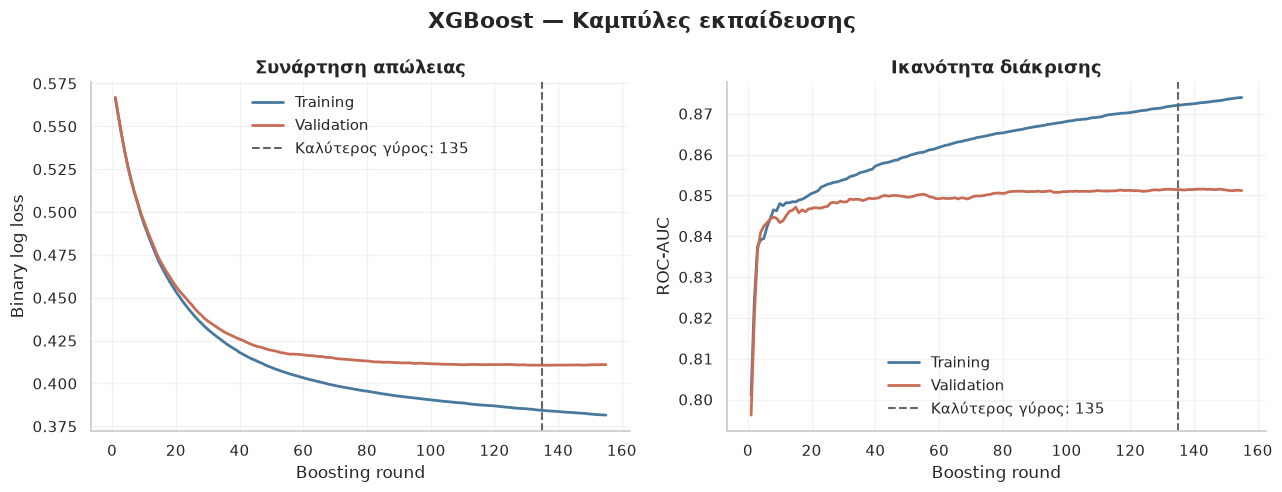


Ανάλυση confusion matrix:
TN — Σωστή πρόβλεψη μη αποχώρησης: 696
FP — Λανθασμένος συναγερμός αποχώρησης: 80
FN — Αποχώρηση που δεν αναγνωρίστηκε: 130
TP — Σωστή πρόβλεψη αποχώρησης: 150


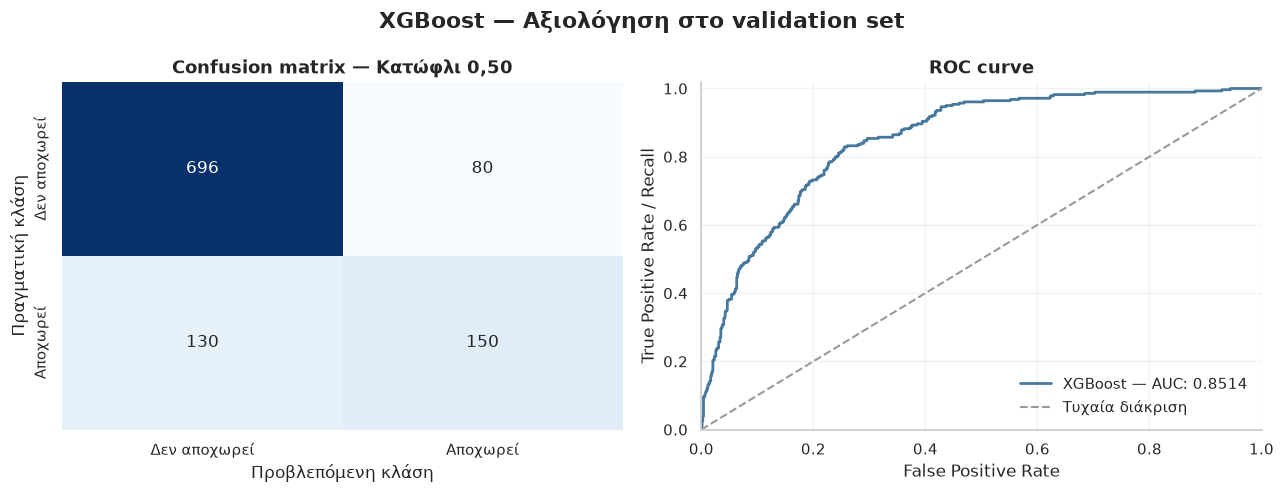

In [30]:
import xgboost as xgb
from sklearn.metrics import confusion_matrix, roc_curve

print("Έκδοση XGBoost:", xgb.__version__)

# 1. Δημιουργία μοντέλου
xgb_model = xgb.XGBClassifier(
    objective="binary:logistic",  # Ζητάμε πιθανότητα για δυαδική ταξινόμηση.
    n_estimators=500,  # Μέχρι 500 γύροι, αν δεν σταματήσουμε νωρίτερα.
    max_depth=3,  # Μικρό βάθος για να περιορίσουμε την πολυπλοκότητα.
    learning_rate=0.05,  # Κάθε νέο δέντρο αλλάζει λίγο την πρόβλεψη.
    subsample=0.80,  # Κάθε γύρος χρησιμοποιεί τυχαία το 80% των παρατηρήσεων.
    colsample_bytree=0.80,  # Κάθε δέντρο χρησιμοποιεί το 80% των χαρακτηριστικών.
    reg_lambda=1.0,  # Ποινή L2 στα βάρη των φύλλων.
    reg_alpha=0.0,  # Δεν εφαρμόζουμε ποινή L1.
    min_child_weight=1,
    scale_pos_weight=1,  # Δεν αυξάνουμε το βάρος της κλάσης αποχώρησης.
    tree_method="hist",
    eval_metric=["auc", "logloss"],  # Το τελευταίο μέτρο, logloss, καθορίζει το early stopping.
    early_stopping_rounds=20,  # Σταματάμε μετά από 20 γύρους χωρίς βελτίωση.
    random_state=42,  # Σταθερή αρχική τιμή για να επαναλαμβάνεται το πείραμα.
    n_jobs=4
)

# 2. Εκπαίδευση
# Το validation set τοποθετείται τελευταίο,
# ώστε να χρησιμοποιηθεί για το early stopping.
print("\nΕκπαίδευση XGBoost...", flush=True)

xgb_model.fit(
    X_train_nn,
    np.asarray(y_train_nn).ravel(),
    eval_set=[
        (X_train_nn, np.asarray(y_train_nn).ravel()),
        (X_val_nn, np.asarray(y_val).ravel())
    ],
    verbose=False
)

print("Η εκπαίδευση ολοκληρώθηκε.")

# 3. Ιστορικό εκπαίδευσης
xgb_evaluation_history = xgb_model.evals_result()

xgb_rounds_run = len(
    xgb_evaluation_history["validation_1"]["logloss"]
)

# Το best_iteration ξεκινά από το 0.
# Για παρουσίαση στον χρήστη προσθέτουμε 1.
xgb_best_round = int(xgb_model.best_iteration + 1)

xgb_history_df = pd.DataFrame(
    {
        "Round": np.arange(1, xgb_rounds_run + 1),
        "Train log loss":
            xgb_evaluation_history["validation_0"]["logloss"],
        "Validation log loss":
            xgb_evaluation_history["validation_1"]["logloss"],
        "Train AUC":
            xgb_evaluation_history["validation_0"]["auc"],
        "Validation AUC":
            xgb_evaluation_history["validation_1"]["auc"]
    }
)

xgb_top_rounds_df = (
    xgb_history_df
    .sort_values(
        by=["Validation log loss", "Round"],
        ascending=[True, True]
    )
    .head(5)  # Κρατάμε τις πέντε πρώτες γραμμές.
    .reset_index(drop=True)  # Βάζουμε νέα αρίθμηση γραμμών, χωρίς την παλιά.
)

print("\nBoosting rounds που εκτελέστηκαν:", xgb_rounds_run)
print("Καλύτερο boosting round:", xgb_best_round)
print(
    "Καλύτερο validation log loss:",
    round(float(xgb_model.best_score), 5)
)

print("\nΠέντε καλύτερες επαναλήψεις:")
display(xgb_top_rounds_df.round(5))

# 4. Προβλέψεις μέχρι και την καλύτερη επανάληψη
# Το πάνω όριο του iteration_range δεν περιλαμβάνεται.
xgb_iteration_range = (0, xgb_best_round)

xgb_positive_class_index = int(
    np.flatnonzero(xgb_model.classes_ == 1)[0]
)

xgb_train_probabilities = xgb_model.predict_proba(
    X_train_nn,
    iteration_range=xgb_iteration_range
)[:, xgb_positive_class_index]

xgb_val_probabilities = xgb_model.predict_proba(
    X_val_nn,
    iteration_range=xgb_iteration_range
)[:, xgb_positive_class_index]

xgb_train_predictions = (
    xgb_train_probabilities >= 0.50
).astype(int)  # Το False γίνεται 0 και το True γίνεται 1.

xgb_val_predictions = (
    xgb_val_probabilities >= 0.50
).astype(int)

# 5. Training και validation επιδόσεις
xgb_split_rows = []

for split_name, targets, probabilities, predictions in [
    (
        "Training",
        np.asarray(y_train_nn).ravel(),
        xgb_train_probabilities,
        xgb_train_predictions
    ),
    (
        "Validation",
        np.asarray(y_val).ravel(),
        xgb_val_probabilities,
        xgb_val_predictions
    )
]:
    xgb_split_rows.append(
        {
            "Dataset": split_name,
            "Accuracy": accuracy_score(targets, predictions),
            "Precision": precision_score(
                targets, predictions, zero_division=0
            ),
            "Recall": recall_score(
                targets, predictions, zero_division=0
            ),
            "F1-score": f1_score(
                targets, predictions, zero_division=0
            ),
            "ROC-AUC": roc_auc_score(targets, probabilities)
        }
    )

xgb_split_comparison_df = pd.DataFrame(
    xgb_split_rows
).set_index("Dataset")

print("\nXGBoost — Training και validation, κατώφλι 0,50")
display(xgb_split_comparison_df.round(4))

# 6. Συνολικός συγκριτικός πίνακας
xgb_results = {
    "Model": "XGBoost",
    "Accuracy": accuracy_score(y_val, xgb_val_predictions),
    "Precision": precision_score(
        y_val, xgb_val_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_val, xgb_val_predictions, zero_division=0
    ),
    "F1-score": f1_score(
        y_val, xgb_val_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_val, xgb_val_probabilities)
}

comparison_df = pd.DataFrame(
    [
        baseline_results,
        mlp_results,
        dropout_results,
        l2_results,
        l1_results,
        bn_results,
        residual_results,
        tuned_results,
        rf_results,
        xgb_results
    ]
).set_index("Model")

print("\nΣύγκριση στο validation set — κατώφλι 0,50")
display(comparison_df.round(4))

# 7. Καμπύλες εκπαίδευσης
fig, axes = plt.subplots(ncols=2, figsize=(13, 5))

xgb_plot_settings = [
    (
        "Train log loss",
        "Validation log loss",
        "Συνάρτηση απώλειας",
        "Binary log loss"
    ),
    (
        "Train AUC",
        "Validation AUC",
        "Ικανότητα διάκρισης",
        "ROC-AUC"
    )
]

for ax, (train_metric, val_metric, title, ylabel) in zip(
    axes, xgb_plot_settings
):
    sns.lineplot(
        data=xgb_history_df,
        x="Round",
        y=train_metric,
        label="Training",
        color="#47799E",
        linewidth=2,
        ax=ax
    )

    sns.lineplot(
        data=xgb_history_df,
        x="Round",
        y=val_metric,
        label="Validation",
        color="#C76D55",
        linewidth=2,
        ax=ax
    )

    ax.axvline(
        xgb_best_round,
        color="#666666",
        linestyle="--",
        linewidth=1.5,
        label=f"Καλύτερος γύρος: {xgb_best_round}"
    )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Boosting round")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    ax.legend(frameon=False)
    sns.despine(ax=ax)

fig.suptitle(
    "XGBoost — Καμπύλες εκπαίδευσης",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout()

plt.show()  # Εμφανίζουμε το γράφημα μέσα στο notebook.

# 8. Confusion matrix
xgb_cm = confusion_matrix(
    y_val,
    xgb_val_predictions,
    labels=[0, 1]  # Σειρά κλάσεων: παραμονή πρώτα, αποχώρηση μετά.
)

xgb_tn, xgb_fp, xgb_fn, xgb_tp = xgb_cm.ravel()

print("\nΑνάλυση confusion matrix:")
print(f"TN — Σωστή πρόβλεψη μη αποχώρησης: {xgb_tn}")
print(f"FP — Λανθασμένος συναγερμός αποχώρησης: {xgb_fp}")
print(f"FN — Αποχώρηση που δεν αναγνωρίστηκε: {xgb_fn}")
print(f"TP — Σωστή πρόβλεψη αποχώρησης: {xgb_tp}")

# 9. Confusion matrix και ROC curve
xgb_fpr, xgb_tpr, _ = roc_curve(
    y_val,
    xgb_val_probabilities
)

fig, axes = plt.subplots(ncols=2, figsize=(13, 5))

sns.heatmap(
    xgb_cm,
    annot=True,  # Γράφουμε την τιμή μέσα σε κάθε τετράγωνο.
    fmt="d",  # Εμφανίζουμε ακέραιους αριθμούς πελατών.
    cmap="Blues",
    cbar=False,
    xticklabels=["Δεν αποχωρεί", "Αποχωρεί"],
    yticklabels=["Δεν αποχωρεί", "Αποχωρεί"],
    ax=axes[0]
)

axes[0].set_title(
    "Confusion matrix — Κατώφλι 0,50",
    fontsize=13,
    fontweight="bold"
)
axes[0].set_xlabel("Προβλεπόμενη κλάση")
axes[0].set_ylabel("Πραγματική κλάση")

axes[1].plot(
    xgb_fpr,
    xgb_tpr,
    color="#47799E",
    linewidth=2,
    label=f"XGBoost — AUC: {xgb_results['ROC-AUC']:.4f}"
)

axes[1].plot(
    [0, 1],
    [0, 1],
    color="#999999",
    linestyle="--",
    linewidth=1.5,
    label="Τυχαία διάκριση"
)

axes[1].set_title(
    "ROC curve",
    fontsize=13,
    fontweight="bold"
)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate / Recall")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1.02)
axes[1].grid(alpha=0.25)
axes[1].legend(frameon=False, loc="lower right")
sns.despine(ax=axes[1])

fig.suptitle(
    "XGBoost — Αξιολόγηση στο validation set",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout()

plt.show()


#### Αξιολόγηση του XGBoost

Το XGBoost πέτυχε στο validation set accuracy 80,11%, precision 65,22%, recall 53,57%, F1-score 58,82% και ROC-AUC 0,8514, με κατώφλι ταξινόμησης 0,50.

Η ROC-AUC ήταν η υψηλότερη μεταξύ των μοντέλων του συγκριτικού πίνακα. Ωστόσο, η διαφορά από το MLP με Optuna (0,8482) ήταν μικρή, ίση με 0,0032, και δεν αποδεικνύει από μόνη της σταθερή υπεροχή σε νέα δεδομένα.

Παρά την υψηλότερη ROC-AUC, το XGBoost είχε χαμηλότερο recall και F1-score από το MLP με Optuna: 53,57% έναντι 61,07% και 58,82% έναντι 62,75%, αντίστοιχα. Η precision ήταν ελαφρώς υψηλότερη (65,22% έναντι 64,53%).

Η διαφορά αυτή εξηγείται από το ότι η ROC-AUC αξιολογεί την ικανότητα κατάταξης των πελατών ως προς τον κίνδυνο αποχώρησης σε διαφορετικά κατώφλια. Αντίθετα, το recall, η precision και το F1-score εξαρτώνται από το συγκεκριμένο όριο ταξινόμησης. Επομένως, υψηλότερη ROC-AUC δεν σημαίνει υψηλότερο F1-score στο κατώφλι 0,50.

Σε σύγκριση με το Random Forest, το XGBoost παρουσίασε υψηλότερο recall, F1-score και ROC-AUC, αλλά ελαφρώς χαμηλότερη accuracy και precision. Σε σύγκριση με τη Logistic Regression, είχε υψηλότερη ROC-AUC και precision, αλλά χαμηλότερο recall και F1-score.

#### Εκπαίδευση και early stopping

Η εκπαίδευση ολοκληρώθηκε μετά από 155 boosting rounds. Η καλύτερη επανάληψη ήταν η 135η, με validation log loss 0,41056.

Ακολούθησαν 20 γύροι χωρίς βελτίωση του validation log loss, οπότε ενεργοποιήθηκε το early stopping. Οι τελικές προβλέψεις υπολογίστηκαν χρησιμοποιώντας τους γύρους έως και την 135η επανάληψη.

Η επιλογή έγινε με βάση το validation log loss και όχι τη validation AUC. Για παράδειγμα, ο γύρος 132 είχε ελαφρώς υψηλότερη validation AUC από τον 135, αλλά υψηλότερο validation log loss.

Οι καμπύλες δείχνουν γρήγορη αρχική βελτίωση και στη συνέχεια σταθεροποίηση των validation μετρικών. Το training loss συνεχίζει να μειώνεται και η training AUC να αυξάνεται, ενώ η validation AUC παραμένει περίπου στο 0,851.

Στην επιλεγμένη επανάληψη, η training accuracy ήταν 82,11%, έναντι 80,11% στο validation set. Το training F1-score ήταν 62,82%, έναντι 58,82%, ενώ η ROC-AUC ήταν 0,8721 έναντι 0,8514.

Η απόσταση μεταξύ training και validation επιδόσεων αποτελεί ένδειξη κάποιας υπερπροσαρμογής, χωρίς έντονη επιδείνωση των validation μετρικών. Το early stopping περιόρισε την περαιτέρω προσθήκη δέντρων όταν το κριτήριο επιλογής έπαψε να βελτιώνεται.

#### Ανάλυση του confusion matrix

Στους 1.056 πελάτες του validation set καταγράφηκαν:

- 696 true negatives: σωστή πρόβλεψη μη αποχώρησης.
- 80 false positives: λανθασμένη πρόβλεψη αποχώρησης.
- 130 false negatives: αποχωρήσεις που δεν αναγνωρίστηκαν.
- 150 true positives: σωστή πρόβλεψη αποχώρησης.

Το μοντέλο εντόπισε 150 από τις 280 πραγματικές αποχωρήσεις, δηλαδή το 53,57%, ενώ δεν αναγνώρισε τις υπόλοιπες 130.

Από τους 230 πελάτες που χαρακτηρίστηκαν ως πιθανές αποχωρήσεις, οι 150 αποχώρησαν πραγματικά και οι 80 δεν αποχώρησαν. Αυτό αντιστοιχεί σε precision 65,22%.

Σε σχέση με το Random Forest, το XGBoost εντόπισε τέσσερις επιπλέον πραγματικές αποχωρήσεις, αλλά παρήγαγε έξι επιπλέον λανθασμένους συναγερμούς. Η επιχειρηματική αξία αυτής της διαφοράς εξαρτάται από το κόστος των παρεμβάσεων διατήρησης και της απώλειας πελατών.

Συνολικά, το XGBoost παρουσίασε την υψηλότερη validation ROC-AUC, ενώ το MLP με Optuna διατήρησε το υψηλότερο recall και F1-score στο κατώφλι 0,50. Τα συμπεράσματα αφορούν τις συγκεκριμένες ρυθμίσεις και δεν αποτελούν ακόμη τελική αξιολόγηση στο test set.

Επιπλέον, το MLP με Optuna έχει υποστεί αναζήτηση υπερπαραμέτρων, ενώ στο XGBoost χρησιμοποιήθηκαν προκαθορισμένες ρυθμίσεις και επιλογή του αριθμού boosting rounds μέσω early stopping. Η διαφορά αυτή περιορίζει τα γενικά συμπεράσματα για την υπεροχή του ενός αλγορίθμου έναντι του άλλου.


### 18. Ερμηνεία του νευρωνικού δικτύου με SHAP

Χρησιμοποιούμε SHAP για να ερμηνεύσουμε τις προβλέψεις του MLP που επιλέχθηκε από το Optuna: με τις ρυθμίσεις που παρουσιάστηκαν στην προηγούμενη ενότητα.

Οι τιμές SHAP κατανέμουν τη διαφορά μεταξύ μιας τιμής αναφοράς και της πρόβλεψης ενός πελάτη στα χαρακτηριστικά εισόδου του μοντέλου.

Εξηγούμε την προβλεπόμενη πιθανότητα αποχώρησης:

- Θετική τιμή SHAP: συμβολή προς υψηλότερη πιθανότητα αποχώρησης σε σχέση με την τιμή αναφοράς.
- Αρνητική τιμή SHAP: συμβολή προς χαμηλότερη πιθανότητα.
- Μεγαλύτερη απόλυτη τιμή: μεγαλύτερη συμβολή στη συγκεκριμένη πρόβλεψη.

Χρησιμοποιούμε τον PermutationExplainer, με 50 τυχαίες παρατηρήσεις από το training set ως δεδομένα αναφοράς και 100 τυχαίες παρατηρήσεις από το validation set για ερμηνεία. Η δειγματοληψία γίνεται με seed 42.

Τα μεγέθη των δειγμάτων περιορίζουν το υπολογιστικό κόστος. Η ανάλυση είναι προσεγγιστική και αφορά το συγκεκριμένο δείγμα, όχι όλους τους πελάτες.

Παρουσιάζουμε:

1. Κατάταξη χαρακτηριστικών με βάση τη μέση απόλυτη
τιμή SHAP στο δείγμα.
2. Beeswarm plot για την κατεύθυνση και τη διασπορά
των επιδράσεων.
3. Waterfall plot για την πρώτη παρατήρηση του
τυχαίου δείγματος, χωρίς επιλογή βάσει αποτελέσματος.

Χρησιμοποιούμε τα χαρακτηριστικά μετά την προεπεξεργασία. Επομένως, οι κατηγορικές μεταβλητές εμφανίζονται μέσω των στηλών που προέκυψαν από το one-hot encoding, ενώ οι αριθμητικές τιμές εμφανίζονται στην κλιμακωμένη μορφή τους.

Η μέση απόλυτη τιμή SHAP δείχνει το μέγεθος της επίδρασης, όχι αν ένα χαρακτηριστικό αυξάνει ή μειώνει πάντοτε τον κίνδυνο.

Οι εξηγήσεις περιγράφουν τη συμπεριφορά του μοντέλου και δεν αποδεικνύουν αιτιώδεις σχέσεις. Επιπλέον, η ανεξάρτητη απόκρυψη χαρακτηριστικών μπορεί να δημιουργήσει μη ρεαλιστικούς συνδυασμούς, ιδίως μεταξύ συσχετισμένων μεταβλητών ή στηλών one-hot. Αυτό αποτελεί περιορισμό της συγκεκριμένης εφαρμογής.


Έκδοση SHAP: 0.54.1
Παρατηρήσεις αναφοράς: 50
Παρατηρήσεις προς ερμηνεία: 100
Αριθμός χαρακτηριστικών: 46

Υπολογισμός τιμών SHAP...
Ο υπολογισμός ολοκληρώθηκε.

15 σημαντικότερα χαρακτηριστικά στο δείγμα:


,Feature,Mean absolute SHAP
0,numeric__tenure,0.09000
1,categorical__Contract_Two year,0.04148
2,numeric__MonthlyCharges,0.02975
3,categorical__Contract_Month-to-month,0.02524
4,categorical__PaperlessBilling_Yes,0.01928
5,categorical__InternetService_Fiber optic,0.01917
6,categorical__DeviceProtection_No,0.01770
7,categorical__StreamingMovies_No,0.01718
8,categorical__InternetService_DSL,0.01692
9,categorical__Dependents_Yes,0.01677



Μέγιστο σφάλμα ανασύνθεσης πιθανότητας: 0.00000000


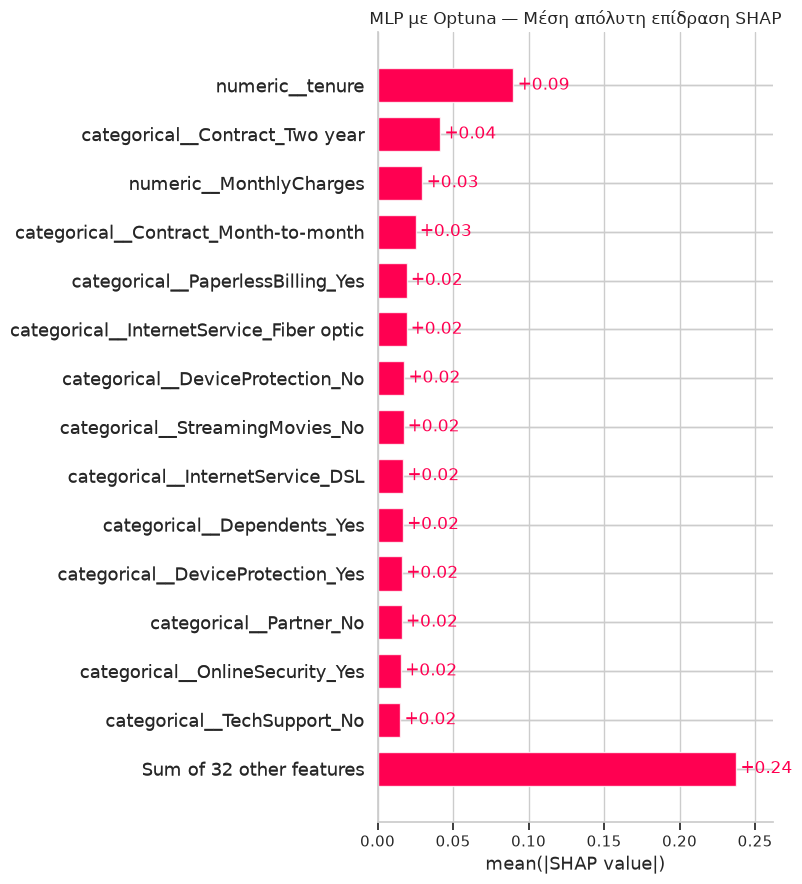

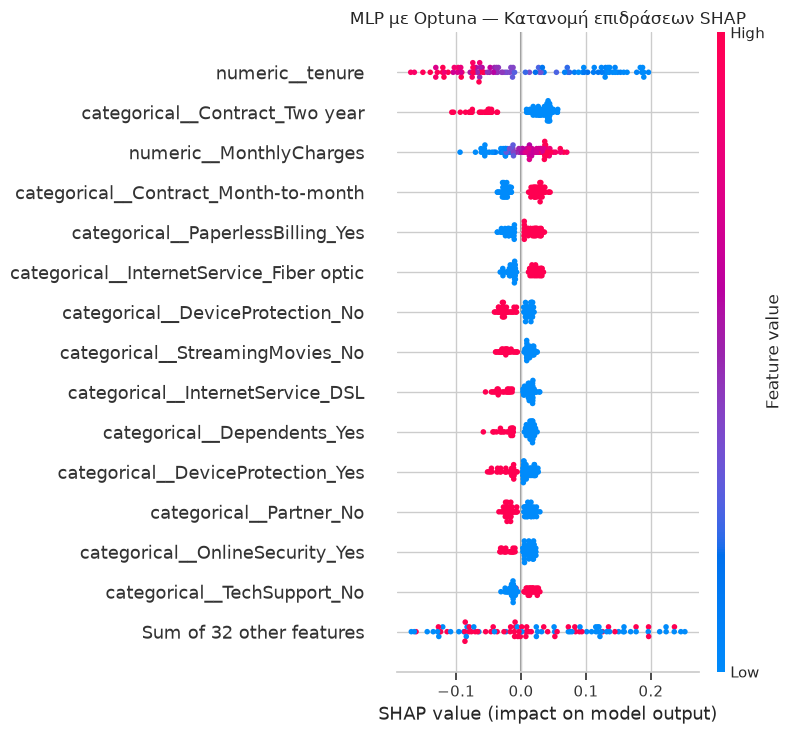


Τοπική ερμηνεία:
Θέση στο validation set, με αρίθμηση από το 0: 794
Πραγματική κλάση: 1
Προβλεπόμενη πιθανότητα αποχώρησης: 0.6958
Προβλεπόμενη κλάση στο κατώφλι 0,50: 1


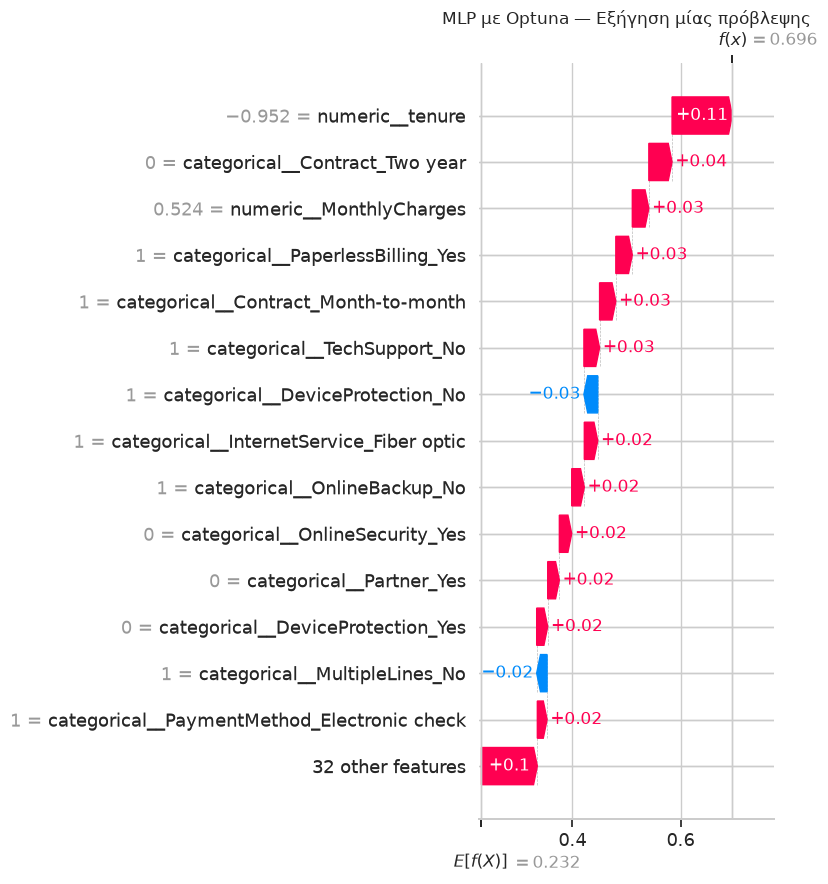

In [ ]:
import shap

print("Έκδοση SHAP:", shap.__version__)

# Ονόματα με την ίδια σειρά που παράγει ο preprocessor
shap_feature_names = [
    str(name)
    for name in preprocessor.get_feature_names_out()
]

# Οι πίνακες αυτοί είναι οι ίδιοι που χρησιμοποιήθηκαν στα MLP.
shap_train_array = np.asarray(X_train_nn, dtype=np.float32)
shap_val_array = np.asarray(X_val_nn, dtype=np.float32)

if len(shap_feature_names) != shap_train_array.shape[1]:
    raise ValueError(
        "Τα ονόματα χαρακτηριστικών δεν αντιστοιχούν "
        "στον αριθμό εισόδων του μοντέλου."
    )

# 2. Δειγματοληψία χωρίς επανάθεση
shap_rng = np.random.default_rng(42)

shap_background_indices = shap_rng.choice(
    shap_train_array.shape[0],
    size=min(50, shap_train_array.shape[0]),
    replace=False  # Δεν επιλέγουμε τον ίδιο πελάτη δύο φορές στο δείγμα.
)

shap_validation_indices = shap_rng.choice(
    shap_val_array.shape[0],
    size=min(100, shap_val_array.shape[0]),
    replace=False
)

shap_background = shap_train_array[shap_background_indices]
shap_explain_data = shap_val_array[shap_validation_indices]

print("Παρατηρήσεις αναφοράς:", len(shap_background))
print("Παρατηρήσεις προς ερμηνεία:", len(shap_explain_data))
print("Αριθμός χαρακτηριστικών:", len(shap_feature_names))

# 3. Συνάρτηση πρόβλεψης του ήδη εκπαιδευμένου MLP
def shap_predict_probability(data):
    data_array = np.asarray(data, dtype=np.float32)

    # Πρόβλεψη σε μικρά batches για περιορισμό μνήμης.
    batch_predictions = []

    for start in range(0, len(data_array), 1024):
        batch = data_array[start:start + 1024]

        predictions = tuned_model(
            batch,
            training=False  # Κάνουμε πρόβλεψη, χωρίς να εκπαιδεύουμε το μοντέλο.
        ).numpy().ravel()

        batch_predictions.append(predictions)

    return np.concatenate(batch_predictions)

# 4. Δημιουργία explainer
shap_masker = shap.maskers.Independent(
    shap_background,
    max_samples=len(shap_background)
)

shap_explainer = shap.PermutationExplainer(
    shap_predict_probability,
    shap_masker,
    feature_names=shap_feature_names,
    seed=42
)

# Προϋπολογισμός υπολογισμού ανά παρατήρηση.
# Πολλαπλές μεταθέσεις για προσεγγιστική εκτίμηση.
shap_max_evals = 5 * (2 * len(shap_feature_names) + 1)

print("\nΥπολογισμός τιμών SHAP...", flush=True)

mlp_shap_values = shap_explainer(
    shap_explain_data,
    max_evals=shap_max_evals,
    batch_size=128
)

print("Ο υπολογισμός ολοκληρώθηκε.")

# 5. Κατάταξη με βάση τη μέση απόλυτη τιμή SHAP
shap_importance_df = pd.DataFrame(
    {
        "Feature": shap_feature_names,
        "Mean absolute SHAP": np.abs(
            mlp_shap_values.values
        ).mean(axis=0)
    }
).sort_values(
    "Mean absolute SHAP",
    ascending=False
).reset_index(drop=True)

print("\n15 σημαντικότερα χαρακτηριστικά στο δείγμα:")
display(shap_importance_df.head(15).round(5))

# 6. Έλεγχος ότι η βάση και οι συνεισφορές
# ανασυνθέτουν την προβλεπόμενη πιθανότητα
shap_sample_probabilities = shap_predict_probability(
    shap_explain_data
)

shap_reconstructed_probabilities = (
    np.asarray(mlp_shap_values.base_values).reshape(-1)
    + mlp_shap_values.values.sum(axis=1)
)

shap_max_error = np.max(
    np.abs(
        shap_sample_probabilities
        - shap_reconstructed_probabilities
    )
)

print(
    "\nΜέγιστο σφάλμα ανασύνθεσης πιθανότητας:",
    f"{shap_max_error:.8f}"
)

# 7. Συνολική σημαντικότητα — bar plot
shap.plots.bar(
    mlp_shap_values,
    max_display=15,
    show=False
)

plt.title("MLP με Optuna — Μέση απόλυτη επίδραση SHAP")
plt.tight_layout()

plt.show()  # Εμφανίζουμε το γράφημα μέσα στο notebook.

# 8. Κατεύθυνση και κατανομή επιδράσεων 
shap.plots.beeswarm(
    mlp_shap_values,
    max_display=15,
    show=False
)

plt.title("MLP με Optuna — Κατανομή επιδράσεων SHAP")
plt.tight_layout()

plt.show()

# 9. Τοπική ερμηνεία της πρώτης παρατήρησης του δείγματος
shap_local_index = 0  # Εξηγούμε τον πρώτο πελάτη του τυχαίου δείγματος.
shap_original_position = int(
    shap_validation_indices[shap_local_index]
)

shap_local_probability = float(
    shap_sample_probabilities[shap_local_index]
)

shap_local_target = int(
    np.asarray(y_val).ravel()[shap_original_position]
)

print("\nΤοπική ερμηνεία:")
print(
    "Θέση στο validation set, με αρίθμηση από το 0:",
    shap_original_position
)
print("Πραγματική κλάση:", shap_local_target)
print(
    "Προβλεπόμενη πιθανότητα αποχώρησης:",
    f"{shap_local_probability:.4f}"
)
print(
    "Προβλεπόμενη κλάση στο κατώφλι 0,50:",
    int(shap_local_probability >= 0.50)
)

shap.plots.waterfall(
    mlp_shap_values[shap_local_index],
    max_display=15,
    show=False
)

plt.title("MLP με Optuna — Εξήγηση μίας πρόβλεψης")
plt.tight_layout()

plt.show()


#### Πώς διαβάζουμε τις νέες εξηγήσεις SHAP

Το bar plot δείχνει ποια χαρακτηριστικά επηρεάζουν περισσότερο τις προβλέψεις στο δείγμα, ανεξάρτητα από την κατεύθυνση. Στο beeswarm, οι τιμές δεξιά από το μηδέν αυξάνουν την προβλεπόμενη πιθανότητα αποχώρησης και οι τιμές αριστερά τη μειώνουν. Το χρώμα δείχνει αν η τιμή του χαρακτηριστικού είναι υψηλή ή χαμηλή.

Το waterfall εξηγεί έναν συγκεκριμένο πελάτη. Ξεκινά από την τιμή αναφοράς και προσθέτει τις επιμέρους συνεισφορές μέχρι να φτάσει στην πρόβλεψη. Τα αριθμητικά χαρακτηριστικά εμφανίζονται μετά την τυποποίηση· μια αρνητική τιμή tenure δεν σημαίνει αρνητικούς μήνες.

Οι στήλες one-hot ανήκουν σε κατηγορίες της ίδιας μεταβλητής. Η ανεξάρτητη αλλαγή τους μπορεί να δημιουργήσει μη ρεαλιστικούς συνδυασμούς. Επίσης, οι συσχετίσεις και το μικρό δείγμα μπορούν να επηρεάσουν την κατάταξη. Η γραμμή που συγκεντρώνει τα υπόλοιπα χαρακτηριστικά δεν είναι ένα ξεχωριστό χαρακτηριστικό.

Η αριθμητική συμφωνία των συνεισφορών με την πρόβλεψη δεν αποδεικνύει ότι η προσέγγιση SHAP είναι ακριβής σε κάθε χαρακτηριστικό. Οι εξηγήσεις αφορούν το συγκεκριμένο MLP και δεν αποδεικνύουν ότι μια αλλαγή σε υπηρεσία ή συμβόλαιο θα αποτρέψει την αποχώρηση.


### 19. Τελική αξιολόγηση στο test set

Αξιολογούμε το MLP της αρχικής αναζήτησης Optuna μαζί με Logistic Regression, Random Forest και XGBoost. Χρησιμοποιούμε κοινό κατώφλι 0,50 και τον preprocessor που εκπαιδεύτηκε μόνο στο training set. Δεν εκπαιδεύουμε ξανά τα μοντέλα σε αυτό το βήμα.

Το καλύτερο trial επιλέχθηκε με βάση το validation loss. Το test χρησιμοποιείται για να περιγράψουμε την τελική επίδοση και δεν αλλάζουμε ρυθμίσεις με βάση τα αποτελέσματά του.


Πελάτες στο test set: 1057
Χαρακτηριστικά εισόδου: 46
Κοινό κατώφλι: 0.5

Τελική σύγκριση στο test set — κατώφλι 0,50


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.8108,0.6884,0.5267,0.5968,0.8447
MLP + Optuna,0.7947,0.6441,0.5089,0.5686,0.8414
Random Forest,0.7985,0.6753,0.4662,0.5516,0.8399
XGBoost,0.7985,0.6683,0.4804,0.5590,0.8423



Αριθμοί σωστών και λανθασμένων προβλέψεων:


,TN,FP,FN,TP
Model,,,,
Logistic Regression,709,67,133,148
MLP + Optuna,697,79,138,143
Random Forest,713,63,150,131
XGBoost,709,67,146,135



Validation και test επιδόσεις:


,Validation Accuracy,Test Accuracy,Validation F1-score,Test F1-score,Validation ROC-AUC,Test ROC-AUC
Model,,,,,,
Logistic Regression,0.8059,0.8108,0.6182,0.5968,0.8453,0.8447
MLP + Optuna,0.8078,0.7947,0.6275,0.5686,0.8482,0.8414
Random Forest,0.8030,0.7985,0.5840,0.5516,0.8453,0.8399
XGBoost,0.8011,0.7985,0.5882,0.5590,0.8514,0.8423


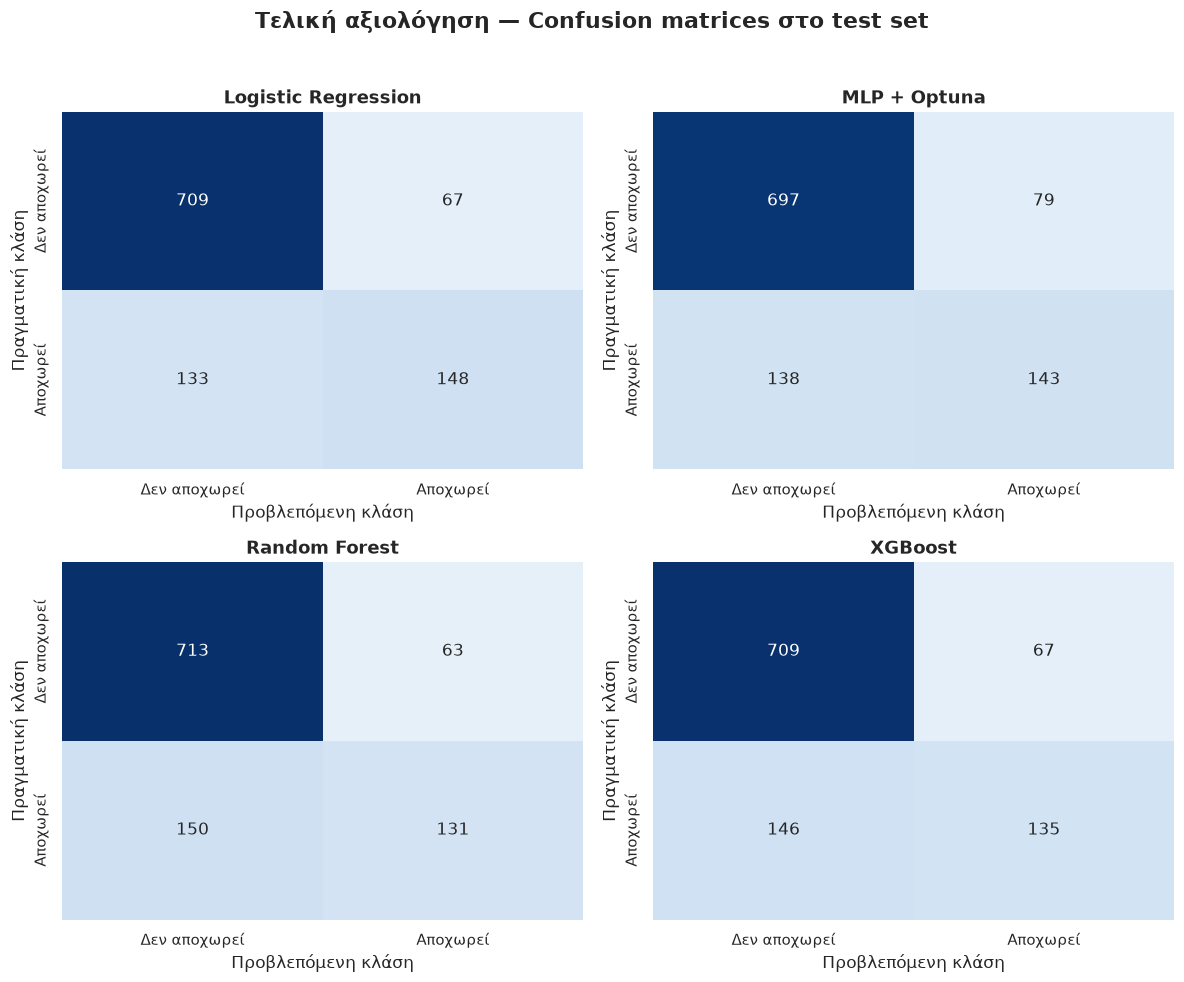

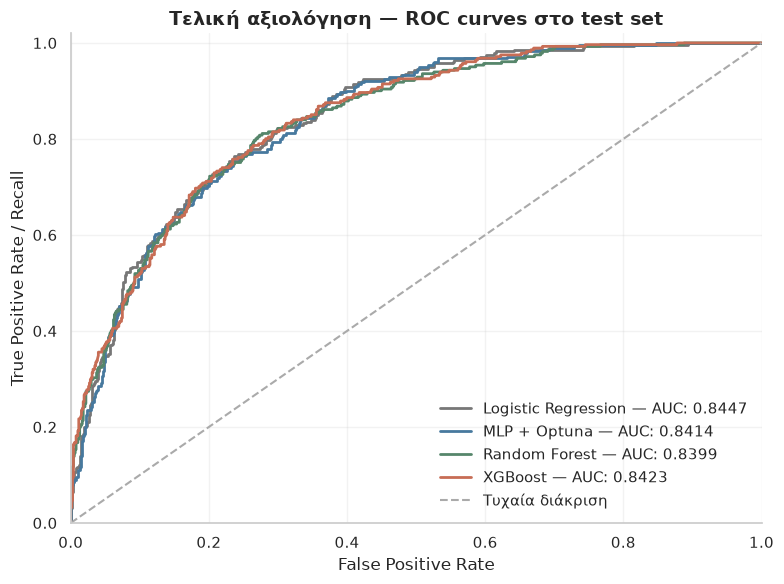

In [32]:
from sklearn.metrics import confusion_matrix, roc_curve

# 1. Προεπεξεργασία test set με τον υπάρχοντα preprocessor
# Χρησιμοποιούμε transform — ποτέ fit ή fit_transform εδώ.
X_test_processed = preprocessor.transform(X_test)

# Πυκνός πίνακας float32 για τα μοντέλα που εκπαιδεύτηκαν
# με τις εισόδους X_train_nn.
if hasattr(X_test_processed, "toarray"):
    X_test_nn = X_test_processed.toarray().astype(np.float32)
else:
    X_test_nn = np.asarray(X_test_processed, dtype=np.float32)

test_targets = np.asarray(y_test).ravel()
FINAL_THRESHOLD = 0.50  # Κοινό κατώφλι για την τελική σύγκριση.

print("Πελάτες στο test set:", len(test_targets))
print("Χαρακτηριστικά εισόδου:", X_test_nn.shape[1])
print("Κοινό κατώφλι:", FINAL_THRESHOLD)

# 2. Πιθανότητες από τα σταθερά εκπαιδευμένα μοντέλα
baseline_positive_index = list(
    baseline_model.classes_
).index(1)

rf_positive_index = list(rf_model.classes_).index(1)
xgb_positive_index = list(xgb_model.classes_).index(1)

test_probabilities = {
    "Logistic Regression": baseline_model.predict_proba(
        X_test_processed
    )[:, baseline_positive_index],

    "MLP + Optuna": tuned_model.predict(
        X_test_nn,
        verbose=0
    ).ravel(),  # Μετατρέπουμε την έξοδο σε μία απλή σειρά τιμών.

    "Random Forest": rf_model.predict_proba(
        X_test_nn
    )[:, rf_positive_index],

    "XGBoost": xgb_model.predict_proba(
        X_test_nn,
        iteration_range=(0, int(xgb_model.best_iteration) + 1)
    )[:, xgb_positive_index]
}

# 3. Μετρικές και confusion matrices
test_rows = []
test_predictions = {}
test_confusion_matrices = {}
test_error_rows = []

for model_name, probabilities in test_probabilities.items():
    predictions = (
        probabilities >= FINAL_THRESHOLD
    ).astype(int)  # Το False γίνεται 0 και το True γίνεται 1.

    test_predictions[model_name] = predictions

    test_rows.append(
        {
            "Model": model_name,
            "Accuracy": accuracy_score(test_targets, predictions),
            "Precision": precision_score(
                test_targets, predictions, zero_division=0
            ),
            "Recall": recall_score(
                test_targets, predictions, zero_division=0
            ),
            "F1-score": f1_score(
                test_targets, predictions, zero_division=0
            ),
            "ROC-AUC": roc_auc_score(
                test_targets, probabilities
            )
        }
    )

    cm = confusion_matrix(
        test_targets,
        predictions,
        labels=[0, 1]  # Σειρά κλάσεων: παραμονή πρώτα, αποχώρηση μετά.
    )

    test_confusion_matrices[model_name] = cm
    tn, fp, fn, tp = cm.ravel()

    test_error_rows.append(
        {
            "Model": model_name,
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp)
        }
    )

test_comparison_df = pd.DataFrame(
    test_rows
).set_index("Model")

test_errors_df = pd.DataFrame(
    test_error_rows
).set_index("Model")

print("\nΤελική σύγκριση στο test set — κατώφλι 0,50")
display(test_comparison_df.round(4))

print("\nΑριθμοί σωστών και λανθασμένων προβλέψεων:")
display(test_errors_df)

# 4. Σύγκριση validation και test επιδόσεων
final_validation_df = pd.DataFrame(
    [
        baseline_results,
        tuned_results,
        rf_results,
        xgb_results
    ]
).set_index("Model")

validation_test_df = pd.DataFrame(
    index=test_comparison_df.index
)

for metric in ["Accuracy", "F1-score", "ROC-AUC"]:
    validation_test_df[f"Validation {metric}"] = (
        final_validation_df[metric]
    )
    validation_test_df[f"Test {metric}"] = (
        test_comparison_df[metric]
    )

print("\nValidation και test επιδόσεις:")
display(validation_test_df.round(4))

# 5. Confusion matrices για τα τέσσερα μοντέλα
fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(12, 10)
)

# Κοινή χρωματική κλίμακα για όλα τα μοντέλα
cm_max = max(
    cm.max() for cm in test_confusion_matrices.values()
)

for ax, (model_name, cm) in zip(
    axes.ravel(),
    test_confusion_matrices.items()
):
    sns.heatmap(
        cm,
        annot=True,  # Γράφουμε την τιμή μέσα σε κάθε τετράγωνο.
        fmt="d",  # Εμφανίζουμε ακέραιους αριθμούς πελατών.
        cmap="Blues",
        cbar=False,
        vmin=0,
        vmax=cm_max,
        xticklabels=["Δεν αποχωρεί", "Αποχωρεί"],
        yticklabels=["Δεν αποχωρεί", "Αποχωρεί"],
        ax=ax
    )

    ax.set_title(model_name, fontsize=13, fontweight="bold")
    ax.set_xlabel("Προβλεπόμενη κλάση")
    ax.set_ylabel("Πραγματική κλάση")

fig.suptitle(
    "Τελική αξιολόγηση — Confusion matrices στο test set",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout(rect=[0, 0, 1, 0.96])

plt.show()  # Εμφανίζουμε το γράφημα μέσα στο notebook.

# 6. Κοινό γράφημα ROC
fig, ax = plt.subplots(figsize=(8, 6))

model_colors = {
    "Logistic Regression": "#777777",
    "MLP + Optuna": "#47799E",
    "Random Forest": "#56866B",
    "XGBoost": "#C76D55"
}

for model_name, probabilities in test_probabilities.items():
    fpr, tpr, _ = roc_curve(
        test_targets,
        probabilities
    )

    model_auc = test_comparison_df.loc[
        model_name, "ROC-AUC"
    ]

    ax.plot(
        fpr,
        tpr,
        color=model_colors[model_name],
        linewidth=2,
        label=f"{model_name} — AUC: {model_auc:.4f}"
    )

ax.plot(
    [0, 1],
    [0, 1],
    color="#AAAAAA",
    linestyle="--",
    linewidth=1.5,
    label="Τυχαία διάκριση"
)

ax.set_title(
    "Τελική αξιολόγηση — ROC curves στο test set",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate / Recall")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.25)
ax.legend(frameon=False, loc="lower right")
sns.despine(ax=ax)

fig.tight_layout()

plt.show()


#### Τελική αξιολόγηση και σύγκριση μοντέλων

Η τελική αξιολόγηση πραγματοποιήθηκε σε 1.057 πελάτες
του test set, από τους οποίους 281 αποχώρησαν και
776 δεν αποχώρησαν. Όλα τα μοντέλα αξιολογήθηκαν
με κατώφλι ταξινόμησης 0,50 και χωρίς περαιτέρω
εκπαίδευση ή αλλαγή υπερπαραμέτρων.

Η Logistic Regression παρουσίασε τις υψηλότερες
τιμές σε όλες τις αναφερόμενες μετρικές:
accuracy 81,08%, precision 68,84%, recall 52,67%,
F1-score 59,68% και ROC-AUC 0,8447.

Το MLP με Optuna πέτυχε accuracy 79,47%,
precision 64,41%, recall 50,89%, F1-score 56,86%
και ROC-AUC 0,8414. Επομένως, η καλύτερη επίδοσή
του στο validation set δεν διατηρήθηκε στο test set.

Το Random Forest και το XGBoost παρουσίασαν
accuracy 79,85%, με F1-score 55,16% και 55,90%,
αντίστοιχα. Το XGBoost είχε τη δεύτερη υψηλότερη
ROC-AUC (0,8423), αλλά χαμηλότερο F1-score
από το MLP με Optuna.

#### Σύγκριση validation και test

Το F1-score της Logistic Regression μειώθηκε
από 61,82% στο validation σε 59,68% στο test,
δηλαδή κατά 2,14 ποσοστιαίες μονάδες.
Η ROC-AUC παρέμεινε σχεδόν ίδια:
0,8453 έναντι 0,8447.

Στο MLP με Optuna, το F1-score μειώθηκε από
62,75% σε 56,86%, δηλαδή κατά 5,89 ποσοστιαίες
μονάδες. Η ROC-AUC μειώθηκε από 0,8482 σε 0,8414.

Το Random Forest παρουσίασε μείωση F1-score
κατά 3,24 ποσοστιαίες μονάδες και το XGBoost
κατά 2,92 ποσοστιαίες μονάδες.

Η μεγαλύτερη πτώση του MLP δείχνει ότι η validation
επίδοση δεν μεταφέρθηκε πλήρως στο ανεξάρτητο δείγμα.
Αυτό μπορεί να σχετίζεται με τη δειγματοληπτική
μεταβλητότητα και με την αισιοδοξία που εισάγει
η επιλογή μεταξύ πολλών ρυθμίσεων στο ίδιο
validation set. Τα αποτελέσματα δεν αρκούν
για να απομονώσουμε μία συγκεκριμένη αιτία.

Η Logistic Regression εμφάνισε μικρότερη μεταβολή
στο F1-score και στη ROC-AUC μεταξύ των δύο συνόλων.
Η εικόνα αυτή είναι συμβατή με σταθερότερη απόδοση
στον συγκεκριμένο διαχωρισμό, χωρίς να αποδεικνύει
γενική υπεροχή του αλγορίθμου.

#### Ανάλυση των σφαλμάτων

Η Logistic Regression αναγνώρισε σωστά 148 από
τις 281 πραγματικές αποχωρήσεις, με 133 false
negatives και 67 false positives.

Το MLP με Optuna αναγνώρισε 143 αποχωρήσεις,
με 138 false negatives και 79 false positives.
Επομένως, η Logistic Regression εντόπισε πέντε
περισσότερες αποχωρήσεις, ενώ παρήγαγε δώδεκα
λιγότερους λανθασμένους συναγερμούς.

Το Random Forest είχε τους λιγότερους λανθασμένους
συναγερμούς (63), αλλά και τις περισσότερες
μη αναγνωρισμένες αποχωρήσεις (150).
Αυτό δείχνει τον περιορισμό μιας αξιολόγησης
που θα επικεντρωνόταν μόνο στα false positives.

Το XGBoost είχε 67 false positives, όσα και
η Logistic Regression, αλλά αναγνώρισε 135
αποχωρήσεις έναντι 148 της Logistic Regression.

Ακόμη και το μοντέλο με το υψηλότερο recall
δεν αναγνώρισε 133 από τις 281 αποχωρήσεις,
περίπου το 47,33%. Συνεπώς, η accuracy άνω
του 80% δεν σημαίνει ότι εντοπίζεται η μεγάλη
πλειονότητα των πελατών που αποχωρούν.

#### Ερμηνεία των ROC curves

Οι ROC curves βρίσκονται κοντά μεταξύ τους
και παρουσιάζουν διασταυρώσεις. Οι ROC-AUC
κυμαίνονται από 0,8399 έως 0,8447, υποδηλώνοντας
παρόμοια συνολική ικανότητα διάκρισης.

Η Logistic Regression έχει την υψηλότερη
παρατηρούμενη ROC-AUC, αλλά δεν υπερέχει
αναγκαστικά σε κάθε σημείο των καμπυλών.
Χωρίς διαστήματα εμπιστοσύνης ή κατάλληλο
στατιστικό έλεγχο, δεν μπορούμε να χαρακτηρίσουμε
τις μικρές διαφορές ως στατιστικά σημαντικές.

#### Συνολικό συμπέρασμα

Στο συγκεκριμένο test set και κατώφλι 0,50,
η Logistic Regression παρουσίασε την καλύτερη
παρατηρούμενη επίδοση στις πέντε μετρικές.
Τα πιο σύνθετα μοντέλα δεν προσέφεραν βελτίωση
έναντι του απλού baseline στην τελική αξιολόγηση.

Το αποτέλεσμα δεν ακυρώνει την ανάπτυξη και
τη βελτιστοποίηση του νευρωνικού δικτύου.
Αναδεικνύει την αξία της σύγκρισης με απλούστερα
μοντέλα και της αξιολόγησης σε ανεξάρτητα δεδομένα.

Τα συμπεράσματα αφορούν τις συγκεκριμένες
υλοποιήσεις, έναν διαχωρισμό δεδομένων και
διαφορετικό εύρος tuning ανά μοντέλο.
Δεν αποτελούν γενική κατάταξη των αλγορίθμων.

Οι ρυθμίσεις παραμένουν οριστικοποιημένες.
Δεν χρησιμοποιούμε τα test αποτελέσματα για
νέα επιλογή κατωφλίου ή υπερπαραμέτρων.

### 20. Επιχειρηματικές επιπτώσεις, περιορισμοί και μελλοντικές βελτιώσεις

#### 20.1. Επιχειρηματική αξιοποίηση των προβλέψεων

Τα μοντέλα μπορούν να υποστηρίξουν την αναγνώριση
πελατών με αυξημένη προβλεπόμενη πιθανότητα αποχώρησης,
ώστε η εταιρεία να οργανώσει στοχευμένες ενέργειες
επικοινωνίας και διατήρησης.

Στην τελική αξιολόγηση, η Logistic Regression
παρουσίασε την καλύτερη παρατηρούμενη απόδοση
στις πέντε μετρικές, με accuracy 81,08%,
F1-score 59,68% και ROC-AUC 0,8447.
Η απλότητά της την καθιστά εύλογη υποψήφια
για περαιτέρω πιλοτική αξιολόγηση.

Ωστόσο, στο κατώφλι 0,50 αναγνώρισε μόνο 148
από τις 281 πραγματικές αποχωρήσεις. Επομένως,
το μοντέλο δεν επαρκεί ως μοναδικός μηχανισμός
εντοπισμού πελατών που χρειάζονται υποστήριξη.

Μια πιθανή εφαρμογή είναι η δημιουργία λίστας
προτεραιότητας για επικοινωνία, βάσει του
προβλεπόμενου κινδύνου και της διαθέσιμης
δυναμικότητας της ομάδας εξυπηρέτησης.
Η πρόβλεψη θα πρέπει να λειτουργεί υποστηρικτικά
και να συνδυάζεται με το ιστορικό εξυπηρέτησης
και τις ανάγκες του πελάτη.

#### 20.2. Κόστος λανθασμένων προβλέψεων

Τα δύο είδη σφάλματος έχουν διαφορετικές συνέπειες:

- False negatives: πελάτες που αποχωρούν αλλά
  δεν αναγνωρίζονται από το μοντέλο. Η εταιρεία
  μπορεί να χάσει την ευκαιρία έγκαιρης επικοινωνίας.
- False positives: πελάτες που χαρακτηρίζονται
  ως πιθανές αποχωρήσεις αλλά δεν αποχωρούν.
  Μπορεί να προκύψουν περιττές επικοινωνίες,
  εκπτώσεις ή κόστος εξυπηρέτησης.

Για τη Logistic Regression καταγράφηκαν
133 false negatives και 67 false positives.
Το Random Forest είχε λιγότερα false positives
(63), αλλά περισσότερα false negatives (150).
Επομένως, η ελαχιστοποίηση ενός μόνο είδους
σφάλματος δεν αρκεί για επιχειρηματική επιλογή.

Η επιλογή κατωφλίου πρέπει να συνδέεται με
το κόστος επικοινωνίας, την αξία του πελάτη
και την πιθανότητα επιτυχίας μιας παρέμβασης.
Η υψηλή πιθανότητα αποχώρησης δεν συνεπάγεται
ότι ο πελάτης μπορεί να διατηρηθεί μέσω προσφοράς.

Στο συμπληρωματικό validation πείραμα του MLP
με Dropout, η μείωση του κατωφλίου από 0,50
σε 0,37 αύξησε το recall από 53,21% σε 72,86%,
αλλά μείωσε την precision από 66,82% σε 56,04%.
Αυτό δείχνει τη μεταβολή της ισορροπίας μεταξύ
εντοπισμού αποχωρήσεων και λανθασμένων συναγερμών.

Το αποτέλεσμα αφορά εκείνο το μοντέλο και
το validation set. Δεν τεκμηριώνει ότι το 0,37
είναι κατάλληλο για τη Logistic Regression
ή ότι είναι οικονομικά βέλτιστο.

#### 20.3. Αξιοποίηση των ευρημάτων SHAP

Η ανάλυση SHAP του MLP με Optuna ανέδειξε
τη διάρκεια παραμονής, τον τύπο συμβολαίου
και τις μηνιαίες χρεώσεις ως σημαντικά στοιχεία
των προβλέψεων στο εξεταζόμενο δείγμα.

Τα ευρήματα υποστηρίζουν τη διερεύνηση ενεργειών όπως:

- Υποστήριξη νέων πελατών κατά τους πρώτους μήνες,
  με έλεγχο εγκατάστασης, ποιότητας υπηρεσίας
  και επίλυσης προβλημάτων.
- Διερεύνηση της ικανοποίησης πελατών με μηνιαία
  συμβόλαια και παρουσίαση κατάλληλων εναλλακτικών.
- Έλεγχος της αντιλαμβανόμενης αξίας των υπηρεσιών
  σε πελάτες με υψηλές μηνιαίες χρεώσεις.
- Επικοινωνία για πιθανά προβλήματα τεχνικής
  υποστήριξης ή χρήσης υπηρεσιών.

Οι ενέργειες αυτές αποτελούν υποθέσεις προς έλεγχο.
Οι τιμές SHAP εξηγούν τη συμπεριφορά του MLP
και δεν αποδεικνύουν ότι μια αλλαγή συμβολαίου
ή χρέωσης θα αποτρέψει την αποχώρηση.

Επιπλέον, οι συγκεκριμένες εξηγήσεις δεν μεταφέρονται
αυτόματα στη Logistic Regression. Αν επιλεγεί εκείνη
για πιλοτική εφαρμογή, χρειάζεται αντίστοιχη
ερμηνεία των δικών της προβλέψεων.

#### 20.4. Περιορισμοί της μελέτης

Η μελέτη βασίζεται σε ένα σύνολο δεδομένων και
έναν διαχωρισμό training, validation και test.
Δεν εξετάστηκε η μεταβλητότητα των αποτελεσμάτων
σε πολλαπλούς διαχωρισμούς ή διαφορετικά seeds.
Δεν υπολογίστηκαν διαστήματα εμπιστοσύνης,
οπότε οι μικρές διαφορές ROC-AUC δεν μπορούν
να χαρακτηριστούν στατιστικά σημαντικές.

Το validation set χρησιμοποιήθηκε επανειλημμένα
για σύγκριση μοντέλων, early stopping και tuning.
Η επιλογή μεταξύ πολλών δοκιμών μπορεί να οδηγήσει
σε αισιόδοξη εκτίμηση της validation επίδοσης.
Η πτώση του F1-score του MLP με Optuna στο test set
αναδεικνύει τη σημασία της ανεξάρτητης αξιολόγησης.

Τα μοντέλα δεν έλαβαν το ίδιο εύρος βελτιστοποίησης.
Το MLP εξετάστηκε με Optuna, το Random Forest
χρησιμοποίησε προκαθορισμένες ρυθμίσεις και
το XGBoost προκαθορισμένες ρυθμίσεις με early stopping.
Επομένως, συγκρίνονται συγκεκριμένες υλοποιήσεις
και όχι οι μέγιστες δυνατότητες κάθε αλγορίθμου.

Η ανάλυση SHAP χρησιμοποίησε 100 validation
παρατηρήσεις και 50 training παρατηρήσεις αναφοράς.
Η προσέγγιση σε επίπεδο μετασχηματισμένων στηλών
μπορεί να επηρεάζεται από συσχετίσεις και μη έγκυρους
συνδυασμούς one-hot χαρακτηριστικών.

Δεν αξιολογήθηκε η βαθμονόμηση των πιθανοτήτων.
Επομένως, μια εκτίμηση 70% δεν έχει επιβεβαιωθεί
ότι αντιστοιχεί σε περίπου 70% πραγματικές αποχωρήσεις
μεταξύ πελατών με παρόμοια πρόβλεψη.

Τέλος, δεν διαθέτουμε στοιχεία για το πραγματικό
κόστος παρεμβάσεων, την αξία κάθε πελάτη ή
την αποτελεσματικότητα προσφορών διατήρησης.
Δεν μπορούμε συνεπώς να υπολογίσουμε αξιόπιστα
το αναμενόμενο οικονομικό όφελος.

#### 20.5. Μελλοντικές βελτιώσεις

Μελλοντική επέκταση μπορεί να περιλαμβάνει:

- Αξιολόγηση με πολλαπλά seeds και κατάλληλη
  διασταυρούμενη επικύρωση, με την προεπεξεργασία
  να εκπαιδεύεται μόνο στα training δεδομένα
  κάθε fold.
- Συγκρίσιμο εύρος tuning για Logistic Regression,
  Random Forest και XGBoost.
- Διαστήματα εμπιστοσύνης για τις μετρικές και
  τις διαφορές μεταξύ μοντέλων.
- Έλεγχο βαθμονόμησης και επιλογή κατωφλίου
  με βάση επιχειρηματικό κόστος ή περιορισμό
  στον αριθμό διαθέσιμων επικοινωνιών.
- Εξέταση της precision–recall curve και της
  Average Precision για συμπληρωματική αξιολόγηση
  της κλάσης αποχώρησης.
- Ερμηνεία σε επίπεδο αρχικών χαρακτηριστικών
  και έλεγχο σταθερότητας των εξηγήσεων SHAP.

Με πραγματικά εταιρικά δεδομένα θα ήταν χρήσιμη
η αξιολόγηση σε μεταγενέστερη χρονική περίοδο,
ώστε να εξεταστεί η απόδοση σε μελλοντικούς πελάτες.
Αν υπήρχαν διαδοχικές παρατηρήσεις χρήσης υπηρεσιών
ανά πελάτη, θα μπορούσαν να εξεταστούν και μοντέλα
ακολουθιών, όπως RNN ή LSTM.

Η αποτελεσματικότητα των παρεμβάσεων διατήρησης
θα μπορούσε να εξεταστεί με ελεγχόμενο πιλοτικό
πείραμα, συγκρίνοντας ομάδες με και χωρίς παρέμβαση.

Οι προτάσεις αυτές αφορούν μελλοντική εργασία.
Το test set που χρησιμοποιήθηκε εδώ δεν πρέπει
να επαναχρησιμοποιηθεί ως ανεξάρτητος τελικός έλεγχος
αν οι νέες επιλογές καθοδηγηθούν από τα αποτελέσματά του.

#### 20.6. Συμπέρασμα

Η εργασία έδειξε ότι η προσθήκη πολυπλοκότητας
και η βελτιστοποίηση ενός νευρωνικού δικτύου
δεν εγγυώνται καλύτερη απόδοση από ένα απλό baseline.

Η Logistic Regression πέτυχε τις υψηλότερες
παρατηρούμενες test μετρικές, ενώ η SHAP ανάλυση
του MLP προσέφερε πληροφορίες για τον τρόπο
με τον οποίο αυτό διαμορφώνει τις προβλέψεις του.

Η πρακτική αξιοποίηση απαιτεί συνδυασμό
προβλεπτικής απόδοσης, ερμηνευσιμότητας,
επιχειρηματικού κόστους και αξιολόγησης
των ίδιων των παρεμβάσεων διατήρησης.

#### Τι μας έδειξε η συμπληρωματική δοκιμή

Σε ξεχωριστή έκδοση δοκιμάστηκε δεύτερη αναζήτηση Optuna με 30 συνδυασμούς. Το validation loss μειώθηκε από 0,41632 σε 0,41500, αλλά το validation F1 στο κατώφλι 0,50 μειώθηκε από 0,6275 σε 0,5984. Στο ήδη εξετασμένο test, το F1 μειώθηκε από 0,5686 σε 0,5339. Η δοκιμή αυτή δεν περιλαμβάνεται στην εκτέλεση της παρούσας έκδοσης, η οποία παρουσιάζει το αρχικό πείραμα.

Η επιλογή να παρουσιάσουμε αυτή την έκδοση έγινε αφού είχαμε δει και τα test αποτελέσματα. Συνεπώς, δεν ισχυριζόμαστε ότι αποτελεί νέα ανεξάρτητη επιβεβαίωση ή ότι το αρχικό MLP θα είναι πάντα καλύτερο. Για τέτοιο συμπέρασμα χρειάζονται νέα δεδομένα. Η χαμηλότερη τιμή loss δεν εγγυάται υψηλότερο F1 σε ένα συγκεκριμένο κατώφλι.
